## Hito 2 (Examen): Sistema integrado de supervisión del cumplimiento de Elementos de Protección Personal (EPP) mediante Inteligencia Artificial

**Integrantes** <br>
Catalina Cornejo<br>
Hellen Quiñones<br>
Gustavo Sanchez


### Objetivo del proyecto

Desarrollar un sistema de inteligencia artificial basado en YOLO para detectar elementos de protección personal (EPP) en imágenes de entornos laborales, con el propósito de apoyar la identificación de posibles incumplimientos de seguridad según las exigencias de cada zona de trabajo.

El sistema utilizará técnicas de visión por computador para identificar los objetos presentes en una imagen. Posteriormente, sus resultados podrán integrarse con reglas de seguridad, herramientas de IA generativa y un flujo de automatización que permita informar posibles riesgos a un responsable de prevención.

### Dataset seleccionado

Se utilizará el dataset público **SH17: Dataset for PPE Detection**, disponible en Kaggle:

https://www.kaggle.com/datasets/mugheesahmad/sh17-dataset-for-ppe-detection

### **0. Configuración del entorno de trabajo para el Hito 2**

Para desarrollar el Hito 2 se establece un directorio independiente en Google Drive, con el propósito de preservar los archivos, modelos entrenados, datasets y resultados obtenidos durante el Hito 1.

La carpeta `Certamen2_IA` se mantendrá como respaldo del trabajo anterior y podrá utilizarse únicamente como fuente de lectura cuando sea necesario recuperar modelos o resultados.

Los nuevos entrenamientos, evaluaciones, modelos exportados y archivos asociados al sistema integrado se almacenarán en `Examen_Hito2_EPP`.

Esta separación permite realizar experimentos, implementar mejoras y comparar versiones sin sobrescribir los resultados originales del proyecto.






In [2]:
# ============================================================
# 0. CONFIGURACIÓN DEL ENTORNO DEL HITO 2
# ============================================================

from google.colab import drive
from pathlib import Path

# 1. Conectar Google Drive
drive.mount("/content/drive")

# 2. Definir carpetas principales
CARPETA_HITO1 = Path(
    "/content/drive/MyDrive/Certamen2_IA"
)

CARPETA_HITO2 = Path(
    "/content/drive/MyDrive/Examen_Hito2_EPP"
)

# 3. Verificar que ambas rutas sean independientes
assert CARPETA_HITO1 != CARPETA_HITO2
assert CARPETA_HITO1 not in CARPETA_HITO2.parents

# 4. Crear directorio del Hito 2
CARPETA_HITO2.mkdir(
    parents=True,
    exist_ok=True
)

# 5. Definir subcarpetas de trabajo
SUBCARPETAS = [
    "Datasets",
    "Entrenamientos_YOLO",
    "Evaluaciones",
    "Modelos_Exportados",
    "API",
    "Series_Temporales",
    "Textos_NLP",
    "Tablero",
    "Resultados"
]

for nombre in SUBCARPETAS:
    carpeta = CARPETA_HITO2 / nombre
    carpeta.mkdir(
        parents=True,
        exist_ok=True
    )

# 6. Mostrar las rutas configuradas
print("CONFIGURACIÓN DEL HITO 2 COMPLETADA")

print("\nCarpeta original del Hito 1:")
print(CARPETA_HITO1)

print("\nCarpeta independiente del Hito 2:")
print(CARPETA_HITO2)

print("\nSubcarpetas disponibles:")

for nombre in SUBCARPETAS:
    print("-", nombre)

print("\nLos archivos originales del Hito 1 no fueron modificados.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CONFIGURACIÓN DEL HITO 2 COMPLETADA

Carpeta original del Hito 1:
/content/drive/MyDrive/Certamen2_IA

Carpeta independiente del Hito 2:
/content/drive/MyDrive/Examen_Hito2_EPP

Subcarpetas disponibles:
- Datasets
- Entrenamientos_YOLO
- Evaluaciones
- Modelos_Exportados
- API
- Series_Temporales
- Textos_NLP
- Tablero
- Resultados

Los archivos originales del Hito 1 no fueron modificados.


## **1. Preparación y exploración del dataset**

Se prepara un subconjunto reducido y representativo del dataset original para disminuir los recursos computacionales necesarios durante el entrenamiento de YOLO.

La selección buscará:

- Conservar todas las imágenes que contengan categorías minoritarias, según el criterio que se defina después del análisis.
- Seleccionar imágenes adicionales de las categorías mayoritarias de manera balanceada.
- Mantener las anotaciones originales de las imágenes seleccionadas.
- Conservar una separación adecuada entre entrenamiento, validación y prueba.
- Generar un dataset compatible con YOLO.

La preparación comenzará con la exploración de los archivos y la distribución de categorías. No se realizará ningún recorte del dataset antes de conocer su estructura y composición.


### 1.1. Instalación de librerías

Se instalan las librerías necesarias para descargar, explorar y analizar el dataset SH17.

Se utilizará `kagglehub` para acceder al conjunto de datos, `pandas` para organizar los resultados, `NumPy` para operaciones numéricas, `Matplotlib` para visualizaciones y `PyYAML` para leer archivos de configuración.


In [3]:
# Instalación de librerías para trabajar con el dataset
%pip -q install kagglehub pandas pyyaml matplotlib pillow



### 1.2. Descarga y localización del dataset SH17

Se descarga el dataset SH17 desde Kaggle o se utiliza una copia local si ya se encuentra disponible.Para garantizar la reproducibilidad, se establece una semilla aleatoria = 2026

Luego, una vez localizado el dataset, se muestran los archivos y carpetas principales para comprobar que la descarga se haya realizado correctamente.

*Durante este procedimiento no se modifican ni eliminan archivos originales.*


In [4]:

import kagglehub
from pathlib import Path
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Semilla para reproducir los resultados
SEMILLA = 2026
random.seed(SEMILLA)
np.random.seed(SEMILLA)

# Dataset seleccionado
DATASET_SLUG = "mugheesahmad/sh17-dataset-for-ppe-detection"

# Si ya tienes el dataset descomprimido, coloca aquí su ruta.
# De lo contrario, se descargará desde Kaggle.
RUTA_LOCAL = None

if RUTA_LOCAL is not None:
    ruta = Path(RUTA_LOCAL)
else:
    ruta_kaggle = Path(
        "/kaggle/input/sh17-dataset-for-ppe-detection"
    )

    if ruta_kaggle.exists():
        ruta = ruta_kaggle
    else:
        ruta = Path(
            kagglehub.dataset_download(DATASET_SLUG)
        )

assert ruta.exists(), "No se encontró el dataset."

print("Dataset ubicado en:", ruta)
print("\nContenido principal:")

for archivo in sorted(ruta.iterdir()):
    print("-", archivo.name)


Dataset ubicado en: /kaggle/input/sh17-dataset-for-ppe-detection

Contenido principal:
- images
- labels
- meta-data
- train_files.txt
- val_files.txt
- voc_labels



### 1.3. Exploración de la estructura del dataset

Se examina la organización de carpetas y archivos del dataset SH17 para identificar dónde se encuentran las imágenes, las anotaciones y los archivos de configuración.

Se realiza un recuento preliminar de los archivos de imagen, archivos TXT y configuraciones YAML, con el objetivo de comprender cómo están almacenados los datos.

Esta exploración permitirá determinar las rutas que se utilizarán en las siguientes etapas y verificar el formato de las anotaciones.

Una vez identificada la estructura, se analizará la cantidad de imágenes y objetos asociados a cada clase para definir una estrategia de selección balanceada.


In [5]:

# Revisamos los primeros niveles de carpetas del dataset

print("ESTRUCTURA DEL DATASET SH17\n")

for ubicacion, subcarpetas, archivos in os.walk(ruta):
    carpeta = Path(ubicacion)
    nivel = len(carpeta.relative_to(ruta).parts)

    # Mostrar máximo tres niveles
    if nivel > 3:
        subcarpetas[:] = []
        continue

    espacio = "  " * nivel

    print(f"{espacio}{carpeta.name}/")
    print(f"{espacio}  Cantidad de archivos: {len(archivos)}")

    # Ejemplos de archivos
    for archivo in sorted(archivos)[:4]:
        print(f"{espacio}  - {archivo}")

# Identificamos archivos relevantes
extensiones = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

imagenes = sorted(
    p for p in ruta.rglob("*")
    if p.is_file() and p.suffix.lower() in extensiones
)

etiquetas = sorted(ruta.rglob("*.txt"))
configuraciones = sorted(
    p for p in ruta.rglob("*")
    if p.is_file() and p.suffix.lower() in {".yaml", ".yml"}
)

print("\nRESUMEN PRELIMINAR")
print("Archivos de imagen:", len(imagenes))
print("Archivos TXT:", len(etiquetas))

print("\nArchivos YAML encontrados:")
for archivo in configuraciones[:15]:
    print("-", archivo.relative_to(ruta))


ESTRUCTURA DEL DATASET SH17

sh17-dataset-for-ppe-detection/
  Cantidad de archivos: 2
  - train_files.txt
  - val_files.txt
  labels/
    Cantidad de archivos: 8099
    - building-construction-building-site-constructing.txt
    - career-firefighter-relaxing-job-162540.txt
    - carrying-head-indian-farm-worker-158011.txt
    - construction-site-build-construction-work-159306.txt
  images/
    Cantidad de archivos: 8099
    - building-construction-building-site-constructing.jpg
    - career-firefighter-relaxing-job-162540.jpeg
    - carrying-head-indian-farm-worker-158011.jpeg
    - construction-site-build-construction-work-159306.jpeg
  meta-data/
    Cantidad de archivos: 8099
    - building-construction-building-site-constructing.json
    - career-firefighter-relaxing-job-162540.json
    - carrying-head-indian-farm-worker-158011.json
    - construction-site-build-construction-work-159306.json
  voc_labels/
    Cantidad de archivos: 8099
    - building-construction-building-site-cons


### 1.4. Identificación de clases y análisis de distribución

Se identifican las 17 categorías del dataset SH17 utilizando los identificadores definidos en el archivo `sh17.yaml` oficial.

Posteriormente, se recorren las anotaciones YOLO para calcular:

- La cantidad de imágenes que contienen cada categoría.
- La cantidad total de objetos anotados por categoría.
- La existencia de etiquetas faltantes o incorrectas.
- La distribución de las clases mediante un gráfico de barras.

Este análisis es fundamental para identificar las categorías minoritarias y establecer un criterio de selección balanceada.

Es importante considerar que una imagen puede contener objetos de múltiples categorías. Por ello, el número total de imágenes contabilizadas por clase puede superar la cantidad de fotografías del dataset.

Los resultados permitirán diseñar un subconjunto de entrenamiento que conserve la representación de las clases menos frecuentes, sin modificar las anotaciones originales.


DISTRIBUCIÓN DE CLASES SH17


,ID,Clase,Imágenes,Objetos
0,13,medical-suit,98,137
1,4,face-guard,127,133
2,15,safety-suit,135,232
3,16,safety-vest,208,519
4,2,ear-mufs,220,314
5,6,foot,343,749
6,5,face-mask,393,666
7,10,helmet,465,924
8,9,gloves,1311,2754
9,14,shoes,1556,4489



RESUMEN DE VALIDACIÓN
Total de imágenes: 8099
Objetos válidos: 73810
Etiquetas faltantes: 0
Etiquetas inválidas: 2184
Imágenes sin objetos válidos: 18

Ejemplos de errores:
('pexels-photo-10341095.jpeg', 6, 'Coordenadas fuera de rango')
('pexels-photo-10341095.jpeg', 7, 'Coordenadas fuera de rango')
('pexels-photo-10341095.jpeg', 8, 'Coordenadas fuera de rango')
('pexels-photo-10341096.jpeg', 5, 'Coordenadas fuera de rango')
('pexels-photo-10341105.jpeg', 3, 'Coordenadas fuera de rango')


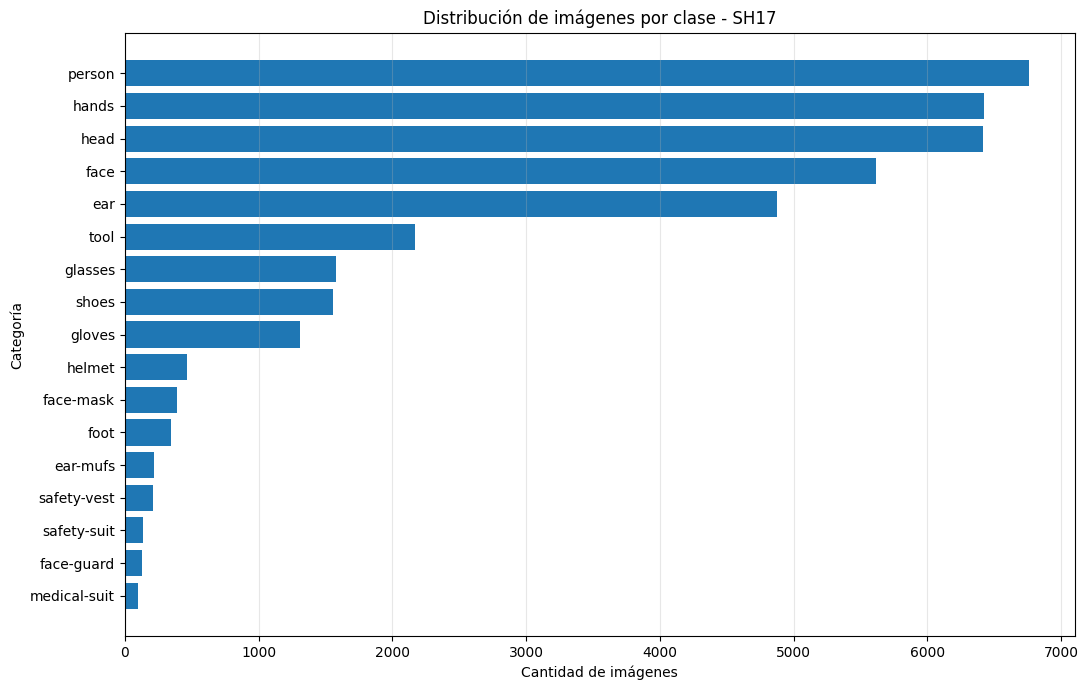

In [6]:

from collections import Counter

# Clases oficiales de SH17 según sh17.yaml
CLASES = {
    0: "person",
    1: "ear",
    2: "ear-mufs",
    3: "face",
    4: "face-guard",
    5: "face-mask",
    6: "foot",
    7: "tool",
    8: "glasses",
    9: "gloves",
    10: "helmet",
    11: "hands",
    12: "head",
    13: "medical-suit",
    14: "shoes",
    15: "safety-suit",
    16: "safety-vest"
}

# Contadores de imágenes y objetos por categoría
imagenes_por_clase = Counter()
objetos_por_clase = Counter()

# Guardaremos las clases presentes en cada imagen
clases_por_imagen = {}

etiquetas_faltantes = []
etiquetas_invalidas = []
imagenes_sin_objetos = 0

# Recorremos las imágenes del dataset
for imagen in imagenes:

    archivo_label = ruta / "labels" / f"{imagen.stem}.txt"
    clases_presentes = set()

    if not archivo_label.exists():
        etiquetas_faltantes.append(imagen.name)
        continue

    with open(archivo_label, "r", encoding="utf-8") as f:
        lineas = f.readlines()

    objetos_validos = 0

    for numero_linea, linea in enumerate(lineas, start=1):

        datos = linea.strip().split()

        if not datos:
            continue

        try:
            # YOLO detección: clase x_centro y_centro ancho alto
            if len(datos) != 5:
                raise ValueError("Formato incorrecto")

            clase_id = int(datos[0])
            coordenadas = [float(v) for v in datos[1:]]

            if clase_id not in CLASES:
                raise ValueError("Clase desconocida")

            x, y, ancho, alto = coordenadas

            if not (
                0 <= x <= 1 and
                0 <= y <= 1 and
                0 < ancho <= 1 and
                0 < alto <= 1 and
                0 <= x - ancho / 2 <= 1 and
                0 <= x + ancho / 2 <= 1 and
                0 <= y - alto / 2 <= 1 and
                0 <= y + alto / 2 <= 1
            ):
                raise ValueError("Coordenadas fuera de rango")

            objetos_por_clase[clase_id] += 1
            clases_presentes.add(clase_id)
            objetos_validos += 1

        except (ValueError, TypeError) as error:
            etiquetas_invalidas.append(
                (imagen.name, numero_linea, str(error))
            )

    # Cada clase se cuenta una sola vez por fotografía
    for clase_id in clases_presentes:
        imagenes_por_clase[clase_id] += 1

    clases_por_imagen[imagen.name] = clases_presentes

    if objetos_validos == 0:
        imagenes_sin_objetos += 1

# Tabla resumen
df_clases = pd.DataFrame([
    {
        "ID": id_clase,
        "Clase": nombre,
        "Imágenes": imagenes_por_clase[id_clase],
        "Objetos": objetos_por_clase[id_clase]
    }
    for id_clase, nombre in CLASES.items()
])

# De menor a mayor frecuencia
df_clases = df_clases.sort_values(
    "Imágenes", ascending=True
).reset_index(drop=True)

print("DISTRIBUCIÓN DE CLASES SH17")
display(df_clases)

print("\nRESUMEN DE VALIDACIÓN")
print("Total de imágenes:", len(imagenes))
print("Objetos válidos:", sum(objetos_por_clase.values()))
print("Etiquetas faltantes:", len(etiquetas_faltantes))
print("Etiquetas inválidas:", len(etiquetas_invalidas))
print("Imágenes sin objetos válidos:", imagenes_sin_objetos)

if etiquetas_invalidas:
    print("\nEjemplos de errores:")
    for error in etiquetas_invalidas[:5]:
        print(error)

# Gráfico de distribución
plt.figure(figsize=(11, 7))

plt.barh(
    df_clases["Clase"],
    df_clases["Imágenes"]
)

plt.xlabel("Cantidad de imágenes")
plt.ylabel("Categoría")
plt.title("Distribución de imágenes por clase - SH17")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()



### 1.5. Verificación de los conjuntos de entrenamiento y validación

Se revisan los archivos `train_files.txt` y `val_files.txt`, que contienen la distribución original de imágenes del dataset SH17.

El objetivo es comprobar:

- La cantidad de imágenes asignadas a entrenamiento y validación.
- La existencia de imágenes duplicadas entre ambos conjuntos.
- La correspondencia entre los nombres registrados y los archivos disponibles.
- La representación de cada clase dentro de ambas particiones.

Se conservará la separación original mientras se diseña el subconjunto reducido. Esto permitirá evitar la fuga de información entre entrenamiento y evaluación.

La selección balanceada se realizará posteriormente sobre el conjunto de entrenamiento, sin utilizar imágenes de validación para entrenar el modelo.


In [7]:

from collections import Counter, defaultdict

# Archivos originales de partición
archivo_train = ruta / "train_files.txt"
archivo_val = ruta / "val_files.txt"

# Índice de imágenes disponibles
imagenes_por_nombre = {p.name: p for p in imagenes}

imagenes_por_stem = defaultdict(list)
for p in imagenes:
    imagenes_por_stem[p.stem].append(p.name)


def leer_particion(archivo):
    """Lee una lista de imágenes y verifica su existencia."""

    with open(archivo, "r", encoding="utf-8-sig") as f:
        lineas = [
            linea.strip().strip('"').strip("'")
            for linea in f
            if linea.strip()
        ]

    encontrados = []
    faltantes = []
    ambiguos = []

    for entrada in lineas:
        # Admite nombres y rutas de Windows o Linux
        nombre = entrada.replace("\\", "/").split("/")[-1]

        if nombre in imagenes_por_nombre:
            encontrados.append(nombre)

        elif nombre in imagenes_por_stem:
            candidatos = imagenes_por_stem[nombre]

            if len(candidatos) == 1:
                encontrados.append(candidatos[0])
            else:
                ambiguos.append(entrada)

        else:
            faltantes.append(entrada)

    return lineas, encontrados, faltantes, ambiguos


# Lectura de ambos conjuntos
lineas_train, lista_train, faltantes_train, ambiguos_train = (
    leer_particion(archivo_train)
)

lineas_val, lista_val, faltantes_val, ambiguos_val = (
    leer_particion(archivo_val)
)

train = set(lista_train)
val = set(lista_val)

# Comprobaciones
repetidas_train = len(lista_train) - len(train)
repetidas_val = len(lista_val) - len(val)
interseccion = train & val

todas = set(imagenes_por_nombre.keys())
sin_asignar = todas - (train | val)

print("VERIFICACIÓN DE PARTICIONES SH17\n")

print("Entrenamiento:", len(train), "imágenes")
print("Validación:", len(val), "imágenes")
print("Total asignadas:", len(train | val))
print("Total del dataset:", len(todas))

print("\nCONTROL DE INTEGRIDAD")
print("Duplicadas dentro de train:", repetidas_train)
print("Duplicadas dentro de val:", repetidas_val)
print("Compartidas entre train y val:", len(interseccion))
print("No encontradas en el dataset:",
      len(faltantes_train) + len(faltantes_val))
print("Nombres ambiguos:",
      len(ambiguos_train) + len(ambiguos_val))
print("Imágenes sin partición:", len(sin_asignar))

# Distribución de imágenes por clase y partición
def contar_clases(nombres):
    contador = Counter()

    for nombre in nombres:
        for clase_id in clases_por_imagen.get(nombre, set()):
            contador[clase_id] += 1

    return contador


conteo_train = contar_clases(train)
conteo_val = contar_clases(val)

df_particiones = pd.DataFrame([
    {
        "Clase": nombre,
        "Train": conteo_train[id_clase],
        "Val": conteo_val[id_clase],
        "Total": imagenes_por_clase[id_clase]
    }
    for id_clase, nombre in CLASES.items()
])

df_particiones = df_particiones.sort_values(
    "Total", ascending=True
).reset_index(drop=True)

print("\nDISTRIBUCIÓN POR CLASE Y PARTICIÓN")
display(df_particiones)

# Conclusión de la verificación
integridad_ok = (
    repetidas_train == 0
    and repetidas_val == 0
    and len(interseccion) == 0
    and len(faltantes_train) == 0
    and len(faltantes_val) == 0
    and len(ambiguos_train) == 0
    and len(ambiguos_val) == 0
    and len(sin_asignar) == 0
)

if integridad_ok:
    print("\nPARTICIONES VERIFICADAS CORRECTAMENTE")
else:
    print("\nATENCIÓN: revisar las inconsistencias detectadas")

    print("Ejemplos de archivos faltantes:",
          (faltantes_train + faltantes_val)[:5])

    print("Ejemplos de imágenes compartidas:",
          sorted(interseccion)[:5])


VERIFICACIÓN DE PARTICIONES SH17

Entrenamiento: 6479 imágenes
Validación: 1620 imágenes
Total asignadas: 8099
Total del dataset: 8099

CONTROL DE INTEGRIDAD
Duplicadas dentro de train: 0
Duplicadas dentro de val: 0
Compartidas entre train y val: 0
No encontradas en el dataset: 0
Nombres ambiguos: 0
Imágenes sin partición: 0

DISTRIBUCIÓN POR CLASE Y PARTICIÓN


,Clase,Train,Val,Total
0,medical-suit,70,28,98
1,face-guard,104,23,127
2,safety-suit,109,26,135
3,safety-vest,163,45,208
4,ear-mufs,182,38,220
5,foot,280,63,343
6,face-mask,318,75,393
7,helmet,372,93,465
8,gloves,1058,253,1311
9,shoes,1237,319,1556



PARTICIONES VERIFICADAS CORRECTAMENTE



### 1.6. Diagnóstico de anotaciones inválidas

Durante la exploración inicial se identificaron 2.184 anotaciones que no cumplieron las condiciones de validación establecidas para las cajas delimitadoras.

En esta etapa se analizarán dichas anotaciones para determinar:

- Cuántas presentan coordenadas fuera del rango normalizado.
- Cuántas corresponden a cajas que sobrepasan los bordes de la imagen.
- Qué categorías concentran la mayor cantidad de problemas.
- Cómo se distribuyen los errores entre entrenamiento y validación.

Este diagnóstico permitirá establecer una estrategia de limpieza antes de generar el subconjunto reducido.

No se modificarán ni eliminarán anotaciones durante esta etapa, ya que primero es necesario comprender la naturaleza y magnitud de los errores.


In [8]:

import math
from pathlib import Path
import pandas as pd

# Identificación de las particiones
train_stems = {Path(nombre).stem for nombre in train}
val_stems = {Path(nombre).stem for nombre in val}

# Variables para registrar problemas
errores = []
total_anotaciones = 0
anotaciones_validas = 0

# Recorremos todas las etiquetas
for archivo in sorted((ruta / "labels").glob("*.txt")):

    if archivo.stem in train_stems:
        conjunto = "Train"
    elif archivo.stem in val_stems:
        conjunto = "Val"
    else:
        conjunto = "Sin asignar"

    with open(archivo, "r", encoding="utf-8") as f:
        lineas = f.readlines()

    for numero_linea, linea in enumerate(lineas, start=1):

        datos = linea.strip().split()

        if not datos:
            continue

        total_anotaciones += 1

        motivo = None
        clase_id = None
        exceso = None

        if len(datos) != 5:
            motivo = "Formato incorrecto"

        else:
            try:
                clase_id = int(datos[0])
                x, y, w, h = map(float, datos[1:])

                if not all(math.isfinite(v) for v in (x, y, w, h)):
                    motivo = "Valores no finitos"

                elif clase_id not in CLASES:
                    motivo = "ID de clase desconocido"

                elif not (
                    0 <= x <= 1 and
                    0 <= y <= 1 and
                    0 < w <= 1 and
                    0 < h <= 1
                ):
                    motivo = "Valores normalizados fuera de rango"

                else:
                    # Límites reales de la caja
                    x_min = x - w / 2
                    x_max = x + w / 2
                    y_min = y - h / 2
                    y_max = y + h / 2

                    # Magnitud máxima fuera de la imagen
                    exceso = max(
                        0,
                        -x_min,
                        x_max - 1,
                        -y_min,
                        y_max - 1
                    )

                    if exceso > 0:
                        motivo = "Caja sobrepasa los bordes"

            except ValueError:
                motivo = "Datos no numéricos"

        if motivo is None:
            anotaciones_validas += 1
        else:
            errores.append({
                "Imagen": archivo.stem,
                "Conjunto": conjunto,
                "Línea": numero_linea,
                "Clase": CLASES.get(clase_id, "Desconocida"),
                "Motivo": motivo,
                "Exceso": exceso,
                "Anotación": linea.strip()
            })


# Resultados
df_errores = pd.DataFrame(errores)

print("DIAGNÓSTICO DE ANOTACIONES SH17\n")

print("Total de anotaciones:", total_anotaciones)
print("Anotaciones válidas:", anotaciones_validas)
print("Anotaciones con problemas:", len(errores))

if not df_errores.empty:

    print("\n1. TIPOS DE PROBLEMAS")
    display(
        df_errores["Motivo"]
        .value_counts()
        .rename_axis("Motivo")
        .reset_index(name="Cantidad")
    )

    print("\n2. ERRORES POR CONJUNTO")
    display(
        pd.crosstab(
            df_errores["Conjunto"],
            df_errores["Motivo"]
        )
    )

    print("\n3. ERRORES POR CLASE")
    display(
        df_errores["Clase"]
        .value_counts()
        .rename_axis("Clase")
        .reset_index(name="Cantidad")
    )

    print("\n4. IMÁGENES AFECTADAS")
    print(df_errores["Imagen"].nunique())

    print("\n5. EJEMPLOS DE ANOTACIONES PROBLEMÁTICAS")
    display(df_errores.head(10))

    cajas_fuera = df_errores[
        df_errores["Motivo"] == "Caja sobrepasa los bordes"
    ]

    if not cajas_fuera.empty:
        print("\n6. MAGNITUD DEL EXCESO DE LAS CAJAS")
        display(cajas_fuera["Exceso"].describe())


DIAGNÓSTICO DE ANOTACIONES SH17

Total de anotaciones: 75994
Anotaciones válidas: 73810
Anotaciones con problemas: 2184

1. TIPOS DE PROBLEMAS


,Motivo,Cantidad
0,Caja sobrepasa los bordes,2184



2. ERRORES POR CONJUNTO


Motivo,Caja sobrepasa los bordes
Conjunto,
Train,1753
Val,431



3. ERRORES POR CLASE


,Clase,Cantidad
0,person,1477
1,head,173
2,tool,153
3,hands,141
4,shoes,71
5,face,40
6,gloves,36
7,medical-suit,20
8,ear,16
9,glasses,16



4. IMÁGENES AFECTADAS
1846

5. EJEMPLOS DE ANOTACIONES PROBLEMÁTICAS


,Imagen,Conjunto,Línea,Clase,Motivo,Exceso,Anotación
0,pexels-photo-10341095,Train,6,hands,Caja sobrepasa los bordes,5.000000e-07,11 0.954167 0.714784 0.091667 0.210817
1,pexels-photo-10341095,Train,7,person,Caja sobrepasa los bordes,5.000000e-07,0 0.775641 0.524159 0.445833 0.951683
2,pexels-photo-10341095,Train,8,person,Caja sobrepasa los bordes,5.000000e-07,0 0.247035 0.704087 0.318429 0.591827
3,pexels-photo-10341096,Val,5,person,Caja sobrepasa los bordes,5.000000e-07,0 0.559328 0.534271 0.881345 0.931458
4,pexels-photo-10341105,Train,3,person,Caja sobrepasa los bordes,5.000000e-07,0 0.532341 0.500166 0.536564 0.999669
5,pexels-photo-10341122,Val,2,head,Caja sobrepasa los bordes,5.000000e-07,12 0.639904 0.102764 0.288782 0.205529
6,pexels-photo-10347147,Train,4,person,Caja sobrepasa los bordes,5.000000e-07,0 0.829728 0.508413 0.340545 0.983173
7,pexels-photo-10375931,Train,15,person,Caja sobrepasa los bordes,5.000000e-07,0 0.231125 0.716201 0.221572 0.567599
8,pexels-photo-10375933,Train,13,person,Caja sobrepasa los bordes,5.000000e-07,0 0.717039 0.566964 0.565923 0.866071
9,pexels-photo-10375945,Val,1,head,Caja sobrepasa los bordes,5.000000e-07,12 0.936161 0.177902 0.127679 0.313393



6. MAGNITUD DEL EXCESO DE LAS CAJAS


,Exceso
count,2.184000e+03
mean,5.000000e-07
std,3.696021e-17
min,5.000000e-07
25%,5.000000e-07
50%,5.000000e-07
75%,5.000000e-07
max,5.000000e-07



### 1.7. Validación definitiva y actualización de la distribución de clases

El diagnóstico identificó 2.184 anotaciones cuyos límites superaban el rango permitido en 0,0000005 unidades normalizadas.

Debido a que esta diferencia es compatible con el redondeo de coordenadas decimales, se establece una tolerancia de 0,000001 para validar los límites de las cajas.

Con este ajuste se busca conservar las anotaciones originales, evitando eliminar información por diferencias numéricas insignificantes.

Posteriormente, se recalcula la distribución de imágenes y objetos por categoría, considerando únicamente las anotaciones aceptadas mediante el nuevo criterio.

Con ello,esta distribución actualizada será la base para seleccionar el subconjunto balanceado del dataset SH17.


In [9]:

from collections import Counter
import math
import pandas as pd

# Tolerancia para pequeños errores de redondeo
TOLERANCIA = 1e-6

# Conservamos los conteos anteriores para comparar
conteo_anterior = Counter(imagenes_por_clase)

# Reiniciamos los contadores
imagenes_por_clase = Counter()
objetos_por_clase = Counter()
clases_por_imagen = {}

errores_restantes = []
total_anotaciones = 0
imagenes_sin_objetos = 0

for imagen in imagenes:

    archivo_label = ruta / "labels" / f"{imagen.stem}.txt"
    clases_presentes = set()
    objetos_imagen = 0

    if not archivo_label.exists():
        errores_restantes.append(
            (imagen.name, "Etiqueta faltante")
        )
        continue

    with open(archivo_label, "r", encoding="utf-8") as f:
        lineas = f.readlines()

    for num_linea, linea in enumerate(lineas, 1):

        datos = linea.strip().split()

        if not datos:
            continue

        total_anotaciones += 1

        try:
            if len(datos) != 5:
                raise ValueError("Formato incorrecto")

            clase_id = int(datos[0])
            x, y, w, h = map(float, datos[1:])

            if clase_id not in CLASES:
                raise ValueError("Clase desconocida")

            if not all(math.isfinite(v) for v in (x, y, w, h)):
                raise ValueError("Valores no finitos")

            if not (
                0 <= x <= 1 and
                0 <= y <= 1 and
                0 < w <= 1 and
                0 < h <= 1
            ):
                raise ValueError("Coordenadas inválidas")

            # Calculamos los límites de la caja
            x_min = x - w / 2
            x_max = x + w / 2
            y_min = y - h / 2
            y_max = y + h / 2

            # Permitimos un exceso mínimo por redondeo
            if not (
                x_min >= -TOLERANCIA and
                y_min >= -TOLERANCIA and
                x_max <= 1 + TOLERANCIA and
                y_max <= 1 + TOLERANCIA
            ):
                raise ValueError("Caja fuera de tolerancia")

            # Anotación aceptada
            objetos_por_clase[clase_id] += 1
            clases_presentes.add(clase_id)
            objetos_imagen += 1

        except (ValueError, TypeError) as error:
            errores_restantes.append(
                (imagen.name, num_linea, str(error))
            )

    clases_por_imagen[imagen.name] = clases_presentes

    for clase_id in clases_presentes:
        imagenes_por_clase[clase_id] += 1

    if objetos_imagen == 0:
        imagenes_sin_objetos += 1


# Distribución actualizada
df_clases_corregido = pd.DataFrame([
    {
        "ID": id_clase,
        "Clase": nombre,
        "Imágenes": imagenes_por_clase[id_clase],
        "Objetos": objetos_por_clase[id_clase],
        "Imágenes recuperadas":
            imagenes_por_clase[id_clase] - conteo_anterior[id_clase]
    }
    for id_clase, nombre in CLASES.items()
])

df_clases_corregido = df_clases_corregido.sort_values(
    "Imágenes"
).reset_index(drop=True)

print("VALIDACIÓN DEFINITIVA SH17\n")
print("Total de imágenes:", len(imagenes))
print("Anotaciones analizadas:", total_anotaciones)
print("Anotaciones aceptadas:", sum(objetos_por_clase.values()))
print("Anotaciones rechazadas:", len(errores_restantes))
print("Imágenes sin objetos válidos:", imagenes_sin_objetos)

print("\nDISTRIBUCIÓN CORREGIDA")
display(df_clases_corregido)

if errores_restantes:
    print("\nEjemplos de problemas pendientes:")
    for error in errores_restantes[:10]:
        print(error)
else:
    print("\nTodas las anotaciones cumplen el criterio de validación.")

# Recalcular también la distribución por partición
def contar_imagenes_por_clase(nombres):
    resultado = Counter()

    for nombre in nombres:
        for clase_id in clases_por_imagen.get(nombre, set()):
            resultado[clase_id] += 1

    return resultado

conteo_train = contar_imagenes_por_clase(train)
conteo_val = contar_imagenes_por_clase(val)

df_particiones_corregido = pd.DataFrame([
    {
        "ID": id_clase,
        "Clase": nombre,
        "Train": conteo_train[id_clase],
        "Val": conteo_val[id_clase]
    }
    for id_clase, nombre in CLASES.items()
]).sort_values("Train").reset_index(drop=True)

print("\nDISTRIBUCIÓN CORREGIDA POR PARTICIÓN")
display(df_particiones_corregido)


VALIDACIÓN DEFINITIVA SH17

Total de imágenes: 8099
Anotaciones analizadas: 75994
Anotaciones aceptadas: 75994
Anotaciones rechazadas: 0
Imágenes sin objetos válidos: 0

DISTRIBUCIÓN CORREGIDA


,ID,Clase,Imágenes,Objetos,Imágenes recuperadas
0,13,medical-suit,114,157,16
1,4,face-guard,127,134,0
2,15,safety-suit,141,240,6
3,16,safety-vest,213,530,5
4,2,ear-mufs,223,318,3
5,6,foot,347,759,4
6,5,face-mask,395,670,2
7,10,helmet,466,927,1
8,9,gloves,1321,2790,10
9,14,shoes,1570,4560,14



Todas las anotaciones cumplen el criterio de validación.

DISTRIBUCIÓN CORREGIDA POR PARTICIÓN


,ID,Clase,Train,Val
0,13,medical-suit,84,30
1,4,face-guard,104,23
2,15,safety-suit,113,28
3,16,safety-vest,168,45
4,2,ear-mufs,185,38
5,6,foot,283,64
6,5,face-mask,320,75
7,10,helmet,373,93
8,9,gloves,1067,254
9,14,shoes,1250,320



### 1.8. Identificación de clases minoritarias y selección obligatoria

Una vez validado el dataset, se identifican las categorías con menor representación dentro del conjunto de entrenamiento.

Para esta primera selección se consideran minoritarias aquellas clases presentes en 400 imágenes o menos. Se conservarán todas las imágenes de entrenamiento que contengan al menos una de estas categorías.

Debido a que SH17 corresponde a un problema de detección de objetos, una imagen puede contener múltiples clases simultáneamente. Por ello, la selección se realiza a nivel de imágenes únicas, manteniendo todas las categorías presentes en cada fotografía.

El procedimiento permitirá determinar:

- Las clases minoritarias que deben conservarse.
- La cantidad mínima de imágenes necesarias para preservarlas.
- La representación de las clases mayoritarias que ya quedan incluidas.
- La cantidad de imágenes de entrenamiento que todavía pueden seleccionarse.

En esta etapa únicamente se identifican las imágenes obligatorias. La selección adicional para balancear las clases mayoritarias se realizará posteriormente.


In [10]:

from collections import Counter
import pandas as pd

# Umbral para identificar las clases minoritarias
UMBRAL_MINORITARIAS = 400

# Identificar clases minoritarias usando solo entrenamiento
ids_minoritarias = {
    clase_id
    for clase_id in CLASES
    if 0 < conteo_train[clase_id] <= UMBRAL_MINORITARIAS
}

# Seleccionar todas las imágenes de entrenamiento que
# contengan al menos una clase minoritaria
seleccion_obligatoria = {
    nombre
    for nombre in train
    if clases_por_imagen[nombre] & ids_minoritarias
}

# Contar cuántas imágenes contienen cada clase
# dentro de la selección obligatoria
conteo_obligatorio = Counter()

for nombre in seleccion_obligatoria:
    for clase_id in clases_por_imagen[nombre]:
        conteo_obligatorio[clase_id] += 1

# Tabla de cobertura
df_cobertura = pd.DataFrame([
    {
        "ID": clase_id,
        "Clase": nombre,
        "Tipo": (
            "Minoritaria"
            if clase_id in ids_minoritarias
            else "Mayoritaria"
        ),
        "Train original": conteo_train[clase_id],
        "Selección obligatoria": conteo_obligatorio[clase_id],
        "Cobertura (%)": round(
            100 * conteo_obligatorio[clase_id]
            / conteo_train[clase_id], 2
        ) if conteo_train[clase_id] > 0 else 0
    }
    for clase_id, nombre in CLASES.items()
])

df_cobertura = df_cobertura.sort_values(
    ["Tipo", "Train original"],
    ascending=[False, True]
).reset_index(drop=True)

print("SELECCIÓN OBLIGATORIA SH17\n")

print("Umbral de clases minoritarias:",
      UMBRAL_MINORITARIAS)

print("Número de clases minoritarias:",
      len(ids_minoritarias))

print("\nClases minoritarias:")
for clase_id in sorted(
    ids_minoritarias,
    key=lambda x: conteo_train[x]
):
    print(
        f"- {CLASES[clase_id]}: "
        f"{conteo_train[clase_id]} imágenes"
    )

print("\nRESUMEN DE LA SELECCIÓN")
print("Imágenes originales de entrenamiento:", len(train))
print("Imágenes obligatorias:", len(seleccion_obligatoria))
print("Imágenes restantes:", len(train - seleccion_obligatoria))

print(
    "Porcentaje de entrenamiento conservado:",
    round(100 * len(seleccion_obligatoria) / len(train), 2),
    "%"
)

print("\nCOBERTURA POR CATEGORÍA")
display(df_cobertura)

# Comprobar que ninguna imagen minoritaria se perdió
conservacion_completa = all(
    conteo_obligatorio[clase_id] == conteo_train[clase_id]
    for clase_id in ids_minoritarias
)

# Comprobar que ninguna imagen de validación fue incorporada
sin_fuga = len(seleccion_obligatoria & val) == 0

print("\nVERIFICACIONES")

print("Todas las imágenes minoritarias conservadas:",
      conservacion_completa)

print("Sin imágenes compartidas con validación:",
      sin_fuga)

assert conservacion_completa, (
    "ERROR: faltan imágenes de clases minoritarias"
)

assert sin_fuga, (
    "ERROR: existen imágenes de validación en la selección"
)

print("\nSelección obligatoria verificada correctamente.")


SELECCIÓN OBLIGATORIA SH17

Umbral de clases minoritarias: 400
Número de clases minoritarias: 8

Clases minoritarias:
- medical-suit: 84 imágenes
- face-guard: 104 imágenes
- safety-suit: 113 imágenes
- safety-vest: 168 imágenes
- ear-mufs: 185 imágenes
- foot: 283 imágenes
- face-mask: 320 imágenes
- helmet: 373 imágenes

RESUMEN DE LA SELECCIÓN
Imágenes originales de entrenamiento: 6479
Imágenes obligatorias: 1255
Imágenes restantes: 5224
Porcentaje de entrenamiento conservado: 19.37 %

COBERTURA POR CATEGORÍA


,ID,Clase,Tipo,Train original,Selección obligatoria,Cobertura (%)
0,13,medical-suit,Minoritaria,84,84,100.00
1,4,face-guard,Minoritaria,104,104,100.00
2,15,safety-suit,Minoritaria,113,113,100.00
3,16,safety-vest,Minoritaria,168,168,100.00
4,2,ear-mufs,Minoritaria,185,185,100.00
5,6,foot,Minoritaria,283,283,100.00
6,5,face-mask,Minoritaria,320,320,100.00
7,10,helmet,Minoritaria,373,373,100.00
8,9,gloves,Mayoritaria,1067,450,42.17
9,14,shoes,Mayoritaria,1250,463,37.04



VERIFICACIONES
Todas las imágenes minoritarias conservadas: True
Sin imágenes compartidas con validación: True

Selección obligatoria verificada correctamente.



### 1.9. Selección balanceada de imágenes de categorías mayoritarias

Después de identificar las imágenes obligatorias de las ocho categorías minoritarias, se incorporarán imágenes adicionales para mejorar la representación de las categorías mayoritarias.

La selección utilizará un algoritmo iterativo que prioriza las imágenes que aportan información a las clases con menor cobertura.

Se establecen dos parámetros iniciales:

- **Máximo de entrenamiento:** 2.000 imágenes.
- **Meta de cobertura:** al menos 700 imágenes por categoría mayoritaria.

En cada iteración se evaluarán las imágenes disponibles y se seleccionará aquella que contribuya más a reducir los déficits de representación. Se utilizará una semilla fija para obtener resultados reproducibles.

Como una imagen puede contener múltiples categorías, el algoritmo considerará todas sus clases simultáneamente, evitando realizar una selección independiente por categoría que genere duplicados.

El procedimiento finalizará cuando se alcancen las metas de cobertura o el límite máximo de imágenes.

Las imágenes de clases minoritarias seleccionadas anteriormente serán conservadas obligatoriamente. No se utilizarán imágenes del conjunto de validación.

Esta estrategia busca mejorar el equilibrio de representación sin garantizar una distribución exactamente uniforme, ya que algunas categorías aparecen frecuentemente juntas.


RESULTADOS DEL BALANCEO SH17

Imágenes originales de entrenamiento: 6479
Imágenes obligatorias: 1255
Imágenes adicionales: 546
Total seleccionado: 1801
Reducción del entrenamiento: 72.2 %

DISTRIBUCIÓN ANTES Y DESPUÉS


,Clase,Tipo,Train original,Antes,Después,Cobertura (%)
0,medical-suit,Minoritaria,84,84,84,100.00
1,face-guard,Minoritaria,104,104,104,100.00
2,safety-suit,Minoritaria,113,113,113,100.00
3,safety-vest,Minoritaria,168,168,168,100.00
4,ear-mufs,Minoritaria,185,185,185,100.00
5,foot,Minoritaria,283,283,283,100.00
6,face-mask,Minoritaria,320,320,320,100.00
7,helmet,Minoritaria,373,373,373,100.00
8,tool,Mayoritaria,1802,415,700,38.85
9,glasses,Mayoritaria,1265,316,700,55.34



VERIFICACIONES
Imágenes obligatorias conservadas: True
Sin imágenes compartidas con validación: True
Metas de categorías mayoritarias alcanzadas: True


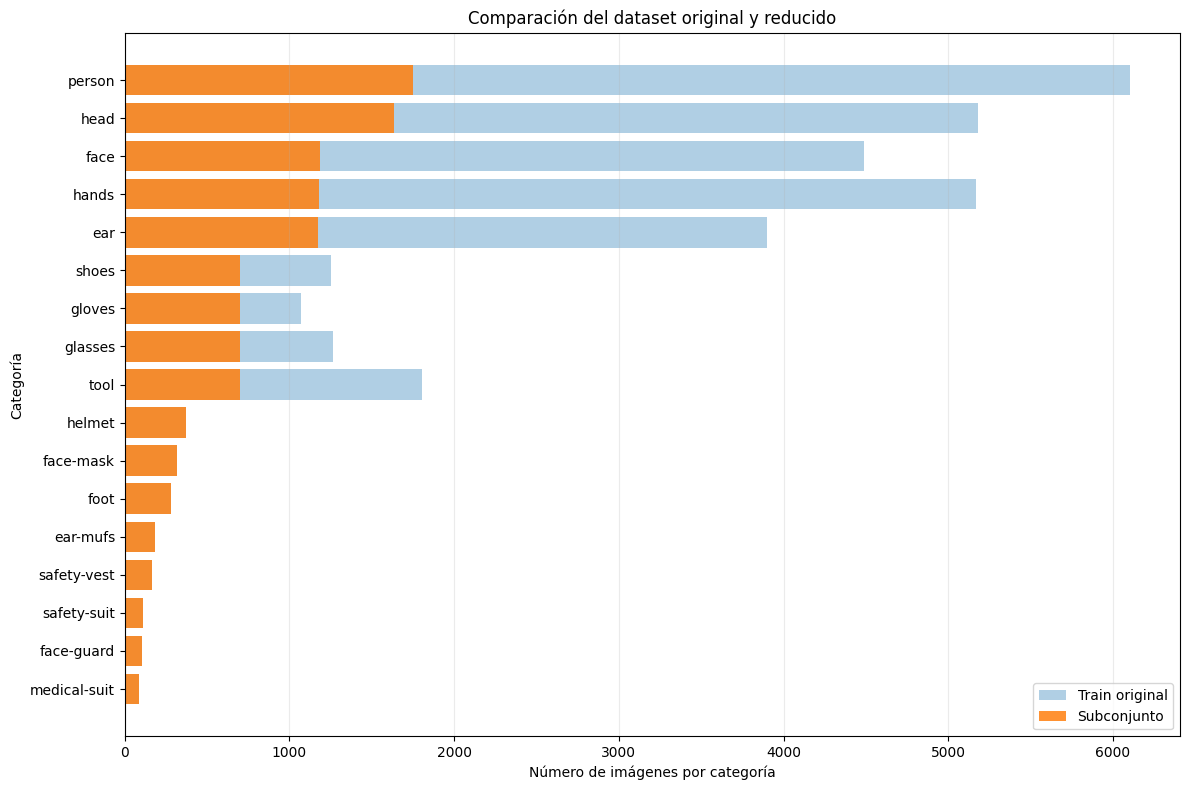

In [11]:

import random
import math
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

# Parámetros de selección
MAX_IMAGENES_TRAIN = 2000
META_MAYORITARIAS = 700

assert MAX_IMAGENES_TRAIN >= len(seleccion_obligatoria), (
    "El límite es menor que la selección obligatoria."
)

# Identificamos las clases mayoritarias
ids_mayoritarias = set(CLASES) - ids_minoritarias

# Comenzamos con las imágenes obligatorias
seleccion_final = set(seleccion_obligatoria)

# Calculamos la cobertura actual
conteo_actual = Counter()

for nombre in seleccion_final:
    for clase_id in clases_por_imagen[nombre]:
        conteo_actual[clase_id] += 1

# Imágenes de entrenamiento que todavía podemos utilizar
candidatos = sorted(train - seleccion_final)

# Orden aleatorio reproducible para resolver empates
rng = random.Random(SEMILLA)
rng.shuffle(candidatos)

# Peso fijo: prioriza categorías menos frecuentes
pesos = {
    clase_id: 1 / math.sqrt(conteo_train[clase_id])
    for clase_id in ids_mayoritarias
}

def calcular_puntaje(nombre):
    """
    Evalúa cuánto contribuye una imagen a mejorar
    la cobertura de las clases mayoritarias.
    """

    puntaje = 0.0

    for clase_id in clases_por_imagen[nombre]:

        if clase_id not in ids_mayoritarias:
            continue

        deficit = max(
            0,
            META_MAYORITARIAS - conteo_actual[clase_id]
        )

        if deficit > 0:
            puntaje += (
                deficit / META_MAYORITARIAS
            ) * pesos[clase_id]

    return puntaje


# Selección iterativa balanceada
while len(seleccion_final) < MAX_IMAGENES_TRAIN:

    # Verificar si ya cumplimos todas las metas
    pendientes = [
        clase_id
        for clase_id in ids_mayoritarias
        if conteo_actual[clase_id] < META_MAYORITARIAS
    ]

    if not pendientes:
        break

    # Buscar la imagen con mayor aporte
    mejor_imagen = None
    mejor_puntaje = 0.0

    for nombre in candidatos:
        puntaje = calcular_puntaje(nombre)

        if puntaje > mejor_puntaje:
            mejor_puntaje = puntaje
            mejor_imagen = nombre

    # Detener si ninguna imagen mejora la cobertura
    if mejor_imagen is None:
        break

    # Incorporamos la imagen seleccionada
    seleccion_final.add(mejor_imagen)
    candidatos.remove(mejor_imagen)

    # Actualizamos todas las categorías de esa imagen
    for clase_id in clases_por_imagen[mejor_imagen]:
        conteo_actual[clase_id] += 1


# Resumen de resultados
df_balanceado = pd.DataFrame([
    {
        "Clase": nombre,
        "Tipo": (
            "Minoritaria"
            if clase_id in ids_minoritarias
            else "Mayoritaria"
        ),
        "Train original": conteo_train[clase_id],
        "Antes": conteo_obligatorio[clase_id],
        "Después": conteo_actual[clase_id],
        "Cobertura (%)": round(
            100 * conteo_actual[clase_id]
            / conteo_train[clase_id], 2
        )
    }
    for clase_id, nombre in CLASES.items()
])

df_balanceado = df_balanceado.sort_values(
    ["Tipo", "Después"],
    ascending=[False, True]
).reset_index(drop=True)

print("RESULTADOS DEL BALANCEO SH17\n")

print("Imágenes originales de entrenamiento:", len(train))
print("Imágenes obligatorias:", len(seleccion_obligatoria))
print("Imágenes adicionales:",
      len(seleccion_final - seleccion_obligatoria))
print("Total seleccionado:", len(seleccion_final))

print(
    "Reducción del entrenamiento:",
    round(100 * (1 - len(seleccion_final) / len(train)), 2),
    "%"
)

print("\nDISTRIBUCIÓN ANTES Y DESPUÉS")
display(df_balanceado)

# Verificaciones finales
minoritarias_conservadas = seleccion_obligatoria.issubset(
    seleccion_final
)

sin_fuga = seleccion_final.isdisjoint(val)

metas_cumplidas = all(
    conteo_actual[clase_id] >= META_MAYORITARIAS
    for clase_id in ids_mayoritarias
)

print("\nVERIFICACIONES")
print("Imágenes obligatorias conservadas:",
      minoritarias_conservadas)
print("Sin imágenes compartidas con validación:", sin_fuga)
print("Metas de categorías mayoritarias alcanzadas:",
      metas_cumplidas)

assert minoritarias_conservadas
assert sin_fuga
assert len(seleccion_final) <= MAX_IMAGENES_TRAIN

# Visualización de cobertura
df_grafico = df_balanceado.sort_values("Después")

plt.figure(figsize=(12, 8))

plt.barh(
    df_grafico["Clase"],
    df_grafico["Train original"],
    alpha=0.35,
    label="Train original"
)

plt.barh(
    df_grafico["Clase"],
    df_grafico["Después"],
    alpha=0.85,
    label="Subconjunto"
)

plt.xlabel("Número de imágenes por categoría")
plt.ylabel("Categoría")
plt.title("Comparación del dataset original y reducido")
plt.legend()
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()



### 1.10. Exportación del subconjunto reducido para YOLO

Se genera nuevamente el subconjunto reducido del dataset SH17, utilizando el procedimiento de selección balanceada desarrollado durante el Hito 1.

Esta reconstrucción permite reproducir la preparación de los datos sin modificar los archivos originales ni los resultados obtenidos anteriormente.

El subconjunto inicial estará compuesto por:

- **Entrenamiento:** 1.801 imágenes seleccionadas mediante criterios de representación de clases minoritarias y mayoritarias.
- **Validación original:** 1.620 imágenes que posteriormente se dividirán en conjuntos independientes de validación y prueba.

Durante la exportación se realizan las siguientes operaciones:

- Copiar las imágenes y etiquetas seleccionadas.
- Corregir los pequeños excesos decimales detectados en las coordenadas de las cajas delimitadoras.
- Conservar las 17 categorías y sus anotaciones.
- Generar la estructura de carpetas compatible con YOLO.
- Crear el archivo `data.yaml` con las rutas y categorías del dataset.
- Registrar las imágenes exportadas y los ajustes realizados mediante un manifiesto.

El procesamiento inicial se realizará en el almacenamiento temporal de Google Colab para facilitar el acceso a los archivos durante las siguientes etapas.

Una vez completada la división entre entrenamiento, validación y prueba, se guardará una copia independiente en la carpeta `Examen_Hito2_EPP/Datasets` de Google Drive.

Los archivos y resultados del Hito 1 permanecerán sin modificaciones.


In [15]:
from pathlib import Path
import shutil

SALIDA = Path("/content/SH17_reducido")

# Seguridad: únicamente permitir borrar el dataset temporal
assert SALIDA.resolve() == Path("/content/SH17_reducido")
assert not SALIDA.is_symlink()

if SALIDA.exists():
    shutil.rmtree(SALIDA)
    print("Dataset temporal anterior eliminado.")
else:
    print("El dataset temporal no existía.")

print("Listo para reconstruir el dataset.")

Dataset temporal anterior eliminado.
Listo para reconstruir el dataset.


In [16]:

from pathlib import Path
import shutil
import yaml
import pandas as pd
import math

# ==========================================
# 1. CONFIGURACIÓN DE LA CARPETA DE SALIDA
# ==========================================

# Directorio temporal de trabajo en Google Colab
SALIDA = Path("/content/SH17_reducido")

# Destino definitivo en Google Drive para el Hito 2
DATASET_DRIVE_HITO2 = (
    CARPETA_HITO2 / "Datasets" / "SH17_reducido"
)

# Verificar que no se utilicen rutas del Hito 1
assert CARPETA_HITO1 not in SALIDA.parents
assert CARPETA_HITO1 not in DATASET_DRIVE_HITO2.parents

# Evitar sobrescribir accidentalmente otros resultados
if SALIDA.exists() and any(SALIDA.iterdir()):
    raise FileExistsError(
        f"La carpeta {SALIDA} ya contiene archivos. "
        "Elige otro nombre para evitar sobrescribirlos."
    )
print("Directorio temporal:", SALIDA)
print("Destino de respaldo Hito 2:", DATASET_DRIVE_HITO2)

# Verificaciones antes de copiar
assert len(seleccion_final) == 1801
assert len(val) == 1620
assert seleccion_final.isdisjoint(val)

# Cada imagen debe corresponder a una etiqueta única
stems = [imagen.stem for imagen in imagenes]
assert len(stems) == len(set(stems)), (
    "Existen imágenes con el mismo nombre base."
)

# Crear estructura YOLO
for conjunto in ["train", "val"]:
    (SALIDA / "images" / conjunto).mkdir(
        parents=True, exist_ok=True
    )
    (SALIDA / "labels" / conjunto).mkdir(
        parents=True, exist_ok=True
    )


# ==========================================
# 2. FUNCIÓN DE AJUSTE DE ANOTACIONES
# ==========================================

def ajustar_etiqueta_yolo(linea):
    """
    Ajusta una caja al rango [0, 1] y mantiene
    el identificador de clase original.

    Devuelve la anotación y si fue corregida.
    """

    datos = linea.strip().split()

    if len(datos) != 5:
        raise ValueError("Anotación con formato incorrecto")

    clase_id = int(datos[0])
    x, y, w, h = map(float, datos[1:])

    if clase_id not in CLASES:
        raise ValueError("Clase desconocida")

    if not all(math.isfinite(v) for v in (x, y, w, h)):
        raise ValueError("Coordenadas no finitas")

    # Límites originales
    x1 = x - w / 2
    y1 = y - h / 2
    x2 = x + w / 2
    y2 = y + h / 2

    # Solo permitimos la tolerancia ya validada
    tolerancia = 1e-6

    if not (
        -tolerancia <= x1 < x2 <= 1 + tolerancia
        and -tolerancia <= y1 < y2 <= 1 + tolerancia
    ):
        raise ValueError("Caja fuera de tolerancia")

    # Ajuste a los límites reales de la imagen
    x1_cor = max(0.0, min(1.0, x1))
    y1_cor = max(0.0, min(1.0, y1))
    x2_cor = max(0.0, min(1.0, x2))
    y2_cor = max(0.0, min(1.0, y2))

    if x2_cor <= x1_cor or y2_cor <= y1_cor:
        raise ValueError("Caja sin área después del ajuste")

    # Volver al formato YOLO:
    # clase centro_x centro_y ancho alto
    nuevo_x = (x1_cor + x2_cor) / 2
    nuevo_y = (y1_cor + y2_cor) / 2
    nuevo_w = x2_cor - x1_cor
    nuevo_h = y2_cor - y1_cor

    modificada = (
        x1_cor != x1 or y1_cor != y1
        or x2_cor != x2 or y2_cor != y2
    )

    nueva_linea = (
        f"{clase_id} "
        f"{nuevo_x:.10f} {nuevo_y:.10f} "
        f"{nuevo_w:.10f} {nuevo_h:.10f}"
    )

    return nueva_linea, modificada


# ==========================================
# 3. COPIA DE IMÁGENES Y ETIQUETAS
# ==========================================

manifiesto = []
cajas_ajustadas = 0
total_cajas = 0

particiones = {
    "train": seleccion_final,
    "val": val
}

for conjunto, nombres in particiones.items():

    print(f"\nExportando {conjunto}...")

    for nombre in sorted(nombres):

        origen_imagen = imagenes_por_nombre[nombre]
        origen_label = (
            ruta / "labels" / f"{origen_imagen.stem}.txt"
        )

        assert origen_imagen.exists()
        assert origen_label.exists()

        destino_imagen = (
            SALIDA / "images" / conjunto / nombre
        )

        destino_label = (
            SALIDA / "labels" / conjunto
            / f"{origen_imagen.stem}.txt"
        )

        # Copiar imagen
        shutil.copy2(origen_imagen, destino_imagen)

        # Leer todas las anotaciones de la imagen
        lineas_originales = origen_label.read_text(
            encoding="utf-8"
        ).splitlines()

        lineas_corregidas = []
        ajustes_imagen = 0

        for linea in lineas_originales:

            if not linea.strip():
                continue

            nueva_linea, modificada = (
                ajustar_etiqueta_yolo(linea)
            )

            lineas_corregidas.append(nueva_linea)
            ajustes_imagen += int(modificada)

        # Guardar todas las etiquetas corregidas
        destino_label.write_text(
            "\n".join(lineas_corregidas) + "\n",
            encoding="utf-8"
        )

        cajas_ajustadas += ajustes_imagen
        total_cajas += len(lineas_corregidas)

        # Registrar información de trazabilidad
        manifiesto.append({
            "imagen": nombre,
            "particion": conjunto,
            "objetos": len(lineas_corregidas),
            "cajas_ajustadas": ajustes_imagen
        })

    print(
        f"Finalizado: {len(nombres)} imágenes"
    )


# ==========================================
# 4. CREAR ARCHIVO DATA.YAML
# ==========================================

configuracion = {
    "path": str(SALIDA.resolve()),
    "train": "images/train",
    "val": "images/val",
    "nc": len(CLASES),
    "names": CLASES
}

with open(
    SALIDA / "data.yaml", "w", encoding="utf-8"
) as f:
    yaml.safe_dump(
        configuracion,
        f,
        sort_keys=False,
        allow_unicode=True
    )

# Guardar manifiesto de imágenes
df_manifiesto = pd.DataFrame(manifiesto)

df_manifiesto.to_csv(
    SALIDA / "manifiesto.csv",
    index=False
)


# ==========================================
# 5. VERIFICACIÓN DE LA EXPORTACIÓN
# ==========================================

print("\nVERIFICACIÓN DEL DATASET REDUCIDO\n")

for conjunto, nombres in particiones.items():

    n_imagenes = len(list(
        (SALIDA / "images" / conjunto).iterdir()
    ))

    n_etiquetas = len(list(
        (SALIDA / "labels" / conjunto).glob("*.txt")
    ))

    print(f"{conjunto.upper()}")
    print("Imágenes:", n_imagenes)
    print("Etiquetas:", n_etiquetas)

    assert n_imagenes == len(nombres)
    assert n_etiquetas == len(nombres)

# Comprobar YAML
with open(SALIDA / "data.yaml", encoding="utf-8") as f:
    yaml_verificado = yaml.safe_load(f)

assert yaml_verificado["nc"] == 17
assert len(yaml_verificado["names"]) == 17

print("\nRESUMEN GENERAL")
print("Total de imágenes:", len(manifiesto))
print("Total de anotaciones:", total_cajas)
print("Cajas ajustadas:", cajas_ajustadas)
print("Clases:", len(CLASES))

print("\nDataset guardado en:")
print(SALIDA)

print("\nArchivo de configuración:")
print(SALIDA / "data.yaml")

print("\nExportación finalizada correctamente.")


Directorio temporal: /content/SH17_reducido
Destino de respaldo Hito 2: /content/drive/MyDrive/Examen_Hito2_EPP/Datasets/SH17_reducido

Exportando train...
Finalizado: 1801 imágenes

Exportando val...
Finalizado: 1620 imágenes

VERIFICACIÓN DEL DATASET REDUCIDO

TRAIN
Imágenes: 1801
Etiquetas: 1801
VAL
Imágenes: 1620
Etiquetas: 1620

RESUMEN GENERAL
Total de imágenes: 3421
Total de anotaciones: 38996
Cajas ajustadas: 931
Clases: 17

Dataset guardado en:
/content/SH17_reducido

Archivo de configuración:
/content/SH17_reducido/data.yaml

Exportación finalizada correctamente.



### 1.11. Inspección visual de imágenes y anotaciones

Una vez exportado el subconjunto reducido, se realiza una inspección visual para comprobar la correspondencia entre las imágenes y sus anotaciones YOLO.

Se seleccionan ejemplos de diferentes categorías minoritarias y se representan sus cajas delimitadoras, utilizando las coordenadas normalizadas almacenadas en los archivos de etiquetas.

Esta revisión permite comprobar:

- La correcta asociación entre imágenes y etiquetas.
- La ubicación de las cajas sobre los objetos correspondientes.
- La identificación de las categorías mediante sus nombres.
- La integridad de las anotaciones después de los ajustes decimales.

También se incluirá una imagen que haya requerido corrección de coordenadas, para comprobar visualmente el resultado.

Esta inspección no reemplaza una auditoría exhaustiva del dataset, pero permite detectar posibles errores antes de entrenar el modelo YOLO.


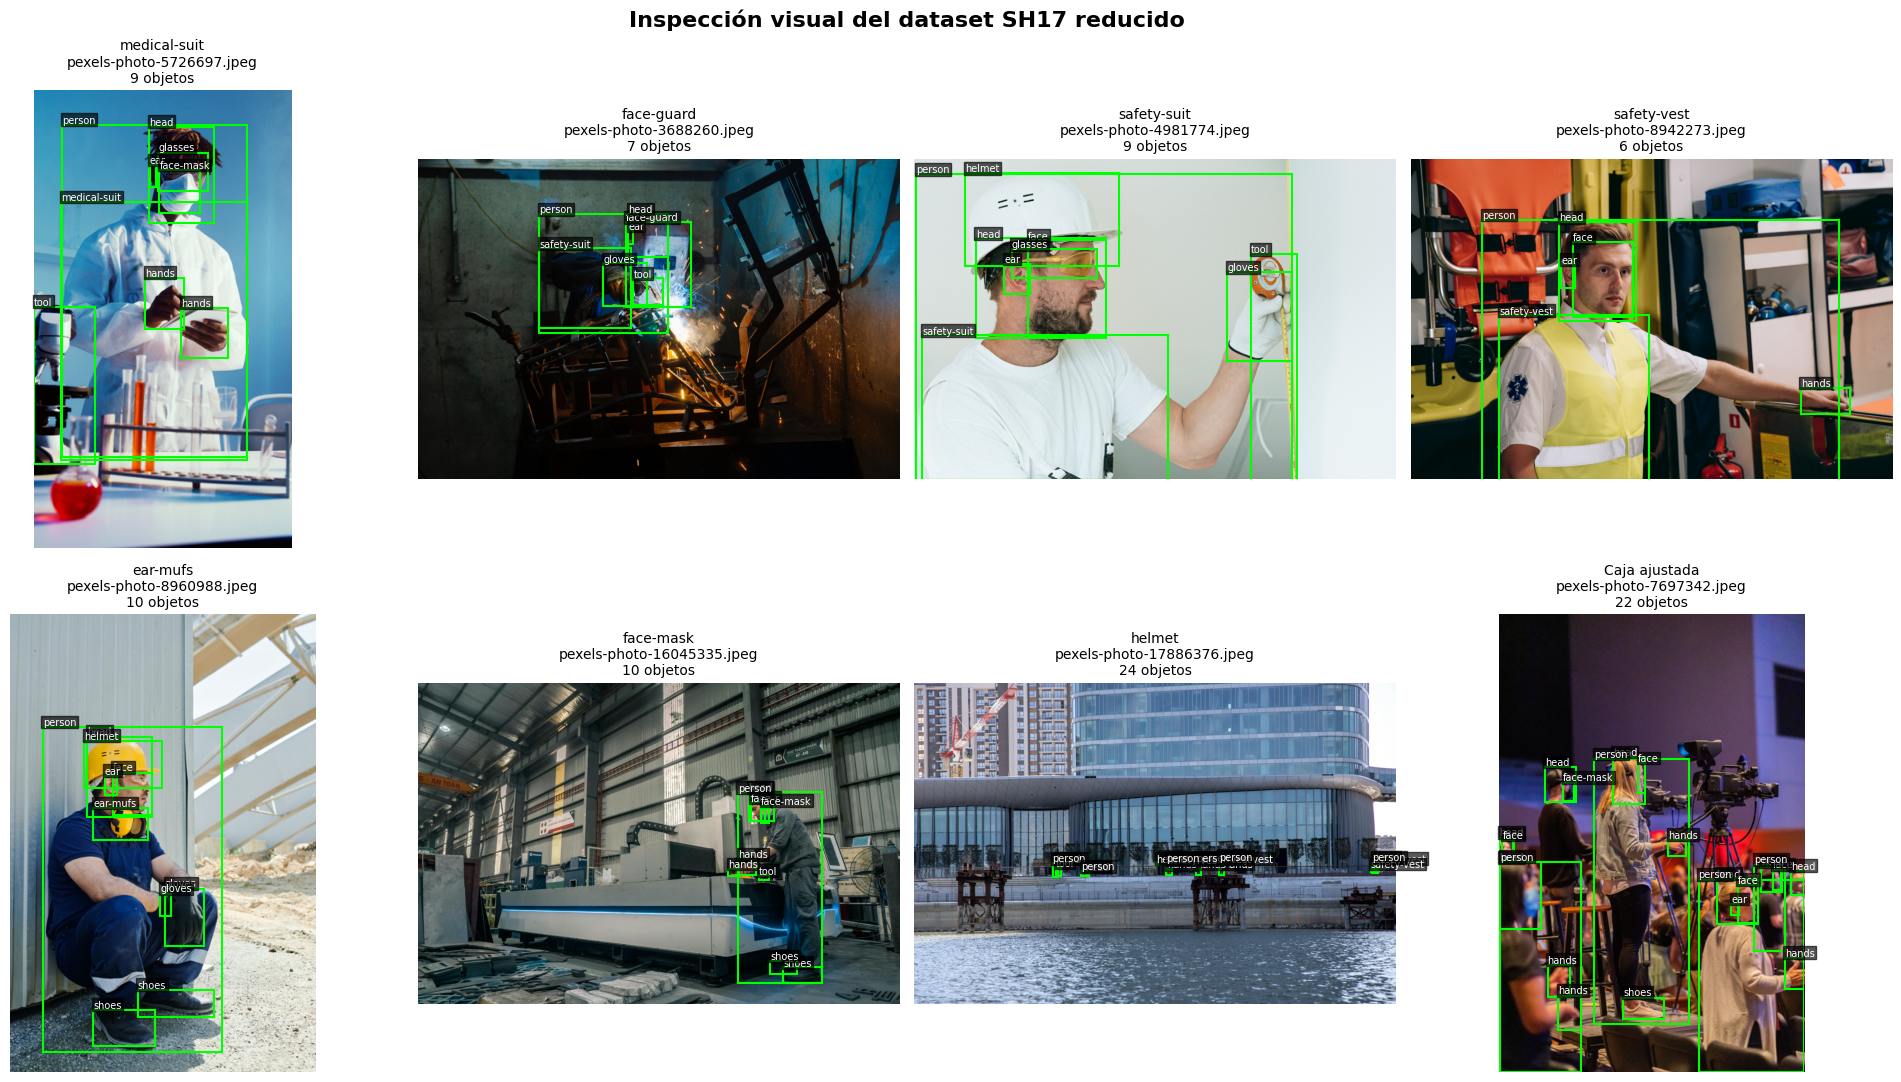

RESUMEN DE INSPECCIÓN

Imágenes registradas: 3421
Anotaciones exportadas: 38996
Cajas ajustadas: 931
Ejemplos visualizados: 8

Manifiesto verificado correctamente.


In [17]:

import random
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from matplotlib.patches import Rectangle

# ==========================================
# 1. PREPARAR EJEMPLOS
# ==========================================

# Recuperar el manifiesto creado en 1.10
df_manifiesto = pd.read_csv(
    SALIDA / "manifiesto.csv"
)

# Categorías minoritarias a inspeccionar
clases_revisar = [
    13,  # medical-suit
    4,   # face-guard
    15,  # safety-suit
    16,  # safety-vest
    2,   # ear-mufs
    5,   # face-mask
    10   # helmet
]

rng = random.Random(SEMILLA)
ejemplos = []
utilizadas = set()

# Elegir una imagen diferente para cada categoría
for clase_id in clases_revisar:

    candidatos = sorted([
        nombre for nombre in seleccion_final
        if clase_id in clases_por_imagen[nombre]
        and nombre not in utilizadas
    ])

    if candidatos:
        elegido = rng.choice(candidatos)
        ejemplos.append(
            (elegido, CLASES[clase_id])
        )
        utilizadas.add(elegido)

# Agregar una imagen que haya tenido cajas ajustadas
ajustadas = df_manifiesto[
    (df_manifiesto["particion"] == "train") &
    (df_manifiesto["cajas_ajustadas"] > 0)
]

candidatos_ajustados = sorted(
    set(ajustadas["imagen"]) - utilizadas
)

if candidatos_ajustados:
    elegido = rng.choice(candidatos_ajustados)
    ejemplos.append((elegido, "Caja ajustada"))


# ==========================================
# 2. VISUALIZAR IMÁGENES Y CAJAS
# ==========================================

fig, axes = plt.subplots(2, 4, figsize=(20, 11))
axes = axes.flatten()

for ax in axes:
    ax.axis("off")

for i, (nombre, categoria) in enumerate(ejemplos[:8]):

    ax = axes[i]

    imagen_path = SALIDA / "images" / "train" / nombre
    label_path = (
        SALIDA / "labels" / "train"
        / f"{Path(nombre).stem}.txt"
    )

    # Abrir imagen y reducir tamaño para visualizar
    with Image.open(imagen_path) as img:
        imagen = img.convert("RGB")
        imagen.thumbnail((900, 600))
        ancho, alto = imagen.size

    ax.imshow(imagen)

    # Leer todas las anotaciones de la imagen
    lineas = label_path.read_text(
        encoding="utf-8"
    ).splitlines()

    for linea in lineas:

        if not linea.strip():
            continue

        datos = linea.split()

        clase_id = int(datos[0])
        x, y, w, h = map(float, datos[1:])

        # Convertir coordenadas YOLO a píxeles
        x1 = (x - w / 2) * ancho
        y1 = (y - h / 2) * alto

        ancho_caja = w * ancho
        alto_caja = h * alto

        # Dibujar caja
        rectangulo = Rectangle(
            (x1, y1),
            ancho_caja,
            alto_caja,
            fill=False,
            edgecolor="lime",
            linewidth=1.5
        )

        ax.add_patch(rectangulo)

        # Nombre de la categoría
        ax.text(
            x1,
            max(0, y1 - 3),
            CLASES[clase_id],
            fontsize=7,
            color="white",
            bbox={
                "facecolor": "black",
                "alpha": 0.65,
                "pad": 1
            }
        )

    ax.set_title(
        f"{categoria}\n"
        f"{nombre[:35]}\n"
        f"{len(lineas)} objetos",
        fontsize=10
    )
    ax.axis("off")

plt.suptitle(
    "Inspección visual del dataset SH17 reducido",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ==========================================
# 3. VERIFICACIÓN FINAL DEL MANIFIESTO
# ==========================================

print("RESUMEN DE INSPECCIÓN\n")

print(
    "Imágenes registradas:",
    len(df_manifiesto)
)

print(
    "Anotaciones exportadas:",
    df_manifiesto["objetos"].sum()
)

print(
    "Cajas ajustadas:",
    df_manifiesto["cajas_ajustadas"].sum()
)

print(
    "Ejemplos visualizados:",
    len(ejemplos)
)

assert len(df_manifiesto) == 3421
assert df_manifiesto["objetos"].sum() == 38996
assert df_manifiesto["cajas_ajustadas"].sum() == 931

print("\nManifiesto verificado correctamente.")




## 2. Entrenamiento y evaluación del modelo YOLO

### 2.1. División estratificada del dataset SH17

Una vez reconstruido y validado el subconjunto reducido SH17, se realiza una división independiente de los datos para el entrenamiento, validación y evaluación de los modelos de detección de Elementos de Protección Personal (EPP).

El dataset contiene 3.421 imágenes y 17 categorías, distribuidas inicialmente en 1.801 imágenes de entrenamiento y 1.620 imágenes de validación.

Para establecer conjuntos independientes, se conservarán las 1.801 imágenes de entrenamiento y se dividirán las 1.620 imágenes restantes en dos conjuntos de 810 imágenes cada uno.

La división utilizará **estratificación multietiqueta**, mediante `MultilabelStratifiedShuffleSplit`, considerando simultáneamente las categorías presentes en cada fotografía. Esto permitirá procurar una distribución similar de las 17 clases entre validación y prueba.

La distribución definitiva será:

- **Entrenamiento (1.801 imágenes):** utilizado para ajustar los parámetros de los modelos.
- **Validación (810 imágenes):** utilizado para monitorear el aprendizaje, seleccionar hiperparámetros y aplicar detención temprana.
- **Prueba (810 imágenes):** reservado para evaluar el desempeño final y comparar los modelos y métodos base, sin utilizarlo para ajustar sus parámetros.

Se utilizará una semilla aleatoria fija de 2026 para favorecer la reproducibilidad.

La división se realizará únicamente sobre el dataset reconstruido en el almacenamiento temporal de Google Colab. No se modificarán los datos ni los resultados originales del Hito 1.

Posteriormente, el dataset dividido será respaldado en el directorio independiente `Examen_Hito2_EPP/Datasets` de Google Drive.

Finalmente, se actualizarán el archivo `data.yaml` y el manifiesto de imágenes para mantener la trazabilidad de las tres particiones.



In [18]:

# ============================================================
# 2.1. DIVISIÓN ESTRATIFICADA DEL DATASET SH17
# ============================================================

%pip -q install iterative-stratification

from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from pathlib import Path
import numpy as np
import pandas as pd
import shutil
import yaml

# ==========================================
# 1. CONFIGURACIÓN
# ==========================================

DATASET = Path("/content/SH17_reducido")
SEMILLA = 2026

imagenes_train = DATASET / "images" / "train"
imagenes_val = DATASET / "images" / "val"
etiquetas_val = DATASET / "labels" / "val"

imagenes_test = DATASET / "images" / "test"
etiquetas_test = DATASET / "labels" / "test"

# Confirmar que trabajamos en Colab, no en Drive
assert DATASET.resolve() == Path("/content/SH17_reducido")
assert CARPETA_HITO1 not in DATASET.parents

assert imagenes_train.is_dir()
assert imagenes_val.is_dir()
assert etiquetas_val.is_dir()

# No repetir una división existente
assert not imagenes_test.exists()
assert not etiquetas_test.exists()

print("DIVISIÓN DEL DATASET SH17\n")
print("Directorio de trabajo:", DATASET)

# ==========================================
# 2. LEER IMÁGENES Y ETIQUETAS
# ==========================================

nombres = sorted([
    p.name for p in imagenes_val.iterdir()
    if p.is_file()
])

assert len(nombres) == 1620, (
    f"Se esperaban 1620 imágenes y se encontraron {len(nombres)}."
)

# Matriz de presencia de las 17 categorías
Y = np.zeros((len(nombres), len(CLASES)), dtype=int)

for i, nombre in enumerate(nombres):

    archivo = etiquetas_val / f"{Path(nombre).stem}.txt"

    assert archivo.exists(), f"Falta etiqueta: {nombre}"

    for linea in archivo.read_text(
        encoding="utf-8"
    ).splitlines():

        if not linea.strip():
            continue

        clase_id = int(linea.split()[0])

        assert clase_id in CLASES

        Y[i, clase_id] = 1

# ==========================================
# 3. ESTRATIFICACIÓN MULTIETIQUETA
# ==========================================

divisor = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=SEMILLA
)

indices_val, indices_test = next(
    divisor.split(np.zeros((len(nombres), 1)), Y)
)

nombres_val_final = {
    nombres[i] for i in indices_val
}

nombres_test_final = {
    nombres[i] for i in indices_test
}

# ==========================================
# 4. VERIFICACIONES PREVIAS
# ==========================================

assert len(nombres_val_final) == 810
assert len(nombres_test_final) == 810

assert nombres_val_final.isdisjoint(nombres_test_final)

assert (
    nombres_val_final | nombres_test_final
) == set(nombres)

for nombre in nombres_test_final:

    assert (imagenes_val / nombre).exists()

    assert (
        etiquetas_val / f"{Path(nombre).stem}.txt"
    ).exists()

print("\nDIVISIÓN CALCULADA")

print("Validación:", len(nombres_val_final))
print("Prueba:", len(nombres_test_final))
print("Sin solapamiento:",
      nombres_val_final.isdisjoint(nombres_test_final))

# ==========================================
# 5. CREAR CONJUNTO DE PRUEBA
# ==========================================

# Se mueven archivos solo dentro de /content,
# sin intervenir Google Drive ni el Hito 1.

imagenes_test.mkdir(parents=True, exist_ok=False)
etiquetas_test.mkdir(parents=True, exist_ok=False)

for nombre in sorted(nombres_test_final):

    nombre_label = f"{Path(nombre).stem}.txt"

    shutil.move(
        str(imagenes_val / nombre),
        str(imagenes_test / nombre)
    )

    shutil.move(
        str(etiquetas_val / nombre_label),
        str(etiquetas_test / nombre_label)
    )

# ==========================================
# 6. ACTUALIZAR DATA.YAML
# ==========================================

archivo_yaml = DATASET / "data.yaml"

with open(archivo_yaml, encoding="utf-8") as f:
    configuracion = yaml.safe_load(f)

configuracion["test"] = "images/test"

with open(archivo_yaml, "w", encoding="utf-8") as f:
    yaml.safe_dump(
        configuracion,
        f,
        sort_keys=False,
        allow_unicode=True
    )

# ==========================================
# 7. ACTUALIZAR MANIFIESTO
# ==========================================

archivo_manifiesto = DATASET / "manifiesto.csv"

df_manifiesto = pd.read_csv(archivo_manifiesto)

df_manifiesto.loc[
    df_manifiesto["imagen"].isin(nombres_test_final),
    "particion"
] = "test"

df_manifiesto.to_csv(
    archivo_manifiesto,
    index=False
)

# ==========================================
# 8. VERIFICACIÓN FINAL
# ==========================================

CANTIDADES_ESPERADAS = {
    "train": 1801,
    "val": 810,
    "test": 810
}

print("\nDISTRIBUCIÓN FINAL DEL DATASET SH17")

conjuntos = {}

for conjunto, esperado in CANTIDADES_ESPERADAS.items():

    carpeta_img = DATASET / "images" / conjunto
    carpeta_lbl = DATASET / "labels" / conjunto

    archivos_img = [
        p for p in carpeta_img.iterdir() if p.is_file()
    ]

    archivos_lbl = list(carpeta_lbl.glob("*.txt"))

    nombres_img = {p.stem for p in archivos_img}
    nombres_lbl = {p.stem for p in archivos_lbl}

    assert len(archivos_img) == esperado
    assert len(archivos_lbl) == esperado
    assert nombres_img == nombres_lbl

    conjuntos[conjunto] = nombres_img

    print(
        f"{conjunto.upper()}: "
        f"{len(archivos_img)} imágenes | "
        f"{len(archivos_lbl)} etiquetas"
    )

assert conjuntos["train"].isdisjoint(conjuntos["val"])
assert conjuntos["train"].isdisjoint(conjuntos["test"])
assert conjuntos["val"].isdisjoint(conjuntos["test"])

# ==========================================
# 9. DISTRIBUCIÓN POR CATEGORÍA
# ==========================================

df_distribucion = pd.DataFrame([
    {
        "Clase": CLASES[clase_id],
        "Validación": int(Y[indices_val, clase_id].sum()),
        "Prueba": int(Y[indices_test, clase_id].sum())
    }
    for clase_id in CLASES
])

print("\nDISTRIBUCIÓN POR CATEGORÍA")
display(df_distribucion)

# ==========================================
# 10. RESULTADO GENERAL
# ==========================================

print("\nVERIFICACIONES FINALES")
print("Total de imágenes:", sum(CANTIDADES_ESPERADAS.values()))
print("Clases:", len(CLASES))
print("Particiones independientes: Sí")
print("Archivo YAML actualizado:", archivo_yaml.exists())
print("Hito 1 modificado: No")

print("\nDataset preparado correctamente.")


DIVISIÓN DEL DATASET SH17

Directorio de trabajo: /content/SH17_reducido

DIVISIÓN CALCULADA
Validación: 810
Prueba: 810
Sin solapamiento: True

DISTRIBUCIÓN FINAL DEL DATASET SH17
TRAIN: 1801 imágenes | 1801 etiquetas
VAL: 810 imágenes | 810 etiquetas
TEST: 810 imágenes | 810 etiquetas

DISTRIBUCIÓN POR CATEGORÍA


,Clase,Validación,Prueba
0,person,758,757
1,ear,494,493
2,ear-mufs,19,19
3,face,577,578
4,face-guard,12,11
5,face-mask,37,38
6,foot,32,32
7,tool,228,227
8,glasses,162,161
9,gloves,127,127



VERIFICACIONES FINALES
Total de imágenes: 3421
Clases: 17
Particiones independientes: Sí
Archivo YAML actualizado: True
Hito 1 modificado: No

Dataset preparado correctamente.



### 2.1.1. Respaldo y verificación del dataset definitivo

Una vez completada la división estratificada del dataset SH17, se almacena una copia independiente en Google Drive, dentro del directorio correspondiente al Hito 2.

El dataset definitivo contiene 3.421 imágenes distribuidas en:

- **Entrenamiento:** 1.801 imágenes.
- **Validación:** 810 imágenes.
- **Prueba:** 810 imágenes.

Se conservan las 17 categorías originales, las anotaciones corregidas, el archivo de configuración `data.yaml` y el manifiesto de trazabilidad.

Para garantizar la integridad del respaldo, se verificará la correspondencia entre los archivos originales del entorno temporal y sus respectivas copias en Drive, comprobando su cantidad, tamaño y contenido mediante SHA-256.

Se generará adicionalmente un archivo `data_drive.yaml` que permitirá utilizar el dataset directamente desde su ubicación permanente en Google Drive, sin modificar el archivo `data.yaml` preparado para el entorno temporal de Colab.

Durante el entrenamiento, se priorizará el uso del dataset almacenado temporalmente en Colab para reducir los tiempos de lectura de las imágenes.

El respaldo se realizará exclusivamente dentro del directorio `Examen_Hito2_EPP`, sin modificar los archivos del Hito 1.


In [19]:

# ============================================================
# 2.1.1. RESPALDO DEL DATASET SH17 EN GOOGLE DRIVE
# ============================================================

from pathlib import Path
import shutil
import hashlib
import yaml

# ==========================================
# 1. CONFIGURAR RUTAS
# ==========================================

DATASET_LOCAL = Path("/content/SH17_reducido")

DATASET_DRIVE = (
    CARPETA_HITO2 / "Datasets" / "SH17_reducido"
)

# Verificar origen y destino
assert DATASET_LOCAL.is_dir()
assert (DATASET_LOCAL / "data.yaml").is_file()

assert DATASET_DRIVE.parent == (
    CARPETA_HITO2 / "Datasets"
)

assert CARPETA_HITO1 not in DATASET_DRIVE.parents

# No sobrescribir respaldos existentes
if DATASET_DRIVE.exists():
    raise FileExistsError(
        f"Ya existe un respaldo en {DATASET_DRIVE}. "
        "No se sobrescribirá."
    )

# ==========================================
# 2. VERIFICAR DATASET LOCAL
# ==========================================

CANTIDADES = {
    "train": 1801,
    "val": 810,
    "test": 810
}

EXTENSIONES = {
    ".jpg", ".jpeg", ".png", ".webp", ".bmp"
}

print("VERIFICACIÓN PREVIA DEL DATASET\n")

for particion, esperado in CANTIDADES.items():

    carpeta_img = DATASET_LOCAL / "images" / particion
    carpeta_lbl = DATASET_LOCAL / "labels" / particion

    imagenes = [
        p for p in carpeta_img.iterdir()
        if p.is_file() and p.suffix.lower() in EXTENSIONES
    ]

    etiquetas = list(carpeta_lbl.glob("*.txt"))

    assert len(imagenes) == esperado
    assert len(etiquetas) == esperado

    print(
        f"{particion.upper()}: "
        f"{len(imagenes)} imágenes | "
        f"{len(etiquetas)} etiquetas"
    )

# ==========================================
# 3. COPIAR DATASET A GOOGLE DRIVE
# ==========================================

print("\nCOPIANDO DATASET A GOOGLE DRIVE")

shutil.copytree(
    DATASET_LOCAL,
    DATASET_DRIVE,
    copy_function=shutil.copy2
)

print("Copia realizada.")

# ==========================================
# 4. VERIFICAR INTEGRIDAD DE LA COPIA
# ==========================================

def calcular_sha256(ruta_archivo):
    """Calcula SHA-256 leyendo el archivo por bloques."""

    hash_archivo = hashlib.sha256()

    with open(ruta_archivo, "rb") as archivo:
        for bloque in iter(
            lambda: archivo.read(1024 * 1024),
            b""
        ):
            hash_archivo.update(bloque)

    return hash_archivo.hexdigest()


archivos_origen = sorted(
    p.relative_to(DATASET_LOCAL)
    for p in DATASET_LOCAL.rglob("*")
    if p.is_file()
)

archivos_destino = sorted(
    p.relative_to(DATASET_DRIVE)
    for p in DATASET_DRIVE.rglob("*")
    if p.is_file()
)

assert archivos_origen == archivos_destino, (
    "La copia presenta archivos faltantes o adicionales."
)

print("\nVERIFICANDO INTEGRIDAD")

for i, ruta_relativa in enumerate(archivos_origen, start=1):

    origen = DATASET_LOCAL / ruta_relativa
    destino = DATASET_DRIVE / ruta_relativa

    assert origen.stat().st_size == destino.stat().st_size, (
        f"Tamaño diferente: {ruta_relativa}"
    )

    assert calcular_sha256(origen) == calcular_sha256(destino), (
        f"Contenido diferente: {ruta_relativa}"
    )

    if i % 500 == 0:
        print(f"Verificados: {i}/{len(archivos_origen)}")

print("\nIntegridad comprobada mediante SHA-256.")

# ==========================================
# 5. CREAR CONFIGURACIÓN PARA DRIVE
# ==========================================

with open(
    DATASET_DRIVE / "data.yaml",
    encoding="utf-8"
) as archivo:
    configuracion = yaml.safe_load(archivo)

# Crear una configuración adicional para Drive
configuracion_drive = configuracion.copy()

configuracion_drive["path"] = str(DATASET_DRIVE)

with open(
    DATASET_DRIVE / "data_drive.yaml",
    "w",
    encoding="utf-8"
) as archivo:
    yaml.safe_dump(
        configuracion_drive,
        archivo,
        sort_keys=False,
        allow_unicode=True
    )

# ==========================================
# 6. RESULTADO FINAL
# ==========================================

print("\nRESPALDO COMPLETADO CORRECTAMENTE")

print("\nDataset temporal:")
print(DATASET_LOCAL)

print("\nDataset permanente:")
print(DATASET_DRIVE)

print("\nArchivos originales verificados:")
print(len(archivos_origen))

print("\nConfiguración para Colab:")
print(DATASET_LOCAL / "data.yaml")

print("\nConfiguración para Drive:")
print(DATASET_DRIVE / "data_drive.yaml")

print("\nLos archivos del Hito 1 no fueron modificados.")


VERIFICACIÓN PREVIA DEL DATASET

TRAIN: 1801 imágenes | 1801 etiquetas
VAL: 810 imágenes | 810 etiquetas
TEST: 810 imágenes | 810 etiquetas

COPIANDO DATASET A GOOGLE DRIVE
Copia realizada.

VERIFICANDO INTEGRIDAD
Verificados: 500/6844
Verificados: 1000/6844
Verificados: 1500/6844
Verificados: 2000/6844
Verificados: 2500/6844
Verificados: 3000/6844
Verificados: 3500/6844
Verificados: 4000/6844
Verificados: 4500/6844
Verificados: 5000/6844
Verificados: 5500/6844
Verificados: 6000/6844
Verificados: 6500/6844

Integridad comprobada mediante SHA-256.

RESPALDO COMPLETADO CORRECTAMENTE

Dataset temporal:
/content/SH17_reducido

Dataset permanente:
/content/drive/MyDrive/Examen_Hito2_EPP/Datasets/SH17_reducido

Archivos originales verificados:
6844

Configuración para Colab:
/content/SH17_reducido/data.yaml

Configuración para Drive:
/content/drive/MyDrive/Examen_Hito2_EPP/Datasets/SH17_reducido/data_drive.yaml

Los archivos del Hito 1 no fueron modificados.



### 2.2. Configuración del entorno y carga del modelo YOLOv8

Se configura el entorno computacional para desarrollar el entrenamiento de un modelo de detección de objetos mediante YOLOv8, implementado utilizando la biblioteca Ultralytics.

Se utilizará inicialmente **YOLOv8n (Nano)**, una arquitectura liviana que permite reducir los requerimientos computacionales y establecer un modelo de referencia para el reconocimiento de Elementos de Protección Personal (EPP).

El modelo será inicializado con pesos preentrenados, aplicando transferencia de aprendizaje para adaptarse a las 17 categorías del dataset SH17.

Aunque el entrenamiento considera las 17 categorías, el análisis del Hito 2 se concentrará especialmente en cinco elementos de protección personal, organizados según los requerimientos de dos zonas de supervisión:

- **Zona 1:** casco de seguridad (`helmet`) y chaleco de seguridad (`safety-vest`).
- **Zona 2:** zapatos de seguridad (`shoes`), guantes (`gloves`) y lentes de protección (`glasses`).

La utilización de las 17 categorías permitirá conservar la información original del dataset. Posteriormente, las reglas de cumplimiento determinarán qué EPP debe verificarse en cada zona.

En esta etapa se realizarán las siguientes operaciones:

1. Instalar y verificar las bibliotecas necesarias para el entrenamiento.
2. Comprobar la disponibilidad de una GPU y su memoria.
3. Verificar las tres particiones del dataset SH17 y el archivo `data.yaml`.
4. Confirmar las 17 categorías y los identificadores de los cinco EPP prioritarios.
5. Cargar el modelo YOLOv8n con pesos preentrenados.

El entrenamiento se ejecutará utilizando el dataset ubicado en el almacenamiento temporal de Google Colab, mientras que sus resultados se guardarán en el directorio independiente del Hito 2 en Google Drive.

Esta preparación permitirá comprobar que los datos y los recursos computacionales están disponibles antes de comenzar el nuevo entrenamiento.


In [20]:

# ============================================================
# 2.2. CONFIGURACIÓN DEL ENTORNO Y CARGA DE YOLOv8
# ============================================================

# ==========================================
# 1. INSTALAR ULTRALYTICS
# ==========================================

%pip -q install ultralytics

# ==========================================
# 2. IMPORTAR LIBRERÍAS
# ==========================================

import torch
import ultralytics
import yaml

from pathlib import Path
from ultralytics import YOLO

# ==========================================
# 3. VERIFICAR GPU
# ==========================================

print("CONFIGURACIÓN DEL ENTORNO - HITO 2\n")

print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)

gpu_disponible = torch.cuda.is_available()

print("GPU disponible:", gpu_disponible)

assert gpu_disponible, (
    "No se detectó una GPU. "
    "Activa una GPU desde Entorno de ejecución "
    "> Cambiar tipo de entorno de ejecución."
)

nombre_gpu = torch.cuda.get_device_name(0)

memoria_gpu = (
    torch.cuda.get_device_properties(0).total_memory
    / (1024 ** 3)
)

print("GPU:", nombre_gpu)
print("Memoria GPU:", round(memoria_gpu, 2), "GB")

# ==========================================
# 4. VERIFICAR DATASET LOCAL
# ==========================================

DATASET = Path("/content/SH17_reducido")
ARCHIVO_YAML = DATASET / "data.yaml"

assert ARCHIVO_YAML.is_file(), (
    "No se encontró data.yaml en Colab."
)

with open(ARCHIVO_YAML, encoding="utf-8") as f:
    configuracion = yaml.safe_load(f)

assert configuracion["nc"] == 17
assert len(configuracion["names"]) == 17

# Confirmar rutas internas
assert Path(configuracion["path"]).resolve() == DATASET.resolve()

CANTIDADES_ESPERADAS = {
    "train": 1801,
    "val": 810,
    "test": 810
}

print("\nVERIFICACIÓN DEL DATASET SH17")

for conjunto, esperado in CANTIDADES_ESPERADAS.items():

    carpeta_img = DATASET / "images" / conjunto
    carpeta_lbl = DATASET / "labels" / conjunto

    assert carpeta_img.is_dir()
    assert carpeta_lbl.is_dir()

    imagenes = [
        p for p in carpeta_img.iterdir()
        if p.is_file() and p.suffix.lower()
        in {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
    ]

    etiquetas = list(carpeta_lbl.glob("*.txt"))

    assert len(imagenes) == esperado
    assert len(etiquetas) == esperado

    assert {p.stem for p in imagenes} == {
        p.stem for p in etiquetas
    }

    print(
        f"{conjunto.upper()}: "
        f"{len(imagenes)} imágenes | "
        f"{len(etiquetas)} etiquetas"
    )

# ==========================================
# 5. VERIFICAR CATEGORÍAS PRIORITARIAS
# ==========================================

nombres_clases = configuracion["names"]

if isinstance(nombres_clases, list):
    clases_yolo = dict(enumerate(nombres_clases))
else:
    clases_yolo = {
        int(k): v for k, v in nombres_clases.items()
    }

EPP_ZONAS = {
    "zona_1": ["helmet", "safety-vest"],
    "zona_2": ["shoes", "gloves", "glasses"]
}

print("\nCATEGORÍAS PRIORITARIAS")

for zona, categorias in EPP_ZONAS.items():

    print(f"\n{zona.upper()}")

    for categoria in categorias:

        identificadores = [
            clase_id
            for clase_id, nombre in clases_yolo.items()
            if nombre == categoria
        ]

        assert len(identificadores) == 1, (
            f"No se encontró la clase: {categoria}"
        )

        print(
            f"- {categoria}: "
            f"ID {identificadores[0]}"
        )

# ==========================================
# 6. VERIFICAR RESPALDO INDEPENDIENTE
# ==========================================

DATASET_RESPALDO = (
    CARPETA_HITO2 / "Datasets" / "SH17_reducido"
)

assert (
    DATASET_RESPALDO / "data_drive.yaml"
).is_file(), (
    "No se encontró el respaldo del Hito 2."
)

print("\nRespaldo independiente encontrado:")
print(DATASET_RESPALDO)

# ==========================================
# 7. CARGAR MODELO PREENTRENADO
# ==========================================

modelo = YOLO("yolov8n.pt")

print("\nMODELO CARGADO CORRECTAMENTE")

print("Arquitectura: YOLOv8 Nano")
print("Tarea:", modelo.task)
print("Clases del dataset:", configuracion["nc"])
print("GPU disponible:", nombre_gpu)

print("\nEntorno preparado para el entrenamiento.")
print("No se ha iniciado ningún entrenamiento.")


CONFIGURACIÓN DEL ENTORNO - HITO 2

PyTorch: 2.14.1+cu130
Ultralytics: 8.4.213
GPU disponible: True
GPU: Tesla T4
Memoria GPU: 14.56 GB

VERIFICACIÓN DEL DATASET SH17
TRAIN: 1801 imágenes | 1801 etiquetas
VAL: 810 imágenes | 810 etiquetas
TEST: 810 imágenes | 810 etiquetas

CATEGORÍAS PRIORITARIAS

ZONA_1
- helmet: ID 10
- safety-vest: ID 16

ZONA_2
- shoes: ID 14
- gloves: ID 9
- glasses: ID 8

Respaldo independiente encontrado:
/content/drive/MyDrive/Examen_Hito2_EPP/Datasets/SH17_reducido

MODELO CARGADO CORRECTAMENTE
Arquitectura: YOLOv8 Nano
Tarea: detect
Clases del dataset: 17
GPU disponible: Tesla T4

Entorno preparado para el entrenamiento.
No se ha iniciado ningún entrenamiento.



### 2.3. Entrenamiento optimizado del modelo YOLOv8n

Se desarrollará un nuevo entrenamiento de YOLOv8n utilizando transferencia de aprendizaje y el dataset SH17, con el propósito de mejorar el reconocimiento de Elementos de Protección Personal (EPP) y reducir los tiempos de procesamiento observados durante el Hito 1.

El modelo reconocerá las 17 categorías del dataset, prestando especial atención a los elementos requeridos en las dos zonas de supervisión:

- **Zona 1:** casco (`helmet`) y chaleco de seguridad (`safety-vest`).
- **Zona 2:** zapatos (`shoes`), guantes (`gloves`) y lentes de protección (`glasses`).

#### Configuración del entrenamiento

Se establece un máximo de 50 épocas, resolución de 640 × 640 píxeles y un tamaño de lote inicial de 32 imágenes, sujeto a una prueba de rendimiento en la GPU Tesla T4.

La configuración utilizará precisión mixta automática (AMP), carga paralela de imágenes y almacenamiento en caché cuando exista memoria RAM suficiente.

Se utilizará una semilla aleatoria de 2026 para favorecer la reproducibilidad.

#### Detención temprana

Se configurará detención temprana mediante `patience=4`.

En la tarea de detección de objetos, YOLOv8 utiliza un indicador de desempeño (*fitness*) basado en el mAP50-95 del conjunto de validación.

Se considerará que existe una mejora cuando el modelo alcance un valor superior al mejor desempeño de validación registrado previamente.

Si transcurren cuatro épocas consecutivas sin superar el mejor valor registrado, el entrenamiento se detendrá anticipadamente. Si se obtiene una nueva mejora, el contador se reiniciará.

Este mecanismo permitirá evitar entrenamientos prolongados cuando el desempeño se estanque. Sin embargo, al utilizar un valor de paciencia relativamente estricto, será necesario verificar que la detención no haya sido prematura.

#### Distribución de los datos

- **Entrenamiento:** 1.801 imágenes para ajustar los parámetros del modelo.
- **Validación:** 810 imágenes para evaluar el aprendizaje, seleccionar el mejor modelo y aplicar detención temprana.
- **Prueba:** 810 imágenes que no participarán en el entrenamiento y se utilizarán para la evaluación final.

#### Prueba preliminar de rendimiento

Antes del entrenamiento definitivo, se realizará una prueba de dos épocas para comprobar el funcionamiento de la nueva configuración y medir el tiempo de procesamiento.

Esta prueba no constituirá el modelo final ni se utilizará para comparar su precisión con los modelos definitivos.

Si la configuración demuestra un funcionamiento adecuado, se realizará un nuevo entrenamiento desde los pesos preentrenados, con un máximo de 50 épocas.

Los resultados, métricas, checkpoints y gráficos se almacenarán exclusivamente en el directorio independiente del Hito 2.

El objetivo será obtener un modelo entrenado y evaluado de forma reproducible, prestando especial atención a la sensibilidad de las categorías de EPP que presentaron dificultades durante el Hito 1.


In [21]:

# ============================================================
# 2.3.1. PRUEBA PRELIMINAR DE RENDIMIENTO - TESLA T4
# ============================================================

from pathlib import Path
from ultralytics import YOLO

import torch
import psutil
import os
import time
import pandas as pd

# ==========================================
# 1. COMPROBAR RECURSOS
# ==========================================

print("PRUEBA DE RENDIMIENTO - HITO 2\n")

assert torch.cuda.is_available(), "Se requiere GPU."

GPU = torch.cuda.get_device_name(0)

RAM_DISPONIBLE = (
    psutil.virtual_memory().available / (1024 ** 3)
)

CPU_DISPONIBLES = os.cpu_count() or 2

print("GPU:", GPU)
print("RAM disponible:", round(RAM_DISPONIBLE, 2), "GB")
print("CPU disponibles:", CPU_DISPONIBLES)

# ==========================================
# 2. CONFIGURACIÓN DE LA PRUEBA
# ==========================================

DATASET = Path("/content/SH17_reducido")
ARCHIVO_YAML = DATASET / "data.yaml"

assert ARCHIVO_YAML.is_file()

EPOCAS_PRUEBA = 2
TAMANO_IMAGEN = 640
BATCH_PRUEBA = 32

WORKERS = min(4, CPU_DISPONIBLES)

# Utilizar caché RAM solamente cuando exista
# suficiente memoria disponible.
# Ultralytics también comprueba la memoria
# antes de realizar el almacenamiento en caché.

CACHE = "ram" if RAM_DISPONIBLE >= 8 else False

print("\nPARÁMETROS")

print("Épocas:", EPOCAS_PRUEBA)
print("Resolución:", TAMANO_IMAGEN)
print("Batch:", BATCH_PRUEBA)
print("Workers:", WORKERS)
print("Caché:", CACHE)

# ==========================================
# 3. CONFIGURAR CARPETA INDEPENDIENTE
# ==========================================

CARPETA_RESULTADOS = (
    CARPETA_HITO2 / "Entrenamientos_YOLO"
)

NOMBRE_PRUEBA = "Diagnostico_T4_640_B32_v1"

CARPETA_PRUEBA = (
    CARPETA_RESULTADOS / NOMBRE_PRUEBA
)

assert CARPETA_RESULTADOS.resolve().is_relative_to(
    CARPETA_HITO2.resolve()
)

assert not CARPETA_PRUEBA.exists(), (
    "La carpeta de esta prueba ya existe. "
    "Utiliza otro nombre para no sobrescribir resultados."
)

print("\nResultados de la prueba:")
print(CARPETA_PRUEBA)

# ==========================================
# 4. CARGAR PESOS PREENTRENADOS
# ==========================================

modelo_prueba = YOLO("yolov8n.pt")

# ==========================================
# 5. EJECUTAR PRUEBA
# ==========================================

print("\nINICIANDO PRUEBA DE DOS ÉPOCAS\n")

inicio = time.perf_counter()

resultado_prueba = modelo_prueba.train(
    data=str(ARCHIVO_YAML),

    # Prueba breve
    epochs=EPOCAS_PRUEBA,
    imgsz=TAMANO_IMAGEN,
    batch=BATCH_PRUEBA,

    # Hardware y rendimiento
    device=0,
    workers=WORKERS,
    amp=True,
    cache=CACHE,

    # Reproducibilidad
    seed=2026,
    deterministic=True,

    # Validación
    val=True,

    # Guardado independiente
    project=str(CARPETA_RESULTADOS),
    name=NOMBRE_PRUEBA,
    exist_ok=False,
    save=True,
    plots=False,

    verbose=True
)

duracion = time.perf_counter() - inicio

# ==========================================
# 6. COMPROBAR RESULTADOS
# ==========================================

CARPETA_PRUEBA_REAL = Path(
    modelo_prueba.trainer.save_dir
)

ARCHIVO_CSV = (
    CARPETA_PRUEBA_REAL / "results.csv"
)

print("\nPRUEBA FINALIZADA")

print("Tiempo total:", round(duracion / 60, 2), "minutos")

print("Carpeta:", CARPETA_PRUEBA_REAL)

if ARCHIVO_CSV.is_file():

    df_prueba = pd.read_csv(ARCHIVO_CSV)

    df_prueba.columns = (
        df_prueba.columns.str.strip()
    )

    print("\nMÉTRICAS REGISTRADAS")

    columnas = [
        "epoch",
        "time",
        "metrics/precision(B)",
        "metrics/recall(B)",
        "metrics/mAP50(B)",
        "metrics/mAP50-95(B)"
    ]

    disponibles = [
        c for c in columnas
        if c in df_prueba.columns
    ]

    display(df_prueba[disponibles])

    if "time" in df_prueba.columns and len(df_prueba) >= 2:
        tiempo_epoca_2 = (
            df_prueba["time"].iloc[1]
            - df_prueba["time"].iloc[0]
        )

        print(
            "\nTiempo registrado entre épocas:",
            round(tiempo_epoca_2 / 60, 2),
            "minutos"
        )

print("\nMemoria máxima GPU utilizada:")

print(
    round(
        torch.cuda.max_memory_reserved(0) / (1024 ** 3),
        2
    ),
    "GB"
)

print("\nPrueba guardada sin modificar el Hito 1.")


PRUEBA DE RENDIMIENTO - HITO 2

GPU: Tesla T4
RAM disponible: 10.56 GB
CPU disponibles: 2

PARÁMETROS
Épocas: 2
Resolución: 640
Batch: 32
Workers: 2
Caché: ram

Resultados de la prueba:
/content/drive/MyDrive/Examen_Hito2_EPP/Entrenamientos_YOLO/Diagnostico_T4_640_B32_v1

INICIANDO PRUEBA DE DOS ÉPOCAS

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SH17_reducido/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, f

,epoch,time,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B)
0,1,33.2537,0.45454,0.26200,0.21976,0.12528
1,2,58.8485,0.48203,0.32228,0.32570,0.19093



Tiempo registrado entre épocas: 0.43 minutos

Memoria máxima GPU utilizada:
4.81 GB

Prueba guardada sin modificar el Hito 1.



#### Resultados del diagnóstico inicial de rendimiento

La prueba preliminar se ejecutó correctamente en una GPU Tesla T4, utilizando imágenes de 640 × 640 px, un tamaño de lote de 32 y precisión mixta automática.

El consumo máximo de memoria GPU fue de 4,81 GB, por debajo de los 14,56 GB disponibles, confirmando que la configuración puede ejecutarse sin agotar la memoria de video. Las dos épocas finalizaron correctamente. Sin embargo, la preparación de la caché en RAM requirió aproximadamente 12 minutos, representando la mayor parte de la duración total de 13,69 minutos.

Por este motivo, se realizará una segunda prueba de rendimiento con la caché desactivada, manteniendo los demás parámetros equivalentes.

La comparación permitirá determinar qué configuración resulta más conveniente para el entrenamiento definitivo, considerando tanto el tiempo inicial de preparación como la velocidad de procesamiento por época.

Las métricas de precisión obtenidas en estas pruebas preliminares no serán utilizadas como evaluación definitiva del desempeño del modelo.

**debido al reinicio de todo el notebook, la siguiente casilla no se va a poder a volver a correr, sin embargo, ya lo hicimos correr antes y se demoraba el tiempo indicado en los MD**


In [1]:
# ============================================================
# 2.3.2. PRUEBA DE RENDIMIENTO SIN CACHÉ
# ============================================================

from ultralytics import YOLO
from pathlib import Path
import torch
import time
import pandas as pd

# ==========================================
# 1. CONFIGURAR EXPERIMENTO
# ==========================================

ARCHIVO_YAML = Path(
    "/content/SH17_reducido/data.yaml"
)

CARPETA_RESULTADOS = (
    CARPETA_HITO2 / "Entrenamientos_YOLO"
)

NOMBRE_PRUEBA = "Diagnostico_T4_640_B32_SinCache_v2"

CARPETA_PRUEBA = (
    CARPETA_RESULTADOS / NOMBRE_PRUEBA
)

assert ARCHIVO_YAML.is_file()
assert torch.cuda.is_available()

assert CARPETA_RESULTADOS.resolve().is_relative_to(
    CARPETA_HITO2.resolve()
)

assert not CARPETA_PRUEBA.exists(), (
    "La carpeta del experimento ya existe. "
    "No se sobrescribirán resultados."
)

print("PRUEBA SIN CACHÉ - HITO 2\n")

print("GPU:", torch.cuda.get_device_name(0))
print("Épocas:", 2)
print("Resolución:", 640)
print("Batch:", 32)
print("Workers:", 2)
print("Caché:", False)

# ==========================================
# 2. CARGAR MODELO
# ==========================================

modelo_sin_cache = YOLO("yolov8n.pt")

torch.cuda.reset_peak_memory_stats(0)

# ==========================================
# 3. EJECUTAR ENTRENAMIENTO
# ==========================================

inicio = time.perf_counter()

resultado_sin_cache = modelo_sin_cache.train(
    data=str(ARCHIVO_YAML),

    epochs=2,
    imgsz=640,
    batch=32,

    device=0,
    workers=2,
    amp=True,
    cache=False,

    seed=2026,
    deterministic=True,

    val=True,

    project=str(CARPETA_RESULTADOS),
    name=NOMBRE_PRUEBA,
    exist_ok=False,

    save=True,
    plots=False,

    verbose=True
)

duracion = time.perf_counter() - inicio

# ==========================================
# 4. MOSTRAR RESULTADOS
# ==========================================

CARPETA_REAL = Path(
    modelo_sin_cache.trainer.save_dir
)

ARCHIVO_CSV = CARPETA_REAL / "results.csv"

print("\nPRUEBA SIN CACHÉ FINALIZADA")

print(
    "Tiempo total:",
    round(duracion / 60, 2),
    "minutos"
)

print(
    "Memoria GPU máxima:",
    round(
        torch.cuda.max_memory_reserved(0) / (1024 ** 3),
        2
    ),
    "GB"
)

if ARCHIVO_CSV.exists():

    df = pd.read_csv(ARCHIVO_CSV)
    df.columns = df.columns.str.strip()

    columnas = [
        "epoch",
        "time",
        "metrics/precision(B)",
        "metrics/recall(B)",
        "metrics/mAP50(B)",
        "metrics/mAP50-95(B)"
    ]

    display(df[columnas])

    if len(df) >= 2:

        tiempo_epoca_2 = (
            df["time"].iloc[1]
            - df["time"].iloc[0]
        )

        print(
            "Tiempo entre épocas:",
            round(tiempo_epoca_2, 2),
            "segundos"
        )

print("\nResultados guardados en:")
print(CARPETA_REAL)

print("\nEl Hito 1 no fue modificado.")


NameError: name 'CARPETA_HITO2' is not defined


#### Selección de configuración y entrenamiento definitivo

Se realizaron dos experimentos preliminares de dos épocas utilizando YOLOv8n, imágenes de 640 × 640 píxeles, un tamaño de lote de 32 y una GPU Tesla T4.

El primer experimento utilizó caché en RAM y registró una duración total de 13,69 minutos. El segundo desactivó la caché y registró una duración de 22,94 minutos.

Aunque la preparación de la caché presentó un costo inicial, el procesamiento de las épocas fue considerablemente más rápido al mantener las imágenes en memoria. Ambas configuraciones alcanzaron un mAP50-95 de aproximadamente 0,191 al finalizar la segunda época.

En consecuencia, se seleccionó `cache="ram"` para el entrenamiento definitivo, priorizando la eficiencia computacional observada en el entorno disponible. Se reconoce que esta modalidad puede introducir variaciones no deterministas, aun cuando se establezca una semilla aleatoria fija.

El entrenamiento definitivo utilizará:

- Arquitectura YOLOv8n con pesos preentrenados.
- 1.801 imágenes de entrenamiento.
- 810 imágenes de validación.
- 25 épocas como máximo.
- Resolución de 640 × 640 píxeles.
- Tamaño de lote de 32 imágenes.
- Precisión mixta automática (AMP).
- Caché en RAM.
- Dos trabajadores de carga de datos.
- Semilla aleatoria de 2026.
- Detención temprana con paciencia de cuatro épocas.

**Criterio de detención temprana:** se monitoreará el mAP50-95 del conjunto de validación, utilizado por defecto como indicador de selección del mejor modelo en la configuración de detección de Ultralytics.

Se considera una mejora cuando el mAP50-95 supera el mejor valor alcanzado en las épocas anteriores. Si el indicador no supera dicho valor durante cuatro épocas consecutivas, se interrumpe el entrenamiento. No se establece un incremento mínimo adicional.

La detención temprana no garantiza por sí sola un desempeño satisfactorio en todas las categorías. Por este motivo, posteriormente se evaluará individualmente el recall de casco, chaleco, zapatos, guantes y lentes.

Se conservarán los pesos del mejor modelo (`best.pt`), los últimos pesos (`last.pt`), checkpoints periódicos, registros de pérdidas, métricas y gráficos.

Las 810 imágenes del conjunto de prueba no se utilizarán durante el entrenamiento ni para seleccionar el mejor checkpoint.

Todos los resultados se almacenarán exclusivamente en una nueva carpeta del Hito 2, manteniendo intactos los experimentos y modelos anteriores.


In [ ]:
import shutil
from pathlib import Path

CARPETA_A_BORRAR = (
    CARPETA_HITO2
    / "Entrenamientos_YOLO"
    / "YOLOv8n_SH17_Hito2_640_B32_RAM_v1"
)

# Verificar que pertenece al Hito 2
assert CARPETA_A_BORRAR.resolve().is_relative_to(
    CARPETA_HITO2.resolve()
)

assert CARPETA_A_BORRAR != CARPETA_HITO2

print("Carpeta:", CARPETA_A_BORRAR)

if CARPETA_A_BORRAR.exists():
    shutil.rmtree(CARPETA_A_BORRAR)
    print("Entrenamiento anterior eliminado correctamente.")
else:
    print("La carpeta no existe.")

In [24]:

# ============================================================
# 2.3. ENTRENAMIENTO DEFINITIVO YOLOv8n - HITO 2
# ============================================================

from pathlib import Path
from ultralytics import YOLO

import torch
import pandas as pd
import time

# ==========================================
# 1. CONFIGURAR RUTAS
# ==========================================

DATASET = Path("/content/SH17_reducido")
ARCHIVO_YAML = DATASET / "data.yaml"

CARPETA_RESULTADOS = (
    CARPETA_HITO2 / "Entrenamientos_YOLO"
)

NOMBRE_ENTRENAMIENTO = (
    "YOLOv8n_SH17_Hito2_640_B32_RAM_v1"
)

CARPETA_ENTRENAMIENTO_PREVISTA = (
    CARPETA_RESULTADOS / NOMBRE_ENTRENAMIENTO
)

# ==========================================
# 2. VERIFICACIONES DE SEGURIDAD
# ==========================================

assert ARCHIVO_YAML.is_file()
assert torch.cuda.is_available()

# Confirmar que los resultados pertenezcan al Hito 2
assert CARPETA_RESULTADOS.resolve().is_relative_to(
    CARPETA_HITO2.resolve()
)

assert CARPETA_HITO1 not in CARPETA_RESULTADOS.parents

# No sobrescribir experimentos existentes
assert not CARPETA_ENTRENAMIENTO_PREVISTA.exists(), (
    "Ya existe un entrenamiento con ese nombre. "
    "Utiliza un nombre nuevo antes de continuar."
)

CARPETA_RESULTADOS.mkdir(
    parents=True,
    exist_ok=True
)

# ==========================================
# 3. PARÁMETROS DEFINITIVOS
# ==========================================

EPOCAS_MAXIMAS = 50
TAMANO_IMAGEN = 640
BATCH = 32
PACIENCIA = 10
WORKERS = 2
CACHE = "ram"

print("ENTRENAMIENTO DEFINITIVO - HITO 2\n")

print("GPU:", torch.cuda.get_device_name(0))
print("Dataset:", ARCHIVO_YAML)

print("\nCONFIGURACIÓN")
print("Épocas máximas:", EPOCAS_MAXIMAS)
print("Resolución:", TAMANO_IMAGEN)
print("Batch:", BATCH)
print("Patience:", PACIENCIA)
print("Workers:", WORKERS)
print("Caché:", CACHE)

print("\nCARPETA DE RESULTADOS")
print(CARPETA_ENTRENAMIENTO_PREVISTA)

# ==========================================
# 4. CARGAR PESOS PREENTRENADOS
# ==========================================

modelo = YOLO("yolov8n.pt")

torch.cuda.reset_peak_memory_stats(0)

# ==========================================
# 5. INICIAR ENTRENAMIENTO
# ==========================================

print("\nINICIANDO ENTRENAMIENTO DEFINITIVO\n")

inicio = time.perf_counter()

resultados_entrenamiento = modelo.train(

    # Dataset
    data=str(ARCHIVO_YAML),

    # Entrenamiento
    epochs=EPOCAS_MAXIMAS,
    imgsz=TAMANO_IMAGEN,
    batch=BATCH,

    # Detención temprana
    patience=PACIENCIA,

    # Hardware
    device=0,
    workers=WORKERS,
    amp=True,
    cache=CACHE,

    # Aumento de datos
    close_mosaic=10,

    # Reproducibilidad
    seed=2026,
    deterministic=True,

    # Validación
    val=True,

    # Guardado independiente
    project=str(CARPETA_RESULTADOS),
    name=NOMBRE_ENTRENAMIENTO,
    exist_ok=False,

    save=True,
    save_period=5,
    plots=True,

    # Registro
    verbose=True
)

duracion = time.perf_counter() - inicio

# ==========================================
# 6. IDENTIFICAR ARCHIVOS GENERADOS
# ==========================================

CARPETA_ENTRENAMIENTO = Path(
    modelo.trainer.save_dir
)

PESOS_MEJORES = (
    CARPETA_ENTRENAMIENTO / "weights" / "best.pt"
)

PESOS_FINALES = (
    CARPETA_ENTRENAMIENTO / "weights" / "last.pt"
)

ARCHIVO_RESULTADOS = (
    CARPETA_ENTRENAMIENTO / "results.csv"
)

assert CARPETA_ENTRENAMIENTO == (
    CARPETA_ENTRENAMIENTO_PREVISTA
)

assert PESOS_MEJORES.is_file()
assert PESOS_FINALES.is_file()
assert ARCHIVO_RESULTADOS.is_file()

# ==========================================
# 7. REVISAR MÉTRICAS DEL ENTRENAMIENTO
# ==========================================

df_resultados = pd.read_csv(
    ARCHIVO_RESULTADOS
)

df_resultados.columns = (
    df_resultados.columns.str.strip()
)

columnas_metricas = [
    "epoch",
    "metrics/precision(B)",
    "metrics/recall(B)",
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)"
]

print("\nRESULTADOS DEL ENTRENAMIENTO")

display(
    df_resultados[columnas_metricas].tail(10)
)

# ==========================================
# 8. IDENTIFICAR MEJOR ÉPOCA
# ==========================================

indice_mejor = (
    df_resultados["metrics/mAP50-95(B)"].idxmax()
)

mejor_epoca = int(
    df_resultados.loc[indice_mejor, "epoch"]
)

mejor_map = float(
    df_resultados.loc[
        indice_mejor,
        "metrics/mAP50-95(B)"
    ]
)

epocas_ejecutadas = len(df_resultados)

print("\nMEJOR MODELO")

print("Mejor época:", mejor_epoca)
print("Mejor mAP50-95:", round(mejor_map, 4))
print("Épocas ejecutadas:", epocas_ejecutadas)

if epocas_ejecutadas < EPOCAS_MAXIMAS:
    print("Entrenamiento finalizado anticipadamente.")
else:
    print("Se completó el máximo de épocas.")

# ==========================================
# 9. RESUMEN FINAL
# ==========================================

print("\nENTRENAMIENTO FINALIZADO")

print(
    "Duración total:",
    round(duracion / 60, 2),
    "minutos"
)

print(
    "Memoria GPU máxima:",
    round(
        torch.cuda.max_memory_reserved(0) / (1024 ** 3),
        2
    ),
    "GB"
)

print("\nARCHIVOS GUARDADOS")

print("Mejor modelo:", PESOS_MEJORES)
print("Último modelo:", PESOS_FINALES)
print("Métricas CSV:", ARCHIVO_RESULTADOS)

print("\nVERIFICACIONES")
print("Best.pt:", PESOS_MEJORES.exists())
print("Last.pt:", PESOS_FINALES.exists())
print("Results.csv:", ARCHIVO_RESULTADOS.exists())

print("\nLos resultados del Hito 1 no fueron modificados.")


ENTRENAMIENTO DEFINITIVO - HITO 2

GPU: Tesla T4
Dataset: /content/SH17_reducido/data.yaml

CONFIGURACIÓN
Épocas máximas: 50
Resolución: 640
Batch: 32
Patience: 10
Workers: 2
Caché: ram

CARPETA DE RESULTADOS
/content/drive/MyDrive/Examen_Hito2_EPP/Entrenamientos_YOLO/YOLOv8n_SH17_Hito2_640_B32_RAM_v1

INICIANDO ENTRENAMIENTO DEFINITIVO

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SH17_reducido/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.

,epoch,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B)
38,39,0.64315,0.52602,0.54457,0.33505
39,40,0.63150,0.51398,0.54349,0.33491
40,41,0.60345,0.52000,0.54042,0.32757
41,42,0.64047,0.52722,0.55613,0.33839
42,43,0.65576,0.51490,0.54281,0.33303
43,44,0.61424,0.53995,0.55280,0.33807
44,45,0.61184,0.52877,0.54278,0.33482
45,46,0.61864,0.53074,0.54529,0.33483
46,47,0.63105,0.52657,0.54708,0.33820
47,48,0.66744,0.52258,0.55234,0.33616



MEJOR MODELO
Mejor época: 38
Mejor mAP50-95: 0.3387
Épocas ejecutadas: 48
Entrenamiento finalizado anticipadamente.

ENTRENAMIENTO FINALIZADO
Duración total: 39.17 minutos
Memoria GPU máxima: 5.18 GB

ARCHIVOS GUARDADOS
Mejor modelo: /content/drive/MyDrive/Examen_Hito2_EPP/Entrenamientos_YOLO/YOLOv8n_SH17_Hito2_640_B32_RAM_v1/weights/best.pt
Último modelo: /content/drive/MyDrive/Examen_Hito2_EPP/Entrenamientos_YOLO/YOLOv8n_SH17_Hito2_640_B32_RAM_v1/weights/last.pt
Métricas CSV: /content/drive/MyDrive/Examen_Hito2_EPP/Entrenamientos_YOLO/YOLOv8n_SH17_Hito2_640_B32_RAM_v1/results.csv

VERIFICACIONES
Best.pt: True
Last.pt: True
Results.csv: True

Los resultados del Hito 1 no fueron modificados.



### 2.4. Recuperación y verificación del modelo YOLOv8n entrenado

Una vez finalizado el entrenamiento optimizado del Hito 2, se recuperarán los mejores pesos del modelo YOLOv8n desde el directorio independiente de resultados en Google Drive.
El modelo fue configurado para reconocer las 17 categorías del dataset SH17, mediante transferencia de aprendizaje y utilizando las particiones de entrenamiento y validación previamente definidas.

Se utilizará el archivo `best.pt`, correspondiente al checkpoint seleccionado por el mejor desempeño de validación durante el entrenamiento. El archivo `last.pt` se conservará como referencia del último estado guardado. Se realizarán las siguientes verificaciones:

1. Comprobar la existencia de los pesos entrenados y el registro `results.csv`.
2. Identificar la cantidad de épocas ejecutadas.
3. Determinar la mejor época según el mAP50-95 de validación.
4. Recuperar los valores de precisión, recall, mAP50 y mAP50-95.
5. Comprobar la carga del modelo y sus 17 categorías.
6. Identificar el dispositivo disponible para la evaluación posterior.

El modelo recuperado se utilizará para analizar su desempeño global e individual por categoría, prestando especial atención a los cinco elementos requeridos en las dos zonas de supervisión.

Esta etapa no realizará un nuevo entrenamiento ni modificará los pesos almacenados. Asimismo, no utilizará el conjunto de prueba, el cual se mantendrá reservado para la evaluación final.


/////////////////////////////////

In [25]:
%pip -q install ultralytics

In [27]:
# ============================================================
# 2.4. RECUPERACIÓN DEL MEJOR MODELO - HITO 2
# ============================================================

from pathlib import Path
from ultralytics import YOLO
import pandas as pd
import torch

# ==========================================
# 1. CONFIGURAR RUTAS
# ==========================================

CARPETA_MODELO = (
    CARPETA_HITO2
    / "Entrenamientos_YOLO"
    / "YOLOv8n_SH17_Hito2_640_B32_RAM_v1"
)

PESOS_MODELO = CARPETA_MODELO / "weights" / "best.pt"
PESOS_ULTIMOS = CARPETA_MODELO / "weights" / "last.pt"
ARCHIVO_CSV = CARPETA_MODELO / "results.csv"

# ==========================================
# 2. COMPROBAR ARCHIVOS
# ==========================================

assert CARPETA_MODELO.resolve().is_relative_to(
    CARPETA_HITO2.resolve()
)

assert PESOS_MODELO.is_file(), (
    "No se encontró best.pt. "
    "Verifica que el entrenamiento haya finalizado."
)

assert PESOS_ULTIMOS.is_file(), (
    "No se encontró last.pt."
)

assert ARCHIVO_CSV.is_file(), (
    "No se encontró results.csv."
)

print("RECUPERACIÓN DEL MODELO - HITO 2\n")

print("Mejor modelo:", PESOS_MODELO)
print("Último checkpoint:", PESOS_ULTIMOS)
print("Registro de métricas:", ARCHIVO_CSV)

# ==========================================
# 3. RECUPERAR HISTORIAL
# ==========================================

df_entrenamiento = pd.read_csv(ARCHIVO_CSV)

df_entrenamiento.columns = (
    df_entrenamiento.columns.str.strip()
)

columna_map = "metrics/mAP50-95(B)"

assert columna_map in df_entrenamiento.columns
assert not df_entrenamiento.empty

indice_mejor = df_entrenamiento[columna_map].idxmax()

mejor_fila = df_entrenamiento.loc[indice_mejor]

mejor_epoca = int(mejor_fila["epoch"])
epocas_ejecutadas = len(df_entrenamiento)

print("\nHISTORIAL DEL ENTRENAMIENTO")

print("Épocas registradas:", epocas_ejecutadas)
print("Mejor época:", mejor_epoca)

print("\nMÉTRICAS DE LA MEJOR ÉPOCA")

metricas = {
    "Precision": "metrics/precision(B)",
    "Recall": "metrics/recall(B)",
    "mAP50": "metrics/mAP50(B)",
    "mAP50-95": "metrics/mAP50-95(B)"
}

for nombre, columna in metricas.items():

    if columna in df_entrenamiento.columns:
        print(
            f"{nombre}: "
            f"{mejor_fila[columna]:.4f}"
        )

# ==========================================
# 4. CARGAR EL MEJOR MODELO
# ==========================================

DISPOSITIVO = (
    "cuda:0" if torch.cuda.is_available()
    else "cpu"
)

modelo_recuperado = YOLO(str(PESOS_MODELO))

modelo_recuperado.to(DISPOSITIVO)

assert modelo_recuperado.task == "detect"

assert len(modelo_recuperado.names) == 17

print("\nMODELO RECUPERADO CORRECTAMENTE")

print("Arquitectura: YOLOv8n")
print("Clases:", len(modelo_recuperado.names))
print("Dispositivo:", DISPOSITIVO)

# ==========================================
# 5. VERIFICACIÓN FINAL
# ==========================================

print("\nESTADO DE LOS ARCHIVOS")

print("best.pt:", PESOS_MODELO.exists())
print("last.pt:", PESOS_ULTIMOS.exists())
print("results.csv:", ARCHIVO_CSV.exists())

print("\nModelo preparado para evaluación.")
print("No se modificaron los archivos originales.")


RECUPERACIÓN DEL MODELO - HITO 2

Mejor modelo: /content/drive/MyDrive/Examen_Hito2_EPP/Entrenamientos_YOLO/YOLOv8n_SH17_Hito2_640_B32_RAM_v1/weights/best.pt
Último checkpoint: /content/drive/MyDrive/Examen_Hito2_EPP/Entrenamientos_YOLO/YOLOv8n_SH17_Hito2_640_B32_RAM_v1/weights/last.pt
Registro de métricas: /content/drive/MyDrive/Examen_Hito2_EPP/Entrenamientos_YOLO/YOLOv8n_SH17_Hito2_640_B32_RAM_v1/results.csv

HISTORIAL DEL ENTRENAMIENTO
Épocas registradas: 48
Mejor época: 38

MÉTRICAS DE LA MEJOR ÉPOCA
Precision: 0.6944
Recall: 0.5230
mAP50: 0.5575
mAP50-95: 0.3387

MODELO RECUPERADO CORRECTAMENTE
Arquitectura: YOLOv8n
Clases: 17
Dispositivo: cuda:0

ESTADO DE LOS ARCHIVOS
best.pt: True
last.pt: True
results.csv: True

Modelo preparado para evaluación.
No se modificaron los archivos originales.



### 2.5. Evaluación del modelo YOLOv8n por categoría y zona de seguridad

Una vez recuperados los mejores pesos del entrenamiento optimizado (`best.pt`), se evaluará el desempeño del modelo YOLOv8n utilizando las 810 imágenes del conjunto de validación del dataset SH17.

La evaluación se realizará mediante la biblioteca Ultralytics, utilizando preferentemente una GPU Tesla T4 y manteniendo una resolución de entrada de 640 × 640 píxeles.

El objetivo de esta etapa es analizar el desempeño general del detector y, especialmente, su capacidad para reconocer los cinco elementos de protección personal requeridos por las dos zonas de supervisión.

#### Métricas de evaluación

Se calcularán los siguientes indicadores:

- **Precision:** proporción de detecciones positivas que corresponden a objetos correctamente identificados.
- **Recall:** capacidad del modelo para identificar los objetos que realmente están presentes. Es especialmente relevante porque un falso negativo puede provocar que un elemento de protección existente no sea reconocido.
- **F1-score:** media armónica entre Precision y Recall, útil para analizar el equilibrio entre ambas métricas.
- **mAP50:** promedio de la precisión media por categoría, considerando un umbral de IoU de 0,50.
- **mAP50-95:** promedio de la precisión media calculada sobre umbrales de IoU entre 0,50 y 0,95.

#### Evaluación por zona

Se analizarán las 17 categorías originales del dataset, destacando cinco elementos prioritarios:

**Zona 1: Supervisión de casco y chaleco**

- Casco de seguridad (`helmet`).
- Chaleco de seguridad (`safety-vest`).

**Zona 2: Supervisión de zapatos, guantes y lentes**

- Zapatos (`shoes`).
- Guantes (`gloves`).
- Lentes de protección (`glasses`).


#### Evaluación de la detección de personas

Además de las cinco categorías de EPP, se considera especialmente relevante la categoría `person`, dado que constituye la referencia principal para evaluar individualmente a los trabajadores.

La detección de una persona permite identificar su ubicación en la imagen y establecer una caja delimitadora que posteriormente se utilizará para asociar espacialmente los elementos de protección personal.

Se analizarán las métricas de Precision, Recall, F1-score, mAP50 y mAP50-95 de esta categoría, considerando que los errores de detección de personas pueden afectar directamente la cantidad de trabajadores evaluados y los resultados de supervisión.

Se prestará especial atención al Recall de `safety-vest`, debido a la baja sensibilidad identificada durante el Hito 1, y a las categorías `glasses` y `gloves`, cuyo reconocimiento también representa un desafío para el sistema.

Las métricas de detección por objeto no se interpretarán automáticamente como porcentajes de cumplimiento de seguridad por trabajador. La evaluación operacional de posibles incumplimientos requiere asociar correctamente los elementos detectados con cada persona y aplicar las reglas específicas de su zona.

#### Registro de resultados

Se generarán tablas con los resultados globales, las métricas individuales de las 17 categorías y un resumen específico de los cinco elementos prioritarios.

También se almacenarán gráficos de evaluación, incluyendo curvas Precision-Recall y matrices de confusión.

Todos los resultados se guardarán en una carpeta independiente del Hito 2, sin modificar el entrenamiento ni los archivos del Hito 1.

Las 810 imágenes del conjunto de prueba permanecerán excluidas de esta etapa. Su utilización se reservará para la evaluación final, una vez seleccionadas las configuraciones definitivas.



In [28]:

# ============================================================
# 2.5. EVALUACIÓN YOLOv8n - HITO 2
# ============================================================

from pathlib import Path
from collections import Counter
import pandas as pd
import numpy as np
import torch

# ==========================================
# 1. CONFIGURAR RUTAS
# ==========================================

DATASET = Path("/content/SH17_reducido")
ARCHIVO_YAML = DATASET / "data.yaml"

CARPETA_RESULTADOS_EVAL = (
    CARPETA_HITO2 / "Evaluaciones"
)

NOMBRE_EVALUACION = (
    "YOLOv8n_SH17_Hito2_Validacion_v1"
)

CARPETA_EVALUACION = (
    CARPETA_RESULTADOS_EVAL / NOMBRE_EVALUACION
)

# ==========================================
# 2. VERIFICACIONES DE SEGURIDAD
# ==========================================

assert ARCHIVO_YAML.is_file()
assert PESOS_MODELO.is_file()

assert PESOS_MODELO.resolve().is_relative_to(
    CARPETA_HITO2.resolve()
)

assert CARPETA_EVALUACION.resolve().is_relative_to(
    CARPETA_HITO2.resolve()
)

assert not CARPETA_EVALUACION.exists(), (
    "Esta evaluación ya existe. "
    "Cambia el nombre para no sobrescribir resultados."
)

# ==========================================
# 3. SELECCIONAR DISPOSITIVO
# ==========================================

DISPOSITIVO_EVAL = (
    0 if torch.cuda.is_available()
    else "cpu"
)

BATCH_EVAL = (
    32 if torch.cuda.is_available()
    else 4
)

print("EVALUACIÓN DEL MODELO - HITO 2\n")

print("Modelo:", PESOS_MODELO)
print("Conjunto: Validación")
print("Imágenes: 810")
print("Resolución: 640 x 640")
print("Dispositivo:", DISPOSITIVO_EVAL)
print("Batch:", BATCH_EVAL)

# ==========================================
# 4. EJECUTAR VALIDACIÓN
# ==========================================

metricas_val = modelo_recuperado.val(
    data=str(ARCHIVO_YAML),
    split="val",

    imgsz=640,
    batch=BATCH_EVAL,

    device=DISPOSITIVO_EVAL,
    workers=2 if torch.cuda.is_available() else 0,
    half=False,

    plots=True,
    verbose=True,

    project=str(CARPETA_RESULTADOS_EVAL),
    name=NOMBRE_EVALUACION,
    exist_ok=False
)

assert CARPETA_EVALUACION.is_dir()

# ==========================================
# 5. MÉTRICAS GLOBALES
# ==========================================

precision = float(metricas_val.box.mp)
recall = float(metricas_val.box.mr)
map50 = float(metricas_val.box.map50)
map5095 = float(metricas_val.box.map)

f1_global = (
    2 * precision * recall / (precision + recall)
    if precision + recall > 0
    else 0.0
)

df_metricas_globales = pd.DataFrame([{
    "Modelo": "YOLOv8n_Hito2",
    "Conjunto": "Validacion",
    "Imagenes": 810,
    "Precision": precision,
    "Recall": recall,
    "mAP50": map50,
    "mAP50-95": map5095
}])

print("\nMÉTRICAS GLOBALES")

display(df_metricas_globales.round(4))

# ==========================================
# 6. CONTAR ANOTACIONES POR CLASE
# ==========================================

NOMBRES_CLASES = {
    int(k): v
    for k, v in modelo_recuperado.names.items()
}

assert len(NOMBRES_CLASES) == 17

CARPETA_ETIQUETAS = DATASET / "labels" / "val"

archivos_etiquetas = sorted(
    CARPETA_ETIQUETAS.glob("*.txt")
)

assert len(archivos_etiquetas) == 810

conteo_instancias = Counter()
conteo_imagenes = Counter()

for archivo in archivos_etiquetas:

    clases_presentes = set()

    for linea in archivo.read_text(
        encoding="utf-8"
    ).splitlines():

        if not linea.strip():
            continue

        clase_id = int(linea.split()[0])

        assert clase_id in NOMBRES_CLASES

        conteo_instancias[clase_id] += 1
        clases_presentes.add(clase_id)

    for clase_id in clases_presentes:
        conteo_imagenes[clase_id] += 1

# ==========================================
# 7. MÉTRICAS INDIVIDUALES
# ==========================================

# Relacionar cada clase con su posición
# en los resultados de Ultralytics.

indices_metricas = {
    int(clase_id): i
    for i, clase_id in enumerate(
        metricas_val.box.ap_class_index
    )
}

filas = []

for clase_id, nombre in sorted(NOMBRES_CLASES.items()):

    indice = indices_metricas.get(clase_id)

    if indice is None:
        p = r = f1 = ap50 = ap = np.nan
    else:
        p = float(metricas_val.box.p[indice])
        r = float(metricas_val.box.r[indice])
        f1 = float(metricas_val.box.f1[indice])
        ap50 = float(metricas_val.box.ap50[indice])
        ap = float(metricas_val.box.ap[indice])

    filas.append({
        "ID": clase_id,
        "Clase": nombre,
        "Imagenes_con_clase": conteo_imagenes[clase_id],
        "Instancias_reales": conteo_instancias[clase_id],
        "Precision": p,
        "Recall": r,
        "F1": f1,
        "mAP50": ap50,
        "mAP50-95": ap
    })

df_metricas_clases = pd.DataFrame(filas)

print("\nMÉTRICAS DE LAS 17 CATEGORÍAS")

display(
    df_metricas_clases.round(4)
)

# ==========================================
# 8. DEFINIR LAS DOS ZONAS
# ==========================================

EPP_ZONAS = {
    "Zona 1": [
        "helmet",
        "safety-vest"
    ],
    "Zona 2": [
        "shoes",
        "gloves",
        "glasses"
    ]
}

filas_prioritarias = []

for zona, categorias in EPP_ZONAS.items():

    for categoria in categorias:

        registro = df_metricas_clases.loc[
            df_metricas_clases["Clase"] == categoria
        ]

        assert len(registro) == 1

        fila = registro.iloc[0].to_dict()
        fila["Zona"] = zona

        filas_prioritarias.append(fila)

df_epp_prioritarios = pd.DataFrame(
    filas_prioritarias
)

columnas_prioritarias = [
    "Zona",
    "Clase",
    "Imagenes_con_clase",
    "Instancias_reales",
    "Precision",
    "Recall",
    "F1",
    "mAP50",
    "mAP50-95"
]

df_epp_prioritarios = df_epp_prioritarios[
    columnas_prioritarias
]

print("\nEVALUACIÓN DE EPP PRIORITARIOS")

display(
    df_epp_prioritarios.round(4)
)

# ==========================================
# 9. IDENTIFICAR CLASES CON MENOR RECALL
# ==========================================

df_dificultades = (
    df_epp_prioritarios
    .sort_values("Recall", ascending=True)
    .reset_index(drop=True)
)

print("\nEPP ORDENADOS POR MENOR RECALL")

display(
    df_dificultades[
        [
            "Zona",
            "Clase",
            "Imagenes_con_clase",
            "Instancias_reales",
            "Recall",
            "F1",
            "mAP50-95"
        ]
    ].round(4)
)


# ==========================================
# 9.1. EVALUACIÓN DE LA CATEGORÍA PERSON
# ==========================================

df_metricas_personas = (
    df_metricas_clases.loc[
        df_metricas_clases["Clase"] == "person"
    ].copy()
)

assert len(df_metricas_personas) == 1

print("\nDETECCIÓN DE PERSONAS (PERSON)")

display(df_metricas_personas.round(4))

df_metricas_personas.to_csv(
    CARPETA_EVALUACION / "metricas_personas.csv",
    index=False
)


# ==========================================
# 10. GUARDAR RESULTADOS
# ==========================================

df_metricas_globales.to_csv(
    CARPETA_EVALUACION / "metricas_globales.csv",
    index=False
)

df_metricas_clases.to_csv(
    CARPETA_EVALUACION / "metricas_17_clases.csv",
    index=False
)

df_epp_prioritarios.to_csv(
    CARPETA_EVALUACION / "metricas_epp_por_zona.csv",
    index=False
)

df_dificultades.to_csv(
    CARPETA_EVALUACION / "epp_ordenados_por_recall.csv",
    index=False
)

# ==========================================
# 11. VERIFICACIÓN FINAL
# ==========================================

print("\nEVALUACIÓN FINALIZADA")

print("Carpeta de resultados:")
print(CARPETA_EVALUACION)

print("\nArchivos generados:")

for archivo in sorted(CARPETA_EVALUACION.iterdir()):
    print("-", archivo.name)

print("\nConjunto utilizado: Validación")
print("Imágenes de test utilizadas: 0")
print("Hito 1 modificado: No")


EVALUACIÓN DEL MODELO - HITO 2

Modelo: /content/drive/MyDrive/Examen_Hito2_EPP/Entrenamientos_YOLO/YOLOv8n_SH17_Hito2_640_B32_RAM_v1/weights/best.pt
Conjunto: Validación
Imágenes: 810
Resolución: 640 x 640
Dispositivo: 0
Batch: 32
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,136,595 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 193.5±36.1 MB/s, size: 2127.5 KB)
val: Scanning /content/SH17_reducido/labels/val.cache... 810 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 810/810 135.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 26/26 5.9s/it 2:33
                   all        810       7519      0.704      0.516      0.554      0.338
                person        758       1348      0.883      0.822      0.87

,Modelo,Conjunto,Imagenes,Precision,Recall,mAP50,mAP50-95
0,YOLOv8n_Hito2,Validacion,810,0.704,0.5156,0.5545,0.3382



MÉTRICAS DE LAS 17 CATEGORÍAS


,ID,Clase,Imagenes_con_clase,Instancias_reales,Precision,Recall,F1,mAP50,mAP50-95
0,0,person,758,1348,0.8829,0.8220,0.8513,0.8787,0.6507
1,1,ear,494,812,0.8592,0.6012,0.7074,0.6731,0.3656
2,2,ear-mufs,19,23,0.2069,0.3043,0.2464,0.1177,0.0429
3,3,face,577,914,0.9250,0.8236,0.8714,0.8813,0.5876
4,4,face-guard,12,13,0.6621,0.3077,0.4201,0.4347,0.2233
5,5,face-mask,37,69,0.7741,0.5961,0.6736,0.6403,0.3650
6,6,foot,32,69,0.5995,0.0580,0.1057,0.1101,0.0445
7,7,tool,228,452,0.4550,0.0664,0.1158,0.1037,0.0443
8,8,glasses,162,201,0.6010,0.4720,0.5287,0.4756,0.1956
9,9,gloves,127,263,0.6551,0.3004,0.4119,0.3759,0.2230



EVALUACIÓN DE EPP PRIORITARIOS


,Zona,Clase,Imagenes_con_clase,Instancias_reales,Precision,Recall,F1,mAP50,mAP50-95
0,Zona 1,helmet,47,67,0.6307,0.6716,0.6506,0.6988,0.5091
1,Zona 1,safety-vest,23,46,0.7004,0.5652,0.6256,0.5127,0.3357
2,Zona 2,shoes,160,441,0.8106,0.4512,0.5798,0.5703,0.3014
3,Zona 2,gloves,127,263,0.6551,0.3004,0.4119,0.3759,0.2230
4,Zona 2,glasses,162,201,0.6010,0.4720,0.5287,0.4756,0.1956



EPP ORDENADOS POR MENOR RECALL


,Zona,Clase,Imagenes_con_clase,Instancias_reales,Recall,F1,mAP50-95
0,Zona 2,gloves,127,263,0.3004,0.4119,0.2230
1,Zona 2,shoes,160,441,0.4512,0.5798,0.3014
2,Zona 2,glasses,162,201,0.4720,0.5287,0.1956
3,Zona 1,safety-vest,23,46,0.5652,0.6256,0.3357
4,Zona 1,helmet,47,67,0.6716,0.6506,0.5091



DETECCIÓN DE PERSONAS (PERSON)


,ID,Clase,Imagenes_con_clase,Instancias_reales,Precision,Recall,F1,mAP50,mAP50-95
0,0,person,758,1348,0.8829,0.822,0.8513,0.8787,0.6507



EVALUACIÓN FINALIZADA
Carpeta de resultados:
/content/drive/MyDrive/Examen_Hito2_EPP/Evaluaciones/YOLOv8n_SH17_Hito2_Validacion_v1

Archivos generados:
- BoxF1_curve.png
- BoxPR_curve.png
- BoxP_curve.png
- BoxR_curve.png
- confusion_matrix.png
- confusion_matrix_normalized.png
- epp_ordenados_por_recall.csv
- metricas_17_clases.csv
- metricas_epp_por_zona.csv
- metricas_globales.csv
- metricas_personas.csv
- val_batch0_labels.jpg
- val_batch0_pred.jpg
- val_batch1_labels.jpg
- val_batch1_pred.jpg
- val_batch2_labels.jpg
- val_batch2_pred.jpg

Conjunto utilizado: Validación
Imágenes de test utilizadas: 0
Hito 1 modificado: No



### 2.6. Identificación de personas y elementos de protección personal mediante YOLOv8n

Una vez evaluado el modelo, se implementará un procedimiento de inferencia utilizando los pesos `best.pt` obtenidos durante el entrenamiento optimizado del Hito 2.El sistema permitirá analizar fotografías de trabajadores y reconocer tanto a las personas presentes como los elementos de protección personal (EPP).

Aunque YOLOv8n mantiene la capacidad de detectar las 17 categorías del dataset SH17, el análisis operacional se concentrará especialmente en seis categorías:

- **Personas:** `person`, utilizada para identificar y localizar a los trabajadores.
- **Zona 1:** `helmet` y `safety-vest`.
- **Zona 2:** `shoes`, `gloves` y `glasses`.

#### Procedimiento de inferencia

El sistema permitirá seleccionar una imagen del conjunto de validación o cargar una fotografía externa.

Se utilizará una resolución de entrada de 640 × 640 píxeles y un umbral inicial de confianza de 0,25 para conservar las detecciones que posteriormente serán evaluadas mediante reglas específicas.

Para cada objeto reconocido se obtendrán:

- Identificador de clase.
- Nombre de la categoría detectada.
- Nivel de confianza.
- Coordenadas de la caja delimitadora.

Las detecciones se presentarán visualmente sobre la fotografía original y se organizarán en una tabla estructurada.

#### Identificación de personas

La categoría `person` se analizará de manera independiente de las categorías de EPP, ya que constituye la base para determinar qué elementos corresponden a cada trabajador.

Se contabilizarán las personas detectadas y los elementos de protección reconocidos, conservando sus coordenadas para la posterior asociación espacial.

La presencia de un EPP en una fotografía no permite concluir que un trabajador específico lo esté utilizando. Para establecer esa relación será necesario analizar la posición del elemento respecto de la persona detectada.

Si no se identifica ninguna persona, el sistema no declarará que la inspección cumple los requisitos de seguridad, sino que señalará la necesidad de revisión.

#### Resultados estructurados

Se generará un archivo JSON que incluirá las detecciones completas, la cantidad de personas reconocidas, los EPP identificados, la zona seleccionada y la información de trazabilidad de la ejecución.

También se almacenará una copia de la imagen original y otra con las detecciones representadas mediante cajas delimitadoras.

Cada ejecución tendrá un identificador único y se guardará en una carpeta independiente del Hito 2, evitando sobrescribir fotografías o resultados anteriores.

La inferencia no constituye una evaluación definitiva del cumplimiento de las medidas de seguridad. La asociación de EPP por trabajador, las reglas por zona y la revisión humana se incorporarán en las siguientes etapas.




INFERENCIA DE PERSONAS Y EPP - HITO 2

Modelo: best.pt
Zona: zona_1
EPP requeridos: ['helmet', 'safety-vest']

IMAGEN SELECCIONADA
pexels-photo-13820151.jpeg

RESULTADOS DE LA INFERENCIA
Total de objetos detectados: 11


,clase_id,clase,confianza,x1,y1,x2,y2
0,0,person,0.9154,1563.83,1374.37,2307.02,3226.79
1,0,person,0.8825,2534.94,1446.04,3178.23,3242.56
2,16,safety-vest,0.8258,2556.43,1697.93,3174.53,2462.59
3,12,head,0.7245,1821.50,1379.73,2013.46,1612.73
4,11,hands,0.6564,2545.82,2424.05,2649.21,2546.47
5,0,person,0.6261,3491.54,1805.89,3754.43,2263.29
6,12,head,0.6240,2760.93,1452.45,2977.30,1691.56
7,10,helmet,0.3212,2756.10,1438.99,2983.15,1678.46
8,10,helmet,0.2820,1817.64,1376.85,2014.66,1590.20
9,9,gloves,0.2799,2212.78,2336.67,2308.10,2525.90



DETECCIÓN DE PERSONAS
Personas detectadas: 3

ELEMENTOS DE PROTECCIÓN DETECTADOS
gloves: 1
helmet: 2
safety-vest: 1

RESUMEN OPERACIONAL
glasses: 0
gloves: 1
helmet: 2
person: 3
safety-vest: 1
shoes: 0


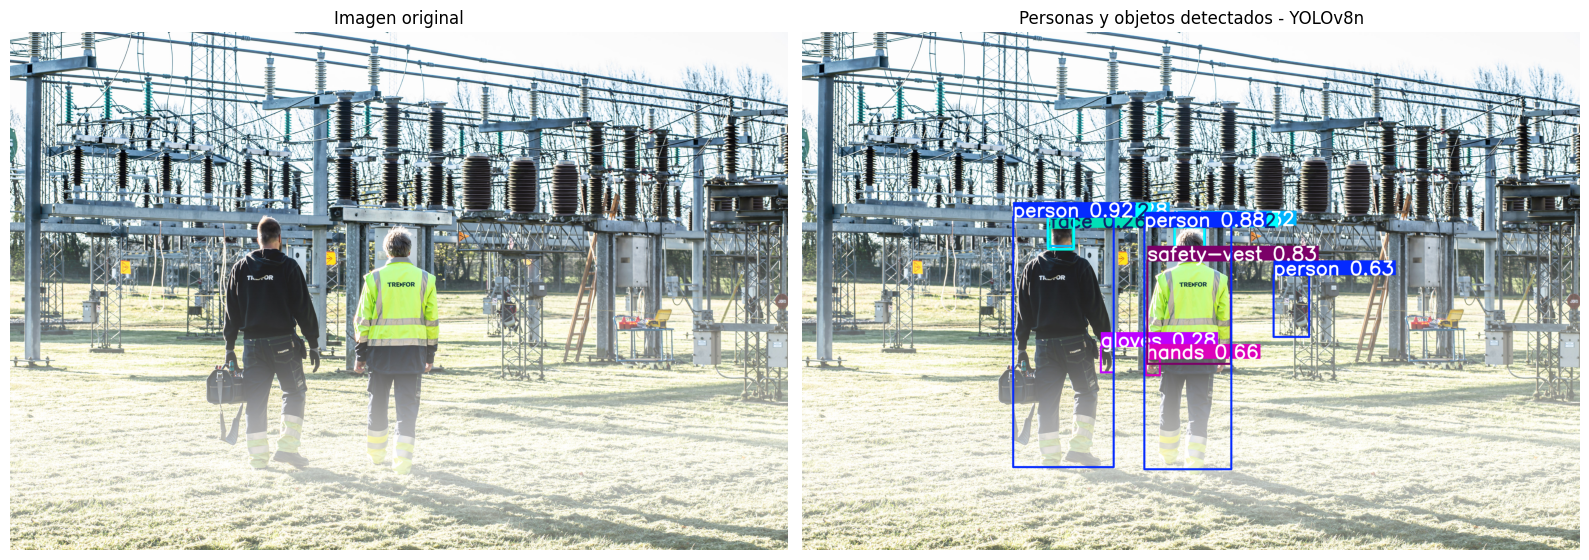


INFERENCIA FINALIZADA
Personas detectadas: 3
EPP detectados: 4
Zona: zona_1
Estado: pendiente_asociacion_por_persona

ARCHIVOS GUARDADOS
JSON: /content/drive/MyDrive/Examen_Hito2_EPP/Resultados/Inferencias_YOLO/20261115T030351287450Z_df8cc307/detecciones.json
Imagen anotada: /content/drive/MyDrive/Examen_Hito2_EPP/Resultados/Inferencias_YOLO/20261115T030351287450Z_df8cc307/prediccion.jpg
Imagen original: /content/drive/MyDrive/Examen_Hito2_EPP/Resultados/Inferencias_YOLO/20261115T030351287450Z_df8cc307/imagen_original.jpeg

Registro de ejecución: 20261115T030351287450Z_df8cc307
Los resultados del Hito 1 no fueron modificados.


In [29]:

# ============================================================
# 2.6. INFERENCIA DE PERSONAS Y EPP - HITO 2
# ============================================================

from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
from uuid import uuid4

import random
import json
import shutil
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import torch

from IPython.display import display

# ==========================================
# 1. CONFIGURACIÓN DE INFERENCIA
# ==========================================

DATASET = Path("/content/SH17_reducido")

# "validacion": imagen del dataset
# "subir": fotografía externa
MODO_IMAGEN = "validacion"

# Seleccionar clase para buscar un ejemplo
CLASE_EJEMPLO = "safety-vest"

# Zona que se desea supervisar
ZONA_SELECCIONADA = "zona_1"

REQUISITOS_ZONAS = {
    "zona_1": ["helmet", "safety-vest"],
    "zona_2": ["shoes", "gloves", "glasses"]
}

assert ZONA_SELECCIONADA in REQUISITOS_ZONAS

# Umbral de inferencia preliminar
CONFIANZA_MINIMA = 0.25

# Categorías utilizadas por el sistema
CATEGORIAS_PRIORITARIAS = {
    "person",
    "helmet",
    "safety-vest",
    "shoes",
    "gloves",
    "glasses"
}

# Se mantienen los demás EPP detectables
CATEGORIAS_EPP = {
    "helmet",
    "safety-vest",
    "shoes",
    "gloves",
    "glasses",
    "face-mask",
    "ear-mufs",
    "face-guard",
    "safety-suit",
    "medical-suit"
}

# Directorio independiente del Hito 2
SALIDA_INFERENCIA = (
    CARPETA_HITO2 / "Resultados" / "Inferencias_YOLO"
)

assert SALIDA_INFERENCIA.resolve().is_relative_to(
    CARPETA_HITO2.resolve()
)

assert PESOS_MODELO.is_file()

print("INFERENCIA DE PERSONAS Y EPP - HITO 2\n")
print("Modelo:", PESOS_MODELO.name)
print("Zona:", ZONA_SELECCIONADA)
print("EPP requeridos:", REQUISITOS_ZONAS[ZONA_SELECCIONADA])

# ==========================================
# 2. SELECCIONAR IMAGEN
# ==========================================

NOMBRES_CLASES = {
    int(k): v
    for k, v in modelo_recuperado.names.items()
}

assert len(NOMBRES_CLASES) == 17

if MODO_IMAGEN == "validacion":

    carpeta_img = DATASET / "images" / "val"
    carpeta_lbl = DATASET / "labels" / "val"

    id_objetivo = next(
        k for k, v in NOMBRES_CLASES.items()
        if v == CLASE_EJEMPLO
    )

    id_persona = next(
        k for k, v in NOMBRES_CLASES.items()
        if v == "person"
    )

    candidatos = []

    for imagen in sorted(carpeta_img.iterdir()):

        if imagen.suffix.lower() not in {
            ".jpg", ".jpeg", ".png", ".webp"
        }:
            continue

        etiqueta = carpeta_lbl / f"{imagen.stem}.txt"

        if not etiqueta.is_file():
            continue

        clases_imagen = {
            int(linea.split()[0])
            for linea in etiqueta.read_text(
                encoding="utf-8"
            ).splitlines()
            if linea.strip()
        }

        # Seleccionar ejemplos con persona
        # y con la clase de EPP indicada
        if (
            id_objetivo in clases_imagen
            and id_persona in clases_imagen
        ):
            candidatos.append(imagen)

    assert candidatos, (
        "No se encontraron imágenes con persona "
        "y la categoría seleccionada."
    )

    rng = random.Random(2026)
    IMAGEN_PRUEBA = rng.choice(candidatos)

elif MODO_IMAGEN == "subir":

    from google.colab import files

    archivos = files.upload()

    assert len(archivos) == 1, (
        "Debes subir una sola fotografía."
    )

    nombre = next(iter(archivos))
    IMAGEN_PRUEBA = Path(nombre).resolve()

else:
    raise ValueError("Modo de imagen no reconocido.")

assert IMAGEN_PRUEBA.is_file()

print("\nIMAGEN SELECCIONADA")
print(IMAGEN_PRUEBA.name)

# ==========================================
# 3. EJECUTAR INFERENCIA YOLO
# ==========================================

DISPOSITIVO = (
    0 if torch.cuda.is_available()
    else "cpu"
)

resultados = modelo_recuperado.predict(
    source=str(IMAGEN_PRUEBA),
    imgsz=640,
    conf=CONFIANZA_MINIMA,
    device=DISPOSITIVO,
    verbose=False
)

assert len(resultados) == 1

resultado = resultados[0]

# ==========================================
# 4. EXTRAER TODAS LAS DETECCIONES
# ==========================================

detecciones = []

for caja in resultado.boxes:

    clase_id = int(caja.cls.item())
    confianza = float(caja.conf.item())

    x1, y1, x2, y2 = (
        caja.xyxy[0].cpu().tolist()
    )

    detecciones.append({
        "clase_id": clase_id,
        "clase": resultado.names[clase_id],
        "confianza": round(confianza, 4),
        "x1": round(x1, 2),
        "y1": round(y1, 2),
        "x2": round(x2, 2),
        "y2": round(y2, 2)
    })

columnas = [
    "clase_id", "clase", "confianza",
    "x1", "y1", "x2", "y2"
]

df_detecciones = pd.DataFrame(
    detecciones,
    columns=columnas
)

print("\nRESULTADOS DE LA INFERENCIA")
print("Total de objetos detectados:", len(detecciones))

if not df_detecciones.empty:

    display(
        df_detecciones.sort_values(
            "confianza",
            ascending=False
        ).reset_index(drop=True)
    )

else:
    print("No se detectaron objetos con este umbral.")

# ==========================================
# 5. IDENTIFICAR PERSONAS
# ==========================================

detecciones_personas = [
    d for d in detecciones
    if d["clase"] == "person"
]

cantidad_personas = len(detecciones_personas)

print("\nDETECCIÓN DE PERSONAS")
print("Personas detectadas:", cantidad_personas)

if cantidad_personas == 0:
    print(
        "ATENCIÓN: No se identificaron personas. "
        "La inspección requerirá revisión."
    )

# ==========================================
# 6. IDENTIFICAR EPP
# ==========================================

detecciones_epp = [
    d for d in detecciones
    if d["clase"] in CATEGORIAS_EPP
]

resumen_epp = Counter(
    d["clase"] for d in detecciones_epp
)

print("\nELEMENTOS DE PROTECCIÓN DETECTADOS")

if resumen_epp:
    for clase, cantidad in sorted(resumen_epp.items()):
        print(f"{clase}: {cantidad}")
else:
    print("No se detectaron EPP con este umbral.")

# ==========================================
# 7. IDENTIFICAR CATEGORÍAS PRIORITARIAS
# ==========================================

resumen_prioritario = Counter(
    d["clase"]
    for d in detecciones
    if d["clase"] in CATEGORIAS_PRIORITARIAS
)

print("\nRESUMEN OPERACIONAL")

for clase in sorted(CATEGORIAS_PRIORITARIAS):
    print(
        f"{clase}: "
        f"{resumen_prioritario.get(clase, 0)}"
    )

# ==========================================
# 8. VISUALIZAR RESULTADOS
# ==========================================

imagen_original = cv2.imread(
    str(IMAGEN_PRUEBA)
)

assert imagen_original is not None, (
    "No se pudo abrir la fotografía."
)

imagen_anotada = resultado.plot()

fig, axes = plt.subplots(
    1, 2, figsize=(16, 7)
)

axes[0].imshow(
    cv2.cvtColor(
        imagen_original,
        cv2.COLOR_BGR2RGB
    )
)

axes[0].set_title("Imagen original")
axes[0].axis("off")

axes[1].imshow(
    cv2.cvtColor(
        imagen_anotada,
        cv2.COLOR_BGR2RGB
    )
)

axes[1].set_title(
    "Personas y objetos detectados - YOLOv8n"
)
axes[1].axis("off")

plt.tight_layout()
plt.show()

# ==========================================
# 9. CREAR REGISTRO DE EJECUCIÓN
# ==========================================

FECHA_UTC = datetime.now(timezone.utc)

ID_EJECUCION = (
    FECHA_UTC.strftime("%Y%m%dT%H%M%S%fZ")
    + "_"
    + uuid4().hex[:8]
)

CARPETA_EJECUCION = (
    SALIDA_INFERENCIA / ID_EJECUCION
)

# Evitar sobrescribir registros previos
CARPETA_EJECUCION.mkdir(
    parents=True,
    exist_ok=False
)

# ==========================================
# 10. GENERAR JSON ESTRUCTURADO
# ==========================================

estado_inferencia = (
    "pendiente_asociacion_por_persona"
    if cantidad_personas > 0
    else "requiere_revision_deteccion_personas"
)

salida_json = {
    "ejecucion_id": ID_EJECUCION,
    "fecha_hora_utc": FECHA_UTC.isoformat(),
    "imagen": IMAGEN_PRUEBA.name,
    "origen_imagen": MODO_IMAGEN,
    "modelo": "YOLOv8n_SH17_Hito2",
    "checkpoint": str(PESOS_MODELO),
    "zona_id": ZONA_SELECCIONADA,
    "epp_requeridos_zona": REQUISITOS_ZONAS[
        ZONA_SELECCIONADA
    ],
    "confianza_minima": CONFIANZA_MINIMA,
    "total_detecciones": len(detecciones),
    "cantidad_personas_detectadas": cantidad_personas,
    "detecciones": detecciones,
    "resumen_epp": dict(resumen_epp),
    "resumen_prioritario": dict(resumen_prioritario),
    "estado": estado_inferencia,
    "advertencia": (
        "La presencia de un EPP en la imagen "
        "no demuestra que una persona específica "
        "lo esté utilizando. La ausencia de una "
        "detección tampoco confirma su ausencia."
    )
}

ARCHIVO_DETECCIONES = (
    CARPETA_EJECUCION / "detecciones.json"
)

RUTA_IMAGEN_ANOTADA = (
    CARPETA_EJECUCION / "prediccion.jpg"
)

RUTA_IMAGEN_ORIGINAL = (
    CARPETA_EJECUCION
    / f"imagen_original{IMAGEN_PRUEBA.suffix.lower()}"
)

# Guardar JSON sin reemplazar otro archivo
with open(
    ARCHIVO_DETECCIONES,
    "x",
    encoding="utf-8"
) as f:
    json.dump(
        salida_json,
        f,
        indent=4,
        ensure_ascii=False
    )

# Guardar imagen con detecciones
guardado_correcto = cv2.imwrite(
    str(RUTA_IMAGEN_ANOTADA),
    imagen_anotada
)

assert guardado_correcto

# Conservar fotografía original
shutil.copy2(
    IMAGEN_PRUEBA,
    RUTA_IMAGEN_ORIGINAL
)

# ==========================================
# 11. RESUMEN FINAL
# ==========================================

print("\nINFERENCIA FINALIZADA")

print("Personas detectadas:", cantidad_personas)
print("EPP detectados:", len(detecciones_epp))
print("Zona:", ZONA_SELECCIONADA)
print("Estado:", estado_inferencia)

print("\nARCHIVOS GUARDADOS")

print("JSON:", ARCHIVO_DETECCIONES)
print("Imagen anotada:", RUTA_IMAGEN_ANOTADA)
print("Imagen original:", RUTA_IMAGEN_ORIGINAL)

print("\nRegistro de ejecución:", ID_EJECUCION)
print("Los resultados del Hito 1 no fueron modificados.")



### 2.7. Asociación espacial de EPP a cada trabajador

Después de identificar las personas y los elementos de protección personal mediante YOLOv8n, se implementa un procedimiento de asociación espacial para estimar qué EPP corresponde a cada trabajador detectado.

La categoría `person` constituye la referencia central del análisis, dado que el objetivo del sistema no es solamente reconocer objetos, sino supervisar individualmente su utilización.

El procedimiento considera cinco categorías de EPP:

- `helmet`: casco de seguridad.
- `safety-vest`: chaleco de seguridad.
- `shoes`: zapatos.
- `gloves`: guantes.
- `glasses`: lentes.

Para cada persona se obtiene su caja delimitadora, confianza de detección e identificador individual. Los trabajadores se ordenan horizontalmente para facilitar su identificación dentro de cada fotografía.

La asociación considera:

1. La proporción del área de cada EPP que se superpone con la caja de una persona.
2. La posición relativa del elemento respecto del cuerpo del trabajador.
3. La proximidad horizontal al centro de la persona.
4. La existencia de otras personas con puntuaciones de asociación similares.

Se utilizan regiones anatómicas aproximadas para casco, chaleco, lentes y zapatos. Para los guantes se considera una región más amplia, debido a la movilidad de los brazos.

La detección de personas utilizará un umbral inicial de confianza de 0,35 y los EPP un umbral de 0,25. Estos valores son preliminares y deberán justificarse mediante evaluaciones posteriores sobre el conjunto de validación.

Se considerará una asociación candidata cuando al menos el 35 % del área del EPP se encuentre dentro de la caja de la persona y su posición sea compatible con la categoría detectada.

Si un elemento presenta puntuaciones similares para dos personas, se clasificará como asociación ambigua y no se asignará automáticamente.

Los resultados distinguirán entre:

- EPP detectados y asociados geométricamente.
- EPP detectados sin asociación confiable.
- EPP cuya detección no pudo confirmarse para una persona.

La asociación geométrica constituye una estimación visual y no demuestra por sí sola que un trabajador esté utilizando correctamente el elemento de protección.

Especialmente para guantes y zapatos, una detección no garantiza que ambos elementos del par estén presentes ni que sean equipos de protección certificados.

Los resultados se almacenarán en un archivo JSON independiente por ejecución, conservando las detecciones originales, las asociaciones realizadas y los casos que requieren revisión humana.

Este procedimiento permitirá desarrollar posteriormente la evaluación de los EPP requeridos según la zona de seguridad.


In [30]:

# ============================================================
# 2.7. ASOCIACIÓN DE EPP A CADA TRABAJADOR - HITO 2
# ============================================================

import json
import pandas as pd
from pathlib import Path

# ==========================================
# 1. CARGAR DETECCIONES DE LA SECCIÓN 2.6
# ==========================================

assert ARCHIVO_DETECCIONES.is_file()

CARPETA_EJECUCION = ARCHIVO_DETECCIONES.parent

assert CARPETA_EJECUCION.resolve().is_relative_to(
    CARPETA_HITO2.resolve()
)

with open(
    ARCHIVO_DETECCIONES,
    "r",
    encoding="utf-8"
) as f:
    datos_yolo = json.load(f)

detecciones = datos_yolo["detecciones"]

assert datos_yolo["ejecucion_id"] == ID_EJECUCION

# ==========================================
# 2. PARÁMETROS DE ASOCIACIÓN
# ==========================================

UMBRAL_PERSONA = 0.35
UMBRAL_EPP = 0.25
SUPERPOSICION_MINIMA = 0.35
DIFERENCIA_AMBIGUEDAD = 0.08

EPP_OBJETIVO = [
    "helmet",
    "safety-vest",
    "shoes",
    "gloves",
    "glasses"
]

# Rangos verticales relativos a la caja
# de la persona. Son aproximaciones
# geométricas, no reglas de cumplimiento.

REGIONES_EPP = {
    "helmet": (-0.10, 0.38),
    "safety-vest": (0.15, 0.82),
    "glasses": (0.00, 0.45),
    "gloves": (0.05, 1.05),
    "shoes": (0.58, 1.10)
}

print("ASOCIACIÓN DE EPP POR TRABAJADOR\n")

print("Imagen:", datos_yolo["imagen"])
print("Zona:", datos_yolo["zona_id"])

# ==========================================
# 3. IDENTIFICAR PERSONAS
# ==========================================

personas = [
    d for d in detecciones
    if d["clase"] == "person"
    and d["confianza"] >= UMBRAL_PERSONA
]

personas = sorted(
    personas,
    key=lambda d: (
        d["x1"],
        d["y1"]
    )
)

print("\nPersonas evaluables:", len(personas))

personas_baja_confianza = [
    d for d in detecciones
    if d["clase"] == "person"
    and d["confianza"] < UMBRAL_PERSONA
]

# ==========================================
# 4. FUNCIONES GEOMÉTRICAS
# ==========================================

def proporcion_dentro(objeto, persona):
    """Área del objeto dentro de la persona."""

    x1 = max(objeto["x1"], persona["x1"])
    y1 = max(objeto["y1"], persona["y1"])
    x2 = min(objeto["x2"], persona["x2"])
    y2 = min(objeto["y2"], persona["y2"])

    interseccion = (
        max(0, x2 - x1) *
        max(0, y2 - y1)
    )

    area = (
        max(0, objeto["x2"] - objeto["x1"]) *
        max(0, objeto["y2"] - objeto["y1"])
    )

    return interseccion / area if area > 0 else 0.0


def posicion_compatible(objeto, persona):
    """Comprueba la región vertical aproximada."""

    clase = objeto["clase"]

    altura = persona["y2"] - persona["y1"]

    if altura <= 0:
        return False

    centro_y = (
        objeto["y1"] + objeto["y2"]
    ) / 2

    posicion_relativa = (
        centro_y - persona["y1"]
    ) / altura

    minimo, maximo = REGIONES_EPP[clase]

    return minimo <= posicion_relativa <= maximo


def puntuacion_asociacion(objeto, persona):
    """Combina superposición y proximidad."""

    superposicion = proporcion_dentro(
        objeto, persona
    )

    ancho_persona = max(
        persona["x2"] - persona["x1"], 1
    )

    centro_objeto = (
        objeto["x1"] + objeto["x2"]
    ) / 2

    centro_persona = (
        persona["x1"] + persona["x2"]
    ) / 2

    distancia = abs(
        centro_objeto - centro_persona
    ) / (ancho_persona / 2)

    proximidad = 1 - min(distancia, 1)

    puntuacion = (
        0.80 * superposicion +
        0.20 * proximidad
    )

    return puntuacion, superposicion

# ==========================================
# 5. CREAR REGISTROS POR PERSONA
# ==========================================

resultados_personas = []

for indice, persona in enumerate(personas, 1):

    resultados_personas.append({
        "persona_id": indice,
        "confianza_persona": persona["confianza"],
        "bbox": {
            "x1": persona["x1"],
            "y1": persona["y1"],
            "x2": persona["x2"],
            "y2": persona["y2"]
        },
        "epp_detectados": {},
        "epp_asociados": [],
        "epp_no_confirmados": [],
        "estado": "pendiente_evaluacion_zona"
    })

# ==========================================
# 6. ASOCIAR DETECCIONES DE EPP
# ==========================================

epp_candidatos = [
    d for d in detecciones
    if d["clase"] in EPP_OBJETIVO
    and d["confianza"] >= UMBRAL_EPP
]

epp_sin_asignar = []

for epp in epp_candidatos:

    candidatos = []

    for i, persona in enumerate(personas):

        puntuacion, superposicion = (
            puntuacion_asociacion(epp, persona)
        )

        if superposicion < SUPERPOSICION_MINIMA:
            continue

        if not posicion_compatible(epp, persona):
            continue

        candidatos.append({
            "indice": i,
            "puntuacion": puntuacion,
            "superposicion": superposicion
        })

    candidatos.sort(
        key=lambda c: c["puntuacion"],
        reverse=True
    )

    if not candidatos:

        epp_sin_asignar.append({
            **epp,
            "motivo": "sin_asociacion_espacial_confiable"
        })

        continue

    mejor = candidatos[0]

    # Evitar asignar un mismo EPP a personas
    # que presentan puntuaciones parecidas.
    if len(candidatos) > 1:

        diferencia = (
            mejor["puntuacion"] -
            candidatos[1]["puntuacion"]
        )

        if diferencia < DIFERENCIA_AMBIGUEDAD:

            epp_sin_asignar.append({
                **epp,
                "motivo": "asociacion_ambigua"
            })

            continue

    registro = resultados_personas[
        mejor["indice"]
    ]

    asociacion = {
        "clase": epp["clase"],
        "confianza": epp["confianza"],
        "puntuacion": round(
            mejor["puntuacion"], 4
        ),
        "superposicion": round(
            mejor["superposicion"], 4
        ),
        "bbox": {
            "x1": epp["x1"],
            "y1": epp["y1"],
            "x2": epp["x2"],
            "y2": epp["y2"]
        }
    }

    registro["epp_asociados"].append(asociacion)

    clase = epp["clase"]

    anterior = registro[
        "epp_detectados"
    ].get(clase)

    # Mantener la detección de mayor confianza
    # en el resumen por categoría.
    if (
        anterior is None
        or asociacion["confianza"] > anterior["confianza"]
    ):

        registro["epp_detectados"][clase] = {
            "confianza": asociacion["confianza"],
            "superposicion": asociacion["superposicion"],
            "puntuacion": asociacion["puntuacion"],
            "cantidad": 0
        }

# ==========================================
# 7. CONTAR EPP Y NO CONFIRMADOS
# ==========================================

requeridos_zona = datos_yolo[
    "epp_requeridos_zona"
]

for registro in resultados_personas:

    for clase in registro["epp_detectados"]:

        cantidad = sum(
            epp["clase"] == clase
            for epp in registro["epp_asociados"]
        )

        registro["epp_detectados"][
            clase
        ]["cantidad"] = cantidad

    registro["epp_no_confirmados"] = [
        clase
        for clase in requeridos_zona
        if clase not in registro["epp_detectados"]
    ]

# ==========================================
# 8. PRESENTAR RESULTADOS
# ==========================================

filas = []

for registro in resultados_personas:

    fila = {
        "Trabajador": registro["persona_id"],
        "Confianza persona": registro["confianza_persona"]
    }

    for clase in EPP_OBJETIVO:

        fila[clase] = (
            "Asociado"
            if clase in registro["epp_detectados"]
            else "No confirmado"
        )

    filas.append(fila)

df_trabajadores = pd.DataFrame(filas)

print("\nRESULTADOS POR TRABAJADOR")

if df_trabajadores.empty:
    print("No se identificaron personas evaluables.")
else:
    display(df_trabajadores)

print("\nRESUMEN")
print("Personas evaluadas:", len(resultados_personas))
print("Personas con confianza insuficiente:",
      len(personas_baja_confianza))
print("EPP candidatos:", len(epp_candidatos))
print("EPP sin asignación:", len(epp_sin_asignar))

# ==========================================
# 9. GENERAR JSON ESTRUCTURADO
# ==========================================

resultado_final = {
    "ejecucion_id": datos_yolo["ejecucion_id"],
    "fecha_hora_utc": datos_yolo["fecha_hora_utc"],
    "imagen": datos_yolo["imagen"],
    "modelo": datos_yolo["modelo"],
    "zona_id": datos_yolo["zona_id"],
    "epp_requeridos_zona": requeridos_zona,
    "etapa": "asociacion_epp_por_persona",
    "cantidad_personas_detectadas": datos_yolo[
        "cantidad_personas_detectadas"
    ],
    "cantidad_personas_evaluables": len(
        resultados_personas
    ),
    "personas_baja_confianza": personas_baja_confianza,
    "trabajadores": resultados_personas,
    "epp_sin_asignar": epp_sin_asignar,
    "parametros_asociacion": {
        "umbral_persona": UMBRAL_PERSONA,
        "umbral_epp": UMBRAL_EPP,
        "superposicion_minima": SUPERPOSICION_MINIMA,
        "diferencia_ambiguedad": DIFERENCIA_AMBIGUEDAD
    },
    "advertencia": (
        "La asociación es geométrica y no confirma "
        "el uso correcto de EPP. Las detecciones "
        "no asignadas requieren revisión humana."
    )
}

ARCHIVO_ASOCIACION = (
    CARPETA_EJECUCION / "asociacion_personas.json"
)

assert not ARCHIVO_ASOCIACION.exists(), (
    "Ya existe este resultado de asociación."
)

with open(
    ARCHIVO_ASOCIACION,
    "x",
    encoding="utf-8"
) as f:

    json.dump(
        resultado_final,
        f,
        indent=4,
        ensure_ascii=False
    )

print("\nASOCIACIÓN FINALIZADA")
print("Archivo JSON:", ARCHIVO_ASOCIACION)
print("Hito 1 modificado: No")


ASOCIACIÓN DE EPP POR TRABAJADOR

Imagen: pexels-photo-13820151.jpeg
Zona: zona_1

Personas evaluables: 3

RESULTADOS POR TRABAJADOR


,Trabajador,Confianza persona,helmet,safety-vest,shoes,gloves,glasses
0,1,0.9154,Asociado,No confirmado,No confirmado,Asociado,No confirmado
1,2,0.8825,Asociado,Asociado,No confirmado,No confirmado,No confirmado
2,3,0.6261,No confirmado,No confirmado,No confirmado,No confirmado,No confirmado



RESUMEN
Personas evaluadas: 3
Personas con confianza insuficiente: 0
EPP candidatos: 4
EPP sin asignación: 0

ASOCIACIÓN FINALIZADA
Archivo JSON: /content/drive/MyDrive/Examen_Hito2_EPP/Resultados/Inferencias_YOLO/20261115T030351287450Z_df8cc307/asociacion_personas.json
Hito 1 modificado: No



### 2.8. Evaluación de elementos de protección personal según zona de seguridad

Se desarrolla un sistema de evaluación basado en reglas configurables en Python, utilizando las detecciones y asociaciones de EPP obtenidas mediante YOLOv8n.

El objetivo es identificar, para cada trabajador detectado, cuáles de los elementos exigidos por su zona cuentan con evidencia visual de asociación y cuáles requieren verificación humana.

#### Zonas de supervisión

**Zona 1: Casco y chaleco de seguridad**

Se establecen los siguientes elementos de protección personal:

- Casco (`helmet`).
- Chaleco de seguridad (`safety-vest`).

**Zona 2: Zapatos, guantes y lentes**

Se establecen los siguientes elementos de protección personal:

- Zapatos (`shoes`).
- Guantes (`gloves`).
- Lentes (`glasses`).

Ambas zonas utilizan el mismo modelo YOLOv8n, entrenado para reconocer las 17 categorías del dataset SH17. La diferencia entre zonas corresponde a las reglas utilizadas para interpretar las detecciones.

#### Procedimiento de evaluación

Para cada imagen se recuperará la zona seleccionada durante la inferencia y se consultará la configuración correspondiente.

El sistema analizará cada trabajador y clasificará los EPP requeridos en dos estados:

- **Detectado y asociado:** existe una detección que cumple los criterios geométricos de asociación con el trabajador.
- **No confirmado:** no existe evidencia visual suficiente para asociar el elemento requerido a esa persona.

Los elementos no confirmados se identificarán como casos que requieren verificación humana, sin interpretar automáticamente su ausencia como un incumplimiento.

Adicionalmente, se considerarán las personas con confianza insuficiente y los EPP que no pudieron asociarse de manera confiable.

Si no se identifican personas evaluables, la inspección se clasificará como pendiente de revisión y no como una inspección satisfactoria.

#### Indicador operacional

Se calculará la proporción de trabajadores evaluados que presentan al menos un EPP requerido no confirmado:

\[
\text{Tasa de revisión potencial} =
\frac{\text{Trabajadores con EPP no confirmados}}
{\text{Trabajadores evaluables}} \times 100
\]

Este indicador permitirá monitorear los casos que necesitan revisión, pero no representa directamente una tasa de incumplimiento real.

Cuando no existan trabajadores evaluables, el indicador se registrará como no calculable.

#### Registro de resultados

La evaluación generará una tabla por trabajador y un archivo JSON estructurado que contendrá:

- Zona y requisitos aplicados.
- Personas evaluadas.
- EPP detectados y asociados por trabajador.
- EPP no confirmados.
- Casos de asociación ambigua.
- Indicadores de revisión potencial.
- Estado general de la inspección.
- Referencias de las reglas utilizadas.

Los resultados se almacenarán en la carpeta independiente de la ejecución correspondiente al Hito 2.

Las decisiones finales sobre cumplimiento de seguridad permanecerán bajo responsabilidad del profesional designado para la supervisión.



In [31]:

# ============================================================
# 2.8. EVALUACIÓN DE EPP POR ZONA - HITO 2
# ============================================================

from pathlib import Path
import json
import pandas as pd

# ==========================================
# 1. CONFIGURACIÓN CENTRALIZADA DE ZONAS
# ==========================================

REGLAS_ZONAS = {
    "zona_1": {
        "nombre": "Zona 1 - Casco y chaleco",
        "version": "1.0",
        "validacion_profesional": False,
        "contexto": "Prototipo académico de supervisión EPP",

        "epp_requeridos": [
            "helmet",
            "safety-vest"
        ],

        "riesgos": [
            {
                "peligro": "Golpes o caída de objetos",
                "epp": "helmet"
            },
            {
                "peligro": "Tránsito y visibilidad",
                "epp": "safety-vest"
            }
        ]
    },

    "zona_2": {
        "nombre": "Zona 2 - Zapatos, guantes y lentes",
        "version": "1.0",
        "validacion_profesional": False,
        "contexto": "Prototipo académico de supervisión EPP",

        "epp_requeridos": [
            "shoes",
            "gloves",
            "glasses"
        ],

        "riesgos": [
            {
                "peligro": "Golpes o lesiones en los pies",
                "epp": "shoes"
            },
            {
                "peligro": "Lesiones durante manipulación",
                "epp": "gloves"
            },
            {
                "peligro": "Proyección de partículas",
                "epp": "glasses"
            }
        ]
    }
}

# Referencias normativas generales.
# No establecen automáticamente estas
# cinco exigencias para cualquier instalación.

FUNDAMENTO_NORMATIVO = [
    {
        "norma": "DS 594",
        "articulo": "53",
        "alcance": "EPP adecuados al riesgo"
    },
    {
        "norma": "DS 44",
        "articulo": "7 y 13",
        "alcance": "Matriz de riesgos y uso de EPP"
    },
    {
        "norma": "DS 132",
        "articulo": "32",
        "alcance": "Seguridad minera, cuando corresponda"
    }
]

for zona in REGLAS_ZONAS.values():

    zona["fundamento_normativo"] = FUNDAMENTO_NORMATIVO

    zona["origen_regla_especifica"] = (
        "Configuración académica simplificada. "
        "Requiere validación mediante matriz de riesgos."
    )

# ==========================================
# 2. REGISTRAR REGLAS SIN SOBRESCRIBIR
# ==========================================

CARPETA_REGLAS = (
    CARPETA_HITO2 / "Resultados" / "Reglas"
)

assert CARPETA_REGLAS.resolve().is_relative_to(
    CARPETA_HITO2.resolve()
)

CARPETA_REGLAS.mkdir(
    parents=True,
    exist_ok=True
)

ARCHIVO_REGLAS = (
    CARPETA_REGLAS / "reglas_epp_zonas_v1.json"
)

if ARCHIVO_REGLAS.exists():

    with open(
        ARCHIVO_REGLAS,
        "r",
        encoding="utf-8"
    ) as f:
        reglas_anteriores = json.load(f)

    assert reglas_anteriores == REGLAS_ZONAS, (
        "Ya existen reglas diferentes con esta versión. "
        "Crea una nueva versión sin sobrescribir."
    )

else:

    with open(
        ARCHIVO_REGLAS,
        "x",
        encoding="utf-8"
    ) as f:
        json.dump(
            REGLAS_ZONAS,
            f,
            indent=4,
            ensure_ascii=False
        )

# ==========================================
# 3. RECUPERAR ASOCIACIÓN DE PERSONAS
# ==========================================

assert ARCHIVO_ASOCIACION.is_file()

with open(
    ARCHIVO_ASOCIACION,
    "r",
    encoding="utf-8"
) as f:
    datos = json.load(f)

ZONA_EVALUADA = datos["zona_id"]

assert ZONA_EVALUADA in REGLAS_ZONAS

regla = REGLAS_ZONAS[ZONA_EVALUADA]

assert (
    datos["epp_requeridos_zona"]
    == regla["epp_requeridos"]
), "Los requisitos no coinciden con la zona."

trabajadores = datos["trabajadores"]

print("EVALUACIÓN POR ZONA - HITO 2\n")
print("Zona:", regla["nombre"])
print("Requeridos:", regla["epp_requeridos"])
print("Personas evaluables:", len(trabajadores))

# ==========================================
# 4. EVALUAR CADA TRABAJADOR
# ==========================================

evaluaciones = []
filas = []

for trabajador in trabajadores:

    detectados = trabajador["epp_detectados"]

    confirmados = []
    no_confirmados = []
    detalle = {}

    for epp in regla["epp_requeridos"]:

        if epp in detectados:

            confirmados.append(epp)

            detalle[epp] = {
                "estado": "detectado_asociado",
                "confianza": detectados[epp]["confianza"],
                "cantidad_detectada": detectados[epp]["cantidad"]
            }

        else:

            no_confirmados.append(epp)

            detalle[epp] = {
                "estado": "no_confirmado",
                "confianza": None,
                "cantidad_detectada": 0
            }

    estado = (
        "epp_no_confirmados_revision_pendiente"
        if no_confirmados
        else "epp_asociados_revision_pendiente"
    )

    evaluacion = {
        "persona_id": trabajador["persona_id"],
        "confianza_persona": trabajador[
            "confianza_persona"
        ],
        "epp_requeridos": regla["epp_requeridos"],
        "epp_detectados": confirmados,
        "epp_no_confirmados": no_confirmados,
        "detalle_epp": detalle,
        "estado": estado,
        "revision_humana": True
    }

    evaluaciones.append(evaluacion)

    fila = {
        "Trabajador": trabajador["persona_id"],
        "Zona": regla["nombre"],
        "EPP detectados": ", ".join(confirmados) or "Ninguno",
        "EPP no confirmados": (
            ", ".join(no_confirmados) or "Ninguno"
        ),
        "Estado": estado
    }

    filas.append(fila)

# ==========================================
# 5. INDICADORES OPERACIONALES
# ==========================================

cantidad_trabajadores = len(evaluaciones)

cantidad_revision = sum(
    len(t["epp_no_confirmados"]) > 0
    for t in evaluaciones
)

tasa_revision = (
    round(
        100 * cantidad_revision / cantidad_trabajadores,
        2
    )
    if cantidad_trabajadores > 0
    else None
)

personas_baja_confianza = len(
    datos["personas_baja_confianza"]
)

epp_sin_asignar = len(
    datos["epp_sin_asignar"]
)

# ==========================================
# 6. ESTADO DE INSPECCIÓN
# ==========================================

if cantidad_trabajadores == 0:

    estado_inspeccion = (
        "sin_personas_evaluables_revision_requerida"
    )

elif (
    cantidad_revision > 0
    or personas_baja_confianza > 0
    or epp_sin_asignar > 0
):

    estado_inspeccion = (
        "revision_prioritaria_pendiente"
    )

else:

    estado_inspeccion = (
        "revision_rutinaria_pendiente"
    )

# ==========================================
# 7. MOSTRAR RESULTADOS
# ==========================================

df_evaluacion_zona = pd.DataFrame(filas)

print("\nEVALUACIÓN POR TRABAJADOR")

if df_evaluacion_zona.empty:
    print("No hay personas evaluables.")
else:
    display(df_evaluacion_zona)

print("\nINDICADORES")

print("Trabajadores evaluables:", cantidad_trabajadores)
print("Con EPP no confirmados:", cantidad_revision)
print("Personas de baja confianza:", personas_baja_confianza)
print("EPP sin asignación:", epp_sin_asignar)

print(
    "Tasa de revisión potencial:",
    (
        f"{tasa_revision}%"
        if tasa_revision is not None
        else "No calculable"
    )
)

print("Estado:", estado_inspeccion)

# ==========================================
# 8. GENERAR JSON FINAL
# ==========================================

resultado_evaluacion = {
    "ejecucion_id": datos["ejecucion_id"],
    "fecha_hora_utc": datos["fecha_hora_utc"],
    "imagen": datos["imagen"],
    "modelo": datos["modelo"],
    "zona_id": ZONA_EVALUADA,
    "zona": regla["nombre"],
    "version_reglas": regla["version"],
    "validacion_profesional_reglas": regla[
        "validacion_profesional"
    ],
    "fundamento_normativo": regla[
        "fundamento_normativo"
    ],
    "origen_regla_especifica": regla[
        "origen_regla_especifica"
    ],
    "riesgos": regla["riesgos"],
    "trabajadores": evaluaciones,
    "cantidad_trabajadores_analizados": (
        cantidad_trabajadores
    ),
    "cantidad_con_epp_no_confirmados": (
        cantidad_revision
    ),
    "indicadores": {
        "tasa_revision_potencial_pct": tasa_revision,
        "personas_baja_confianza": (
            personas_baja_confianza
        ),
        "epp_sin_asignar": epp_sin_asignar
    },
    "estado_inspeccion": estado_inspeccion,
    "responsable_decision": (
        "Supervisor de prevención de riesgos del turno"
    ),
    "revision_humana_requerida": True,
    "advertencia": (
        "Las detecciones son indicios visuales. "
        "No confirman uso correcto o certificación "
        "del EPP. Los elementos no detectados "
        "no se consideran automáticamente ausentes."
    )
}

ARCHIVO_EVALUACION = (
    CARPETA_EJECUCION / "evaluacion_normativa.json"
)

assert not ARCHIVO_EVALUACION.exists(), (
    "Ya existe esta evaluación. "
    "No se sobrescribirá."
)

with open(
    ARCHIVO_EVALUACION,
    "x",
    encoding="utf-8"
) as f:

    json.dump(
        resultado_evaluacion,
        f,
        indent=4,
        ensure_ascii=False
    )

# ==========================================
# 9. FINALIZAR
# ==========================================

print("\nEVALUACIÓN FINALIZADA")

print("Archivo de reglas:", ARCHIVO_REGLAS)
print("Resultado:", ARCHIVO_EVALUACION)
print("Revisión humana requerida: Sí")
print("Hito 1 modificado: No")


EVALUACIÓN POR ZONA - HITO 2

Zona: Zona 1 - Casco y chaleco
Requeridos: ['helmet', 'safety-vest']
Personas evaluables: 3

EVALUACIÓN POR TRABAJADOR


,Trabajador,Zona,EPP detectados,EPP no confirmados,Estado
0,1,Zona 1 - Casco y chaleco,helmet,safety-vest,epp_no_confirmados_revision_pendiente
1,2,Zona 1 - Casco y chaleco,"helmet, safety-vest",Ninguno,epp_asociados_revision_pendiente
2,3,Zona 1 - Casco y chaleco,Ninguno,"helmet, safety-vest",epp_no_confirmados_revision_pendiente



INDICADORES
Trabajadores evaluables: 3
Con EPP no confirmados: 2
Personas de baja confianza: 0
EPP sin asignación: 0
Tasa de revisión potencial: 66.67%
Estado: revision_prioritaria_pendiente

EVALUACIÓN FINALIZADA
Archivo de reglas: /content/drive/MyDrive/Examen_Hito2_EPP/Resultados/Reglas/reglas_epp_zonas_v1.json
Resultado: /content/drive/MyDrive/Examen_Hito2_EPP/Resultados/Inferencias_YOLO/20261115T030351287450Z_df8cc307/evaluacion_normativa.json
Revisión humana requerida: Sí
Hito 1 modificado: No



### 2.8.1. Fundamentos normativos y verificación de las reglas de seguridad

Las reglas utilizadas en las dos zonas de supervisión se fundamentan en el enfoque de identificación de peligros, evaluación de riesgos y selección de medidas preventivas presente en la normativa chilena.

Se consideran las siguientes referencias:

- **DS N.º 594, artículo 53:** establece obligaciones respecto de la provisión y utilización de elementos de protección personal adecuados a los riesgos.
- **DS N.º 44, artículo 7:** regula la matriz de identificación de peligros y evaluación de riesgos.
- **DS N.º 44, artículo 13:** establece disposiciones relativas al uso y provisión de EPP adecuados al riesgo.
- **DS N.º 132, artículo 32:** establece disposiciones específicas para las empresas mineras respecto de los EPP según funciones y riesgos efectivos.

Las exigencias particulares definidas para las zonas 1 y 2 corresponden a una configuración académica simplificada. No se consideran obligaciones universales derivadas literalmente de estas disposiciones.

La utilización real de las reglas requiere una evaluación de riesgos específica de la instalación y validación por un profesional competente.

Adicionalmente, las clases `shoes` y `glasses` del dataset representan categorías visuales y no certifican que los elementos reconocidos sean necesariamente zapatos de seguridad o lentes de protección industrial.

La configuración centralizada se almacena en `reglas_epp_zonas_v1.json`. Esta subsección verificará su contenido sin volver a definir las reglas ni repetir la evaluación.

**Referencias normativas**

- Ministerio de Salud. (1999). *Decreto Supremo N.º 594*. https://www.bcn.cl/leychile/navegar?idNorma=167766
- Ministerio del Trabajo y Previsión Social. (2024). *Decreto N.º 44*. https://www.bcn.cl/leychile/navegar?idNorma=1205298
- Ministerio de Minería. (2002). *Decreto Supremo N.º 132*. https://www.bcn.cl/leychile/navegar?idNorma=221064


In [32]:

# ============================================================
# 2.8.1. VERIFICACIÓN DE REGLAS DOCUMENTADAS
# ============================================================

import json
import pandas as pd

assert ARCHIVO_REGLAS.is_file()

with open(
    ARCHIVO_REGLAS,
    "r",
    encoding="utf-8"
) as f:
    reglas_guardadas = json.load(f)

assert set(reglas_guardadas) == {
    "zona_1",
    "zona_2"
}

assert reglas_guardadas == REGLAS_ZONAS

filas_reglas = []

for zona_id, configuracion in reglas_guardadas.items():

    filas_reglas.append({
        "Zona": zona_id,
        "Nombre": configuracion["nombre"],
        "EPP requeridos": ", ".join(
            configuracion["epp_requeridos"]
        ),
        "Versión": configuracion["version"],
        "Validación profesional": configuracion[
            "validacion_profesional"
        ]
    })

df_reglas_zonas = pd.DataFrame(filas_reglas)

print("VERIFICACIÓN DE REGLAS DE SEGURIDAD\n")

display(df_reglas_zonas)

print("\nArchivo centralizado:")
print(ARCHIVO_REGLAS)

print("\nReglas verificadas correctamente.")
print("No se sobrescribieron resultados.")



VERIFICACIÓN DE REGLAS DE SEGURIDAD



,Zona,Nombre,EPP requeridos,Versión,Validación profesional
0,zona_1,Zona 1 - Casco y chaleco,"helmet, safety-vest",1.0,False
1,zona_2,"Zona 2 - Zapatos, guantes y lentes","shoes, gloves, glasses",1.0,False



Archivo centralizado:
/content/drive/MyDrive/Examen_Hito2_EPP/Resultados/Reglas/reglas_epp_zonas_v1.json

Reglas verificadas correctamente.
No se sobrescribieron resultados.



### 2.9. Interpretación de resultados mediante IA generativa y salida estructurada

Se incorpora un modelo de lenguaje de gran escala (LLM) para interpretar los resultados obtenidos mediante YOLOv8n y las reglas de supervisión de EPP implementadas en Python.

Se utilizará Gemini 3.1 Flash-Lite mediante la API de Google, aprovechando su capacidad de generar respuestas estructuradas y recomendaciones breves.

#### Información entregada al modelo

El LLM recibirá exclusivamente información estructurada proveniente del procesamiento anterior:

- Identificador de inspección.
- Zona de seguridad evaluada.
- Cantidad de personas detectadas y evaluables.
- EPP requeridos según la zona.
- EPP detectados y asociados a cada trabajador.
- EPP cuya presencia no pudo confirmarse.
- Detecciones ambiguas o sin asociación confiable.
- Estado general de la inspección.

La información de las personas se identificará mediante códigos internos, evitando incorporar nombres u otros datos personales innecesarios.

#### Configuración de la salida estructurada

La respuesta deberá cumplir un esquema definido mediante Pydantic, compuesto por cuatro campos obligatorios:

- `diagnostico`: descripción breve de los resultados.
- `recomendacion`: acción de revisión o prevención sugerida.
- `prioridad`: nivel de urgencia de revisión, limitado a `alta`, `media` o `baja`.
- `justificacion`: explicación de la recomendación basada en los datos recibidos.

La solicitud utilizará `response_mime_type="application/json"` y `response_schema=InformeLLM`, de modo que Gemini genere una respuesta condicionada por la estructura solicitada.

Adicionalmente, Python verificará los campos, sus tipos y los valores permitidos antes de guardar el resultado.

#### Restricciones y revisión humana

El modelo no podrá modificar los requisitos de las zonas, inventar detecciones, declarar infracciones confirmadas ni confundir la ausencia de una detección con la ausencia física de un EPP.

La prioridad corresponderá a la urgencia de revisión y no a una determinación automática de gravedad legal o incumplimiento.

Si no se identifican personas evaluables, el modelo deberá recomendar una revisión de la inspección y no declarar que la zona cumple con las medidas de seguridad.

La decisión final corresponderá al supervisor de prevención de riesgos responsable.

#### Manejo de errores

Si la API no responde, se alcanza una cuota, la respuesta está vacía o el JSON no cumple el esquema establecido, se registrará el error y no se generará un informe válido artificialmente.

Los errores deberán poder identificarse posteriormente en el flujo de n8n, donde se implementarán rutas alternativas y notificaciones.

#### Optimización y trazabilidad

Se utilizará una temperatura de 0,1 y un límite máximo de 700 tokens de salida para favorecer respuestas concisas y estructuradas.

Los informes se almacenarán como archivos JSON asociados al identificador de la inspección, dentro del directorio independiente del Hito 2.

La configuración de salida estructurada desarrollada en Colab será replicada posteriormente en la solicitud real realizada desde n8n, corrigiendo la observación del profesor sobre la integración del LLM.


In [34]:

# ============================================================
# 2.9. GEMINI CON SALIDA ESTRUCTURADA - HITO 2
# ============================================================

import json
from pathlib import Path
from typing import Literal

from google import genai
from google.genai import types
from google.colab import userdata
from pydantic import BaseModel, Field

# ==========================================
# 1. CONFIGURACIÓN
# ==========================================

MODELO_LLM = "gemini-3.1-flash-lite"
MAX_TOKENS = 700

API_KEY = userdata.get("GEMINI_API_KEY")

assert API_KEY, (
    "No se encontró GEMINI_API_KEY "
    "en los secretos de Google Colab."
)

cliente = genai.Client(api_key=API_KEY)

# ==========================================
# 2. RECUPERAR EVALUACIÓN DEL HITO 2
# ==========================================

assert ARCHIVO_EVALUACION.is_file()

assert ARCHIVO_EVALUACION.resolve().is_relative_to(
    CARPETA_HITO2.resolve()
)

CARPETA_LLM = ARCHIVO_EVALUACION.parent

ARCHIVO_INFORME_LLM = (
    CARPETA_LLM / "informe_llm.json"
)

ARCHIVO_ERROR_LLM = (
    CARPETA_LLM / "error_llm.json"
)

assert not ARCHIVO_INFORME_LLM.exists(), (
    "Ya existe un informe para esta inspección. "
    "No se sobrescribirá."
)

assert not ARCHIVO_ERROR_LLM.exists(), (
    "Existe un error anterior de esta inspección. "
    "Debe revisarse antes de un nuevo intento."
)

with open(
    ARCHIVO_EVALUACION,
    "r",
    encoding="utf-8"
) as f:
    evaluacion = json.load(f)

# ==========================================
# 3. REDUCIR INFORMACIÓN DE ENTRADA
# ==========================================

entrada = {
    "inspeccion_id": evaluacion["ejecucion_id"],
    "zona": evaluacion["zona"],
    "zona_id": evaluacion["zona_id"],
    "reglas_validadas_profesionalmente": (
        evaluacion["validacion_profesional_reglas"]
    ),
    "personas_evaluables": (
        evaluacion["cantidad_trabajadores_analizados"]
    ),
    "trabajadores_con_epp_no_confirmados": (
        evaluacion["cantidad_con_epp_no_confirmados"]
    ),
    "estado_inspeccion": (
        evaluacion["estado_inspeccion"]
    ),
    "indicadores": evaluacion["indicadores"],
    "trabajadores": [
        {
            "id": t["persona_id"],
            "epp_requeridos": t["epp_requeridos"],
            "epp_detectados": t["epp_detectados"],
            "epp_no_confirmados": t["epp_no_confirmados"]
        }
        for t in evaluacion["trabajadores"]
    ]
}

# ==========================================
# 4. DEFINIR ESQUEMA OBLIGATORIO
# ==========================================

class InformeLLM(BaseModel):

    diagnostico: str = Field(min_length=1)

    recomendacion: str = Field(min_length=1)

    prioridad: Literal[
        "alta", "media", "baja"
    ]

    justificacion: str = Field(min_length=1)

# ==========================================
# 5. DEFINIR INSTRUCCIONES
# ==========================================

PROMPT = """
Eres un asistente de prevención de riesgos laborales.

Tu tarea es interpretar una evaluación visual
de trabajadores y sus EPP.

Reglas obligatorias:

1. Utiliza exclusivamente los datos proporcionados.
2. No inventes trabajadores, detecciones ni riesgos.
3. No confirmado NO significa EPP físicamente ausente.
4. No declares infracciones o cumplimiento definitivo.
5. No modifiques los EPP requeridos por cada zona.
6. Las reglas son académicas y requieren validación.
7. La prioridad indica urgencia de revisión humana.
8. Si no hay personas evaluables, recomienda revisar
   la inspección y no declares cumplimiento.
9. Ante detecciones ambiguas, recomienda verificación.
10. No reemplaces la decisión del supervisor.

Genera un informe breve, concreto y en español.
Evita repeticiones y afirmaciones categóricas.
"""

# ==========================================
# 6. GENERAR INFORME CON GEMINI
# ==========================================

print("GENERACIÓN DE INFORME - HITO 2\n")
print("Modelo:", MODELO_LLM)
print("Inspección:", entrada["inspeccion_id"])
print("Zona:", entrada["zona"])

try:

    respuesta = cliente.models.generate_content(
        model=MODELO_LLM,

        contents=json.dumps(
            entrada,
            ensure_ascii=False
        ),

        config=types.GenerateContentConfig(
            system_instruction=PROMPT,

            temperature=0.1,
            max_output_tokens=MAX_TOKENS,

            response_mime_type="application/json",
            response_schema=InformeLLM
        )
    )

    if not respuesta.text:
        raise ValueError(
            "Gemini devolvió una respuesta vacía."
        )

    # Verificar que existan exactamente
    # los cuatro campos requeridos.
    respuesta_json = json.loads(respuesta.text)

    campos_requeridos = {
        "diagnostico",
        "recomendacion",
        "prioridad",
        "justificacion"
    }

    if set(respuesta_json) != campos_requeridos:
        raise ValueError(
            "La respuesta no contiene exactamente "
            "los cuatro campos requeridos."
        )

    informe = InformeLLM.model_validate(
        respuesta_json
    )

    informe_json = informe.model_dump()

    # ======================================
    # 7. GUARDAR INFORME
    # ======================================

    with open(
        ARCHIVO_INFORME_LLM,
        "x",
        encoding="utf-8"
    ) as f:

        json.dump(
            informe_json,
            f,
            indent=4,
            ensure_ascii=False
        )

    print("\nINFORME GENERADO\n")

    print(json.dumps(
        informe_json,
        indent=4,
        ensure_ascii=False
    ))

    if respuesta.usage_metadata:

        uso = respuesta.usage_metadata

        print("\nCONSUMO DE TOKENS")

        print(
            "Entrada:",
            uso.prompt_token_count
        )

        print(
            "Salida:",
            uso.candidates_token_count
        )

        print(
            "Total:",
            uso.total_token_count
        )

    print("\nInforme guardado:")
    print(ARCHIVO_INFORME_LLM)

# ==========================================
# 8. REGISTRAR ERRORES
# ==========================================

except Exception as error:

    registro_error = {
        "inspeccion_id": entrada["inspeccion_id"],
        "etapa": "generacion_llm",
        "modelo": MODELO_LLM,
        "estado": "error",
        "tipo_error": type(error).__name__,
        "detalle": str(error)[:300],
        "revision_humana": True
    }

    with open(
        ARCHIVO_ERROR_LLM,
        "x",
        encoding="utf-8"
    ) as f:

        json.dump(
            registro_error,
            f,
            indent=4,
            ensure_ascii=False
        )

    print("\nERROR EN GENERACIÓN DEL INFORME")
    print("Tipo:", type(error).__name__)
    print("Registro:", ARCHIVO_ERROR_LLM)

    raise RuntimeError(
        "No se generó un informe LLM válido. "
        "Revisar el registro de error."
    ) from error


GENERACIÓN DE INFORME - HITO 2

Modelo: gemini-3.1-flash-lite
Inspección: 20261115T030351287450Z_df8cc307
Zona: Zona 1 - Casco y chaleco

INFORME GENERADO

{
    "diagnostico": "Se detectaron inconsistencias en el uso de EPP en la Zona 1, con dos trabajadores presentando elementos no confirmados.",
    "recomendacion": "Realizar una inspección presencial para verificar el uso efectivo de casco y chaleco en los trabajadores identificados.",
    "prioridad": "alta",
    "justificacion": "El 66.67% de los trabajadores evaluados presenta estados de EPP no confirmados, incluyendo un caso donde no se detectaron elementos de protección."
}

CONSUMO DE TOKENS
Entrada: 507
Salida: 117
Total: 624

Informe guardado:
/content/drive/MyDrive/Examen_Hito2_EPP/Resultados/Inferencias_YOLO/20261115T030351287450Z_df8cc307/informe_llm.json



### 2.10. Consolidación de resultados para la automatización

Se consolidan los resultados generados mediante YOLOv8n, las reglas de supervisión de EPP implementadas en Python y la interpretación estructurada de Gemini.

El objetivo es construir un registro JSON que mantenga la trazabilidad de cada inspección y facilite su posterior integración con n8n, las notificaciones y el tablero de supervisión.

#### Integración de resultados

El registro consolidado incluirá:

- Identificador único de inspección, conservado desde la etapa de inferencia.
- Fecha y hora del procesamiento.
- Zona de seguridad evaluada.
- Cantidad de personas detectadas y evaluables.
- EPP requeridos por la zona.
- Detecciones y asociaciones por trabajador.
- Elementos cuya presencia no pudo confirmarse.
- Casos de asociación ambigua.
- Indicadores de revisión potencial.
- Diagnóstico, recomendación, prioridad y justificación generados por Gemini.
- Estado de revisión humana.

Se conservará una separación entre los resultados calculados mediante Python y las recomendaciones generadas por el LLM, evitando confundir predicciones visuales con decisiones de seguridad.

#### Integración futura de modelos adicionales

El formato de datos contemplará la incorporación posterior de un modelo de series temporales y un componente Transformer/NLP, que utilizarán registros históricos de inspecciones e información textual de incidentes.

Mientras estas etapas no estén implementadas, sus resultados quedarán identificados explícitamente como pendientes de integración. No se generarán predicciones ficticias.

#### Historial y trazabilidad

Cada inspección utilizará el mismo identificador generado durante la inferencia, evitando duplicaciones entre etapas.

El archivo consolidado se almacenará en `Examen_Hito2_EPP/Resultados/Registros_n8n`.

Los registros anteriores no serán reemplazados y permanecerán disponibles para construir indicadores históricos y visualizar la evolución de las inspecciones.

#### Alcance

Esta etapa genera un registro de referencia dentro de Google Colab. La automatización real de n8n obtendrá los resultados del servicio de inferencia desplegado y deberá mantener una estructura compatible.

La consolidación no determina automáticamente el cumplimiento de seguridad. La interpretación final corresponde al supervisor de prevención de riesgos.


In [35]:

# ============================================================
# 2.10. CONSOLIDACIÓN DE RESULTADOS - HITO 2
# ============================================================

import json
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

# ==========================================
# 1. CONFIGURAR ARCHIVOS DE ENTRADA
# ==========================================

assert ARCHIVO_DETECCIONES.is_file()
assert ARCHIVO_ASOCIACION.is_file()
assert ARCHIVO_EVALUACION.is_file()
assert ARCHIVO_INFORME_LLM.is_file()

archivos_entrada = [
    ARCHIVO_DETECCIONES,
    ARCHIVO_ASOCIACION,
    ARCHIVO_EVALUACION,
    ARCHIVO_INFORME_LLM
]

# Confirmar que todos pertenecen al Hito 2
for archivo in archivos_entrada:

    assert archivo.resolve().is_relative_to(
        CARPETA_HITO2.resolve()
    )

    assert archivo.parent == CARPETA_EJECUCION

# ==========================================
# 2. CARGAR RESULTADOS
# ==========================================

def leer_json(ruta):

    with open(ruta, "r", encoding="utf-8") as f:
        return json.load(f)


resultado_yolo = leer_json(ARCHIVO_DETECCIONES)
resultado_asociacion = leer_json(ARCHIVO_ASOCIACION)
evaluacion = leer_json(ARCHIVO_EVALUACION)
informe = leer_json(ARCHIVO_INFORME_LLM)

# ==========================================
# 3. VALIDAR IDENTIFICADORES
# ==========================================

INSPECCION_ID = evaluacion["ejecucion_id"]

assert resultado_yolo["ejecucion_id"] == INSPECCION_ID

assert resultado_asociacion["ejecucion_id"] == INSPECCION_ID

assert INSPECCION_ID == ID_EJECUCION

assert (
    resultado_yolo["zona_id"]
    == resultado_asociacion["zona_id"]
    == evaluacion["zona_id"]
)

# ==========================================
# 4. VALIDAR INFORME LLM
# ==========================================

CAMPOS_LLM = {
    "diagnostico",
    "recomendacion",
    "prioridad",
    "justificacion"
}

assert set(informe) == CAMPOS_LLM

assert all(
    isinstance(informe[campo], str)
    and informe[campo].strip()
    for campo in CAMPOS_LLM
)

assert informe["prioridad"] in {
    "alta", "media", "baja"
}

print("CONSOLIDACIÓN DE RESULTADOS - HITO 2\n")
print("Inspección:", INSPECCION_ID)
print("Zona:", evaluacion["zona"])
print("Informe LLM validado: Sí")

# ==========================================
# 5. PREPARAR REGISTRO CONSOLIDADO
# ==========================================

fecha_consolidacion = datetime.now(
    ZoneInfo("America/Santiago")
).isoformat(timespec="seconds")

indicadores = evaluacion["indicadores"]

registro = {
    "inspeccion_id": INSPECCION_ID,

    "fecha_inspeccion": evaluacion[
        "fecha_hora_utc"
    ],

    "fecha_consolidacion": fecha_consolidacion,

    "imagen": evaluacion["imagen"],

    "zona_id": evaluacion["zona_id"],
    "zona": evaluacion["zona"],

    "epp_requeridos": (
        REGLAS_ZONAS[
            evaluacion["zona_id"]
        ]["epp_requeridos"]
    ),

    "modelos": {
        "vision": evaluacion["modelo"],
        "llm": MODELO_LLM
    },

    "resultado_vision": {
        "personas_detectadas": resultado_yolo[
            "cantidad_personas_detectadas"
        ],

        "personas_evaluables": evaluacion[
            "cantidad_trabajadores_analizados"
        ],

        "total_detecciones": resultado_yolo[
            "total_detecciones"
        ],

        "epp_sin_asignar": indicadores[
            "epp_sin_asignar"
        ]
    },

    "trabajadores": evaluacion["trabajadores"],

    "resultado_python": {
        "cantidad_con_epp_no_confirmados": (
            evaluacion[
                "cantidad_con_epp_no_confirmados"
            ]
        ),

        "indicadores": indicadores,

        "estado": evaluacion[
            "estado_inspeccion"
        ],

        "reglas_validadas": evaluacion[
            "validacion_profesional_reglas"
        ]
    },

    "informe_llm": {
        campo: informe[campo]
        for campo in CAMPOS_LLM
    },

    # Componentes futuros del Hito 2
    "serie_temporal": {
        "estado": "pendiente_integracion",
        "resultado": None
    },

    "analisis_textual": {
        "estado": "pendiente_integracion",
        "resultado": None
    },

    # Enlace que se agregará cuando exista
    # el tablero interactivo
    "tablero_url": None,

    "revision_humana": {
        "requerida": True,
        "responsable": (
            "Supervisor de prevención de riesgos"
        ),
        "estado": "pendiente",
        "decision": None
    },

    "trazabilidad": {
        "archivo_detecciones": str(
            ARCHIVO_DETECCIONES
        ),
        "archivo_asociacion": str(
            ARCHIVO_ASOCIACION
        ),
        "archivo_evaluacion": str(
            ARCHIVO_EVALUACION
        ),
        "archivo_llm": str(
            ARCHIVO_INFORME_LLM
        )
    }
}

# ==========================================
# 6. CONFIGURAR ALMACENAMIENTO
# ==========================================

CARPETA_REGISTROS = (
    CARPETA_HITO2
    / "Resultados"
    / "Registros_n8n"
)

assert CARPETA_REGISTROS.resolve().is_relative_to(
    CARPETA_HITO2.resolve()
)

CARPETA_REGISTROS.mkdir(
    parents=True,
    exist_ok=True
)

ARCHIVO_CONSOLIDADO = (
    CARPETA_REGISTROS
    / f"inspeccion_{INSPECCION_ID}.json"
)

# Evitar sobrescribir inspecciones
assert not ARCHIVO_CONSOLIDADO.exists(), (
    "La inspección ya posee un registro consolidado."
)

# ==========================================
# 7. GUARDAR REGISTRO
# ==========================================

with open(
    ARCHIVO_CONSOLIDADO,
    "x",
    encoding="utf-8"
) as f:

    json.dump(
        registro,
        f,
        indent=4,
        ensure_ascii=False
    )

# ==========================================
# 8. MOSTRAR RESULTADOS
# ==========================================

print("\nREGISTRO CONSOLIDADO")

print("ID:", registro["inspeccion_id"])
print("Fecha:", registro["fecha_consolidacion"])
print("Zona:", registro["zona"])

print(
    "Personas evaluables:",
    registro["resultado_vision"]["personas_evaluables"]
)

print(
    "Casos por revisar:",
    registro["resultado_python"][
        "cantidad_con_epp_no_confirmados"
    ]
)

print(
    "Prioridad:",
    registro["informe_llm"]["prioridad"]
)

print(
    "Revisión humana:",
    registro["revision_humana"]["estado"]
)

print("\nARCHIVO GENERADO")
print(ARCHIVO_CONSOLIDADO)

print("\nHito 1 modificado: No")


CONSOLIDACIÓN DE RESULTADOS - HITO 2

Inspección: 20261115T030351287450Z_df8cc307
Zona: Zona 1 - Casco y chaleco
Informe LLM validado: Sí

REGISTRO CONSOLIDADO
ID: 20261115T030351287450Z_df8cc307
Fecha: 2026-11-15T00:08:39-03:00
Zona: Zona 1 - Casco y chaleco
Personas evaluables: 3
Casos por revisar: 2
Prioridad: alta
Revisión humana: pendiente

ARCHIVO GENERADO
/content/drive/MyDrive/Examen_Hito2_EPP/Resultados/Registros_n8n/inspeccion_20261115T030351287450Z_df8cc307.json

Hito 1 modificado: No



### 3.1. Configuración de disparadores de inspecciones en n8n

Se implementará un flujo automatizado mediante n8n que permitirá iniciar inspecciones de seguridad utilizando dos mecanismos complementarios.

#### Disparador manual mediante formulario

Se utilizará un nodo `n8n Form Trigger` para permitir que el supervisor registre una inspección.

El formulario solicitará:

- Fotografía de la inspección.
- Zona de trabajo: `zona_1` o `zona_2`.
- Observaciones del caso, opcionales.

La zona seleccionada determinará los EPP que deberán verificarse para cada trabajador detectado.

#### Disparador programado

Se incorporará un nodo `Schedule Trigger` para consultar periódicamente una fuente de inspecciones pendientes.

Cada registro deberá proporcionar un identificador de inspección, zona, fecha y referencia a la imagen correspondiente.

El flujo consultará una fuente estructurada de registros de inspección, identificará los casos pendientes y recuperará las imágenes para procesarlas mediante el mismo sistema de visión.

El disparador programado no generará inspecciones ficticias y deberá evitar el procesamiento duplicado de registros mediante sus identificadores.

#### Integración de ambos mecanismos

Tanto las inspecciones manuales como las programadas serán normalizadas para compartir una estructura común.

Esta estructura incluirá:

- Identificador de inspección.
- Fecha y hora de recepción.
- Origen del disparador.
- Zona seleccionada.
- Fotografía.
- Observaciones o texto del caso.
- Información estructurada asociada, cuando esté disponible.

Posteriormente, las entradas válidas se enviarán a los modelos de IA y a las reglas de supervisión.

Las entradas inválidas se dirigirán a una rama de error para registrar el problema y notificarlo sin generar resultados de cumplimiento incorrectos.

La configuración permitirá ejecutar inspecciones tanto por solicitud del supervisor como mediante consultas autónomas programadas.




### 3.2. Validación, normalización y control de errores de entrada

Se implementa un nodo `Code` en n8n para comprobar los datos recibidos desde los disparadores manuales y programados.

La validación permitirá impedir que fotografías inválidas, zonas desconocidas o registros incompletos continúen hacia el procesamiento de inteligencia artificial.

#### Verificaciones de entrada

Se comprobará:

1. La existencia de una zona reconocida: `zona_1` o `zona_2`.
2. La presencia de una fotografía en formato binario.
3. La correspondencia entre el tipo de archivo declarado y los formatos admitidos.
4. El tamaño máximo permitido para la fotografía.
5. La existencia de un identificador que permita rastrear la inspección.

Los formatos admitidos inicialmente serán JPEG, PNG y WebP, con un límite de 10 MB por archivo.

El contenido binario se mantendrá disponible para los siguientes nodos, evitando alteraciones innecesarias.

#### Normalización de datos

Las entradas se transformarán a una estructura común, independientemente de su origen.

Se conservarán los siguientes campos:

- `inspeccion_id`
- `origen`
- `zona_id`
- `imagen`
- `observaciones`
- `fecha_recepcion`
- `validacion`

Esta estructura permitirá conectar posteriormente los modelos de visión, series temporales y procesamiento de lenguaje natural.

#### Manejo de errores

Cuando una entrada no cumpla las verificaciones, se registrará como inválida y se enviará a una rama alternativa.

Los errores se identificarán mediante códigos y descripciones que permitan comunicar su causa.

El sistema no ejecutará YOLO ni generará recomendaciones de cumplimiento para entradas inválidas.

La rama de error registrará la inspección fallida y permitirá informar al supervisor, evitando que una falla técnica sea interpretada como un resultado satisfactorio.

La validación inicial se complementará posteriormente con verificaciones del servicio Python, particularmente para detectar imágenes corruptas o imposibles de procesar.



### 3.3.1. Preparación de la arquitectura del servicio de detección con ONNX Runtime

Se prepara la arquitectura de un servicio Python independiente que permitirá utilizar el modelo YOLOv8n del Hito 2 desde una plataforma externa, sin depender de Google Colab durante su funcionamiento.

El servicio se desarrollará mediante FastAPI y ONNX Runtime, utilizando CPU para ejecutar las inferencias y facilitar su despliegue en Render.

Esta decisión reemplaza la implementación intermedia basada en PyTorch y Ultralytics utilizada durante el Hito 1, evitando mantener dos versiones independientes de la misma API.

#### Componentes del servicio

El servicio incorporará:

1. El modelo YOLOv8n entrenado y exportado a ONNX.
2. Las 17 categorías originales del dataset SH17.
3. La detección de personas mediante la categoría `person`.
4. La asociación espacial de los cinco EPP prioritarios con cada trabajador.
5. Las reglas correspondientes a las zonas 1 y 2.
6. Validación de fotografías y parámetros de entrada.
7. Autenticación mediante una clave de API.
8. Respuestas estructuradas en JSON para n8n.
9. Manejo controlado de errores.

La API recibirá una fotografía y un identificador `zona_id`, que podrá tomar los valores `zona_1` o `zona_2`.

El resultado incluirá las personas detectadas, los EPP asociados, los elementos no confirmados y los casos que requieren revisión humana.

#### Exportación y despliegue

Una vez finalizado el entrenamiento, se utilizarán los mejores pesos `best.pt` del Hito 2 para exportar el modelo al formato ONNX.

El archivo exportado se conservará en:

`Examen_Hito2_EPP/Modelos_Exportados`

Los archivos necesarios para ejecutar la API se organizarán posteriormente en:

`Examen_Hito2_EPP/API/EPP_Render_ONNX_v1`

La aplicación se desplegará mediante un repositorio GitHub conectado con Render. El servidor utilizará ONNX Runtime, sin necesitar PyTorch ni Ultralytics.

#### Seguridad y trazabilidad

Los pesos originales del Hito 1 y los nuevos checkpoints del Hito 2 permanecerán conservados.

Las reglas de seguridad se cargarán desde un archivo JSON centralizado, evitando incorporar configuraciones contradictorias en diferentes partes del código.

La autenticación utilizará una variable de entorno `EPP_API_KEY`, cuyo valor no se incluirá en el código fuente ni en los archivos destinados al repositorio.

El servicio no realizará entrenamientos nuevos. Su función será procesar fotografías y devolver resultados de supervisión estructurados.




### 3.3.2. Implementación de la API definitiva mediante ONNX Runtime

Se implementa una API de supervisión de Elementos de Protección Personal mediante FastAPI y ONNX Runtime, con el propósito de procesar fotografías de trabajadores desde n8n sin depender de Google Colab durante su funcionamiento.

Para evitar implementaciones duplicadas, se utiliza directamente la arquitectura definitiva basada en ONNX, reemplazando el servicio PyTorch desarrollado en el Hito 1.

#### Exportación del modelo

Se utilizarán los mejores pesos `best.pt` obtenidos en el entrenamiento del Hito 2. El modelo se exportará a ONNX con resolución estática de 640 × 640 píxeles, tamaño de lote de una imagen y salida sin supresión de detecciones duplicadas integrada, permitiendo realizar el posprocesamiento mediante ONNX Runtime y NumPy.

Se verificarán las dimensiones de entrada y salida del modelo antes de preparar el despliegue.

#### Procesamiento de fotografías

La API recibirá fotografías JPEG, PNG o WebP, con un tamaño máximo de 10 MB.

Se comprobará la validez del archivo, se corregirá la orientación de la imagen y se ajustará su resolución cuando sea necesario.

Posteriormente, YOLOv8n identificará las 17 categorías del dataset SH17, destacando seis categorías operacionales:

- Persona (`person`).
- Casco (`helmet`).
- Chaleco (`safety-vest`).
- Zapatos (`shoes`).
- Guantes (`gloves`).
- Lentes (`glasses`).

#### Asociación y evaluación por zona

Se utilizará la asociación geométrica desarrollada en la sección 2.7 para vincular los EPP con cada trabajador.

Las reglas de seguridad se recuperarán desde el archivo centralizado de la sección 2.8.

La API reconocerá dos zonas:

- `zona_1`: casco y chaleco.
- `zona_2`: zapatos, guantes y lentes.

Los elementos no detectados o que no puedan asociarse correctamente no se declararán automáticamente ausentes.

#### Resultados

El servicio entregará una respuesta JSON que contendrá las detecciones, trabajadores identificados, EPP asociados, elementos no confirmados, indicadores de revisión potencial y estado de la inspección.

Se conservará la revisión humana como requisito para determinar el cumplimiento definitivo.

#### Seguridad y despliegue

La API utilizará una clave de autenticación enviada mediante la cabecera `X-API-Key`.

Los archivos del servicio se almacenarán en Google Drive dentro de `Examen_Hito2_EPP/API/EPP_Render_ONNX_v1`.

Se generará un paquete ZIP que contendrá el modelo ONNX, código de FastAPI, reglas, categorías, dependencias y configuración necesaria para su posterior despliegue mediante GitHub y Render.

El procedimiento conservará los archivos y modelos anteriores sin sobrescribirlos.


In [36]:

# ============================================================
# 3.3.2. EXPORTACIÓN ONNX Y PREPARACIÓN DE API - HITO 2
# ============================================================

%pip -q install "onnxruntime>=1.20,<2"

import io
import json
import yaml
import shutil
import zipfile
import hashlib
import tempfile

from pathlib import Path
from google.colab import files
from ultralytics import YOLO
import onnxruntime as ort

# ==========================================
# 1. CONFIGURAR RUTAS
# ==========================================

PESOS_ORIGEN = (
    CARPETA_HITO2
    / "Entrenamientos_YOLO"
    / "YOLOv8n_SH17_Hito2_640_B32_RAM_v1"
    / "weights"
    / "best.pt"
)

REGLAS_ORIGEN = (
    CARPETA_HITO2
    / "Resultados"
    / "Reglas"
    / "reglas_epp_zonas_v1.json"
)

CARPETA_EXPORTACION = (
    CARPETA_HITO2 / "Modelos_Exportados"
)

ARCHIVO_ONNX = (
    CARPETA_EXPORTACION
    / "YOLOv8n_SH17_Hito2.onnx"
)

CARPETA_API = (
    CARPETA_HITO2
    / "API"
    / "EPP_Render_ONNX_v1"
)

ARCHIVO_ZIP_FINAL = (
    CARPETA_HITO2
    / "API"
    / "EPP_Render_ONNX_v1.zip"
)

# ==========================================
# 2. VERIFICACIONES DE SEGURIDAD
# ==========================================

assert PESOS_ORIGEN.is_file()
assert REGLAS_ORIGEN.is_file()

assert PESOS_ORIGEN.resolve().is_relative_to(
    CARPETA_HITO2.resolve()
)

assert CARPETA_API.resolve().is_relative_to(
    CARPETA_HITO2.resolve()
)

for destino in [
    ARCHIVO_ONNX,
    CARPETA_API,
    ARCHIVO_ZIP_FINAL
]:
    assert not destino.exists(), (
        f"El destino ya existe: {destino}. "
        "No se sobrescribirá."
    )

# ==========================================
# 3. VERIFICAR REGLAS
# ==========================================

with open(REGLAS_ORIGEN, encoding="utf-8") as f:
    reglas = json.load(f)

assert set(reglas) == {"zona_1", "zona_2"}

assert reglas["zona_1"]["epp_requeridos"] == [
    "helmet", "safety-vest"
]

assert reglas["zona_2"]["epp_requeridos"] == [
    "shoes", "gloves", "glasses"
]

print("REGLAS DE AMBAS ZONAS VERIFICADAS")

# ==========================================
# 4. CARGAR PAQUETE PREPARADO
# ==========================================

print("\nSube EPP_Render_ONNX_v1_preparado.zip")

subidos = files.upload()

assert len(subidos) == 1

nombre_paquete, contenido_zip = next(
    iter(subidos.items())
)

assert nombre_paquete == (
    "EPP_Render_ONNX_v1_preparado.zip"
)

hash_esperado = (
    "2d9fe6abde7c7ef8817a287bad7097e2"
    "f96483c03bf80307dbf63a83f0751c7f"
)

assert hashlib.sha256(
    contenido_zip
).hexdigest() == hash_esperado, (
    "El paquete no coincide con la versión preparada."
)

archivos_esperados = {
    "app.py",
    "classes.json",
    "requirements.txt",
    "Dockerfile",
    ".dockerignore",
    "README.md"
}

with zipfile.ZipFile(
    io.BytesIO(contenido_zip)
) as paquete:

    assert set(paquete.namelist()) == (
        archivos_esperados
    )

    clases_api = json.loads(
        paquete.read("classes.json")
    )

    with open(
        "/content/SH17_reducido/data.yaml",
        encoding="utf-8"
    ) as f:
        datos_yaml = yaml.safe_load(f)

    nombres = datos_yaml["names"]

    if isinstance(nombres, dict):
        clases_dataset = [
            nombres.get(i, nombres.get(str(i)))
            for i in range(17)
        ]
    else:
        clases_dataset = nombres

    assert clases_api == clases_dataset

print("Paquete y categorías verificados.")

# ==========================================
# 5. EXPORTAR MODELO SIN MODIFICAR PESOS
# ==========================================

print("\nEXPORTANDO MODELO A ONNX")

with tempfile.TemporaryDirectory(
    prefix="hito2_export_"
) as temporal:

    copia_pt = Path(temporal) / "best.pt"

    shutil.copy2(
        PESOS_ORIGEN,
        copia_pt
    )

    modelo_exportacion = YOLO(
        str(copia_pt)
    )

    exportado = Path(
        modelo_exportacion.export(
            format="onnx",
            imgsz=640,
            batch=1,
            dynamic=False,
            nms=None,
            simplify=False,
            device="cpu"
        )
    )

    assert exportado.is_file()

    # Comprobar el formato antes de guardar
    sesion = ort.InferenceSession(
        str(exportado),
        providers=["CPUExecutionProvider"]
    )

    entrada = sesion.get_inputs()[0].shape
    salida = sesion.get_outputs()[0].shape

    assert entrada == [1, 3, 640, 640], entrada
    assert salida == [1, 21, 8400], salida

    CARPETA_EXPORTACION.mkdir(
        parents=True,
        exist_ok=True
    )

    with open(exportado, "rb") as origen:
        with open(ARCHIVO_ONNX, "xb") as destino:
            shutil.copyfileobj(origen, destino)

print("Modelo ONNX exportado correctamente.")

# ==========================================
# 6. CREAR PAQUETE DEFINITIVO
# ==========================================

CARPETA_API.mkdir(
    parents=True,
    exist_ok=False
)

with zipfile.ZipFile(
    io.BytesIO(contenido_zip)
) as paquete:

    for nombre in sorted(archivos_esperados):

        with open(
            CARPETA_API / nombre,
            "xb"
        ) as destino:

            destino.write(
                paquete.read(nombre)
            )

# Agregar ONNX
with open(ARCHIVO_ONNX, "rb") as origen:
    with open(
        CARPETA_API / "best.onnx",
        "xb"
    ) as destino:
        shutil.copyfileobj(origen, destino)

# Agregar reglas
with open(REGLAS_ORIGEN, "rb") as origen:
    with open(
        CARPETA_API / "reglas_epp_zonas.json",
        "xb"
    ) as destino:
        shutil.copyfileobj(origen, destino)

# ==========================================
# 7. VERIFICAR MODELO COPIADO
# ==========================================

def sha256_archivo(ruta):

    h = hashlib.sha256()

    with open(ruta, "rb") as f:
        for bloque in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(bloque)

    return h.hexdigest()


assert sha256_archivo(
    ARCHIVO_ONNX
) == sha256_archivo(
    CARPETA_API / "best.onnx"
)

# ==========================================
# 8. CREAR ZIP DEFINITIVO PARA RENDER
# ==========================================

with zipfile.ZipFile(
    ARCHIVO_ZIP_FINAL,
    mode="x",
    compression=zipfile.ZIP_DEFLATED
) as paquete:

    for archivo in sorted(CARPETA_API.iterdir()):

        if archivo.is_file():
            paquete.write(
                archivo,
                arcname=archivo.name
            )

# ==========================================
# 9. MOSTRAR RESULTADOS
# ==========================================

print("\nAPI ONNX PREPARADA CORRECTAMENTE")

print("\nModelo exportado:")
print(ARCHIVO_ONNX)

print("\nCarpeta de API:")
print(CARPETA_API)

print("\nPaquete definitivo:")
print(ARCHIVO_ZIP_FINAL)

print("\nArchivos del servicio:")

for archivo in sorted(CARPETA_API.iterdir()):
    print("-", archivo.name)

print("\nHito 1 conservado sin modificaciones.")


REGLAS DE AMBAS ZONAS VERIFICADAS

Sube EPP_Render_ONNX_v1_preparado.zip


Saving EPP_Render_ONNX_v1_preparado.zip to EPP_Render_ONNX_v1_preparado.zip
Paquete y categorías verificados.

EXPORTANDO MODELO A ONNX
Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,136,595 parameters, 0 gradients, 8.7 GFLOPs

PyTorch: starting from '/tmp/hito2_export_5tohoauw/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 21, 8400) (6.2 MB)
requirements: Ultralytics requirement ['onnx>=1.12.0,<2.0.0'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 5 packages in 399ms
Prepared 1 package in 341ms
Installed 1 package in 44ms
 + onnx==1.23.2

requirements: AutoUpdate success ✅ 1.1s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset


### 3.3.3. Validación local de la API ONNX mediante FastAPI

Se verificará el funcionamiento del servicio ONNX antes de desplegarlo en Render.

La prueba se realizará utilizando FastAPI TestClient desde Google Colab, reproduciendo las solicitudes HTTP que posteriormente enviará n8n.

Se evaluarán los siguientes escenarios:

1. Disponibilidad del endpoint `/salud`.
2. Procesamiento de fotografías correspondientes a la Zona 1.
3. Procesamiento de fotografías correspondientes a la Zona 2.
4. Identificación de personas y asociación de los EPP detectados.
5. Rechazo de solicitudes sin autenticación.
6. Rechazo de identificadores de zona inválidos.
7. Rechazo de archivos que no corresponden a imágenes válidas.

Las fotografías utilizadas se seleccionarán del conjunto de validación, buscando ejemplos que contengan personas y categorías de EPP relevantes.

La evaluación comprobará la estructura y funcionamiento del servicio, sin interpretar automáticamente las detecciones como cumplimiento efectivo.

Se registrarán los códigos HTTP, identificadores de zona, cantidades de personas detectadas y resultados de las verificaciones.

El conjunto de prueba de 810 imágenes permanecerá excluido de esta etapa.

Los resultados se almacenarán en `Examen_Hito2_EPP/Evaluaciones/API_ONNX_prueba_v1`.

Una vez verificadas estas condiciones, el servicio estará preparado para una comparación de consistencia entre PyTorch y ONNX y, posteriormente, para su despliegue.


#### Verificación de fotografías de alta resolución

Como parte de las pruebas funcionales, se evaluará el procesamiento de una fotografía de más de 20 millones de píxeles, utilizando el mecanismo de redimensionamiento automático incorporado en la API ONNX.

La imagen será generada temporalmente a partir de una fotografía de validación y se utilizará únicamente para comprobar el funcionamiento del servicio, no para evaluar la precisión del modelo.

Se verificará que la API reciba el archivo, ajuste su resolución de forma segura y devuelva una respuesta HTTP 200.

Esta prueba reemplaza las antiguas secciones 3.3.4 y 3.3.5, evitando modificar manualmente el código de la API después de su creación.



In [38]:

# ============================================================
# 3.3.3. PRUEBA LOCAL DE API ONNX - HITO 2
# ============================================================

%pip -q install -r "/content/drive/MyDrive/Examen_Hito2_EPP/API/EPP_Render_ONNX_v1/requirements.txt" httpx

import os
import json
import secrets
import importlib.util
import mimetypes

from pathlib import Path
from fastapi.testclient import TestClient

# ==========================================
# 1. RECUPERAR API
# ==========================================

CARPETA = (
    CARPETA_HITO2
    / "API"
    / "EPP_Render_ONNX_v1"
)

for nombre in [
    "app.py",
    "best.onnx",
    "reglas_epp_zonas.json",
    "classes.json"
]:
    assert (CARPETA / nombre).is_file()

# Clave temporal, exclusivamente para pruebas
os.environ["EPP_API_KEY"] = secrets.token_urlsafe(32)

spec = importlib.util.spec_from_file_location(
    "api_epp_hito2",
    CARPETA / "app.py"
)

modulo = importlib.util.module_from_spec(spec)
spec.loader.exec_module(modulo)

cliente = TestClient(modulo.app)

# ==========================================
# 2. VERIFICAR SALUD
# ==========================================

respuesta_salud = cliente.get("/salud")

assert respuesta_salud.status_code == 200

print("SERVICIO ONNX")
print("Salud:", respuesta_salud.json())

# ==========================================
# 3. BUSCAR IMÁGENES POR ZONA
# ==========================================

DATASET = Path("/content/SH17_reducido")

carpeta_labels = DATASET / "labels" / "val"
carpeta_images = DATASET / "images" / "val"

def buscar_imagen(clase_id):

    for etiqueta in sorted(
        carpeta_labels.glob("*.txt")
    ):

        clases = {
            int(linea.split()[0])
            for linea in etiqueta.read_text(
                encoding="utf-8"
            ).splitlines()
            if linea.strip()
        }

        if 0 not in clases or clase_id not in clases:
            continue

        for extension in [
            ".jpg", ".jpeg", ".png", ".webp"
        ]:

            imagen = (
                carpeta_images
                / f"{etiqueta.stem}{extension}"
            )

            if imagen.is_file():
                return imagen

    raise FileNotFoundError(
        f"No se encontró imagen de clase {clase_id}"
    )

# Casco para Zona 1 y lentes para Zona 2
EJEMPLOS = {
    "zona_1": buscar_imagen(10),
    "zona_2": buscar_imagen(8)
}

# ==========================================
# 4. PROBAR AMBAS ZONAS
# ==========================================

resultados_pruebas = []

for zona, imagen in EJEMPLOS.items():

    print("\nPROBANDO:", zona)
    print("Imagen:", imagen.name)

    mime = (
        mimetypes.guess_type(imagen.name)[0]
        or "image/jpeg"
    )

    with open(imagen, "rb") as archivo:

        respuesta = cliente.post(
            "/analizar",
            data={
                "zona_id": zona,
                "inspeccion_id": f"test_{zona}"
            },
            files={
                "imagen": (
                    imagen.name,
                    archivo,
                    mime
                )
            },
            headers={
                "X-API-Key": os.environ["EPP_API_KEY"]
            }
        )

    assert respuesta.status_code == 200, (
        respuesta.text[:1000]
    )

    resultado = respuesta.json()

    assert resultado["zona_id"] == zona
    assert resultado["modelo"] == (
        "YOLOv8n_SH17_Hito2_ONNX"
    )

    assert (
        resultado["cantidad_trabajadores"]
        == len(resultado["trabajadores"])
    )

    requeridos_esperados = (
        ["helmet", "safety-vest"]
        if zona == "zona_1"
        else ["shoes", "gloves", "glasses"]
    )

    assert resultado["epp_requeridos"] == (
        requeridos_esperados
    )

    assert resultado["revision_humana_requerida"]

    resultados_pruebas.append({
        "zona": zona,
        "imagen": imagen.name,
        "codigo_http": respuesta.status_code,
        "personas_detectadas": resultado[
            "cantidad_personas_detectadas"
        ],
        "personas_evaluables": resultado[
            "cantidad_personas_evaluables"
        ],
        "trabajadores_revision": resultado[
            "resumen"
        ]["requieren_revision"]
    })

    print(
        "Personas detectadas:",
        resultado["cantidad_personas_detectadas"]
    )
    print(
        "Personas evaluables:",
        resultado["cantidad_personas_evaluables"]
    )
    print(
        "Requieren revisión:",
        resultado["resumen"]["requieren_revision"]
    )

# ==========================================
# 5. PROBAR SEGURIDAD Y ERRORES
# ==========================================

imagen = EJEMPLOS["zona_1"]
contenido = imagen.read_bytes()

mime = (
    mimetypes.guess_type(imagen.name)[0]
    or "image/jpeg"
)

sin_clave = cliente.post(
    "/analizar",
    data={"zona_id": "zona_1"},
    files={
        "imagen": (imagen.name, contenido, mime)
    }
)

zona_invalida = cliente.post(
    "/analizar",
    data={"zona_id": "zona_desconocida"},
    files={
        "imagen": (imagen.name, contenido, mime)
    },
    headers={
        "X-API-Key": os.environ["EPP_API_KEY"]
    }
)

imagen_invalida = cliente.post(
    "/analizar",
    data={"zona_id": "zona_1"},
    files={
        "imagen": (
            "archivo_falso.jpg",
            b"contenido-no-valido",
            "image/jpeg"
        )
    },
    headers={
        "X-API-Key": os.environ["EPP_API_KEY"]
    }
)

assert sin_clave.status_code == 401
assert zona_invalida.status_code == 400
assert imagen_invalida.status_code == 400

print("\nPRUEBAS DE ERROR")
print("Sin clave:", sin_clave.status_code)
print("Zona inválida:", zona_invalida.status_code)
print("Imagen inválida:", imagen_invalida.status_code)


# ==========================================
# 5.1. PRUEBA DE IMAGEN DE ALTA RESOLUCIÓN
# ==========================================

from PIL import Image, ImageOps
from io import BytesIO

print("\nPRUEBA DE ALTA RESOLUCIÓN")

imagen_base = EJEMPLOS["zona_1"]

# Crear una imagen temporal de 21,6 MP.
# No modifica el dataset original.
with Image.open(imagen_base) as imagen:

    imagen_rgb = ImageOps.fit(
        imagen.convert("RGB"),
        (4800, 4500),
        method=Image.Resampling.BILINEAR
    )

    buffer = BytesIO()

    imagen_rgb.save(
        buffer,
        format="JPEG",
        quality=75
    )

contenido_alta_res = buffer.getvalue()

assert len(contenido_alta_res) < 10 * 1024 * 1024

respuesta_grande = cliente.post(
    "/analizar",
    data={
        "zona_id": "zona_1",
        "inspeccion_id": "test_alta_resolucion"
    },
    files={
        "imagen": (
            "prueba_21mp.jpg",
            contenido_alta_res,
            "image/jpeg"
        )
    },
    headers={
        "X-API-Key": os.environ["EPP_API_KEY"]
    }
)

print("Resolución enviada: 4800 x 4500")
print("Código HTTP:", respuesta_grande.status_code)

assert respuesta_grande.status_code == 200, (
    respuesta_grande.text[:1000]
)

resultado_grande = respuesta_grande.json()

assert resultado_grande["zona_id"] == "zona_1"

resultados_pruebas.append({
    "zona": "zona_1_alta_resolucion",
    "imagen": "prueba_21mp.jpg",
    "codigo_http": respuesta_grande.status_code,
    "personas_detectadas": resultado_grande[
        "cantidad_personas_detectadas"
    ],
    "personas_evaluables": resultado_grande[
        "cantidad_personas_evaluables"
    ],
    "trabajadores_revision": resultado_grande[
        "resumen"
    ]["requieren_revision"]
})

print("Procesamiento de alta resolución: CORRECTO")

# ==========================================
# 5.1. PRUEBA DE IMAGEN DE ALTA RESOLUCIÓN
# ==========================================

from PIL import Image, ImageOps
from io import BytesIO

print("\nPRUEBA DE ALTA RESOLUCIÓN")

imagen_base = EJEMPLOS["zona_1"]

# Crear una imagen temporal de 21,6 MP.
# No modifica el dataset original.
with Image.open(imagen_base) as imagen:

    imagen_rgb = ImageOps.fit(
        imagen.convert("RGB"),
        (4800, 4500),
        method=Image.Resampling.BILINEAR
    )

    buffer = BytesIO()

    imagen_rgb.save(
        buffer,
        format="JPEG",
        quality=75
    )

contenido_alta_res = buffer.getvalue()

assert len(contenido_alta_res) < 10 * 1024 * 1024

respuesta_grande = cliente.post(
    "/analizar",
    data={
        "zona_id": "zona_1",
        "inspeccion_id": "test_alta_resolucion"
    },
    files={
        "imagen": (
            "prueba_21mp.jpg",
            contenido_alta_res,
            "image/jpeg"
        )
    },
    headers={
        "X-API-Key": os.environ["EPP_API_KEY"]
    }
)

print("Resolución enviada: 4800 x 4500")
print("Código HTTP:", respuesta_grande.status_code)

assert respuesta_grande.status_code == 200, (
    respuesta_grande.text[:1000]
)

resultado_grande = respuesta_grande.json()

assert resultado_grande["zona_id"] == "zona_1"

resultados_pruebas.append({
    "zona": "zona_1_alta_resolucion",
    "imagen": "prueba_21mp.jpg",
    "codigo_http": respuesta_grande.status_code,
    "personas_detectadas": resultado_grande[
        "cantidad_personas_detectadas"
    ],
    "personas_evaluables": resultado_grande[
        "cantidad_personas_evaluables"
    ],
    "trabajadores_revision": resultado_grande[
        "resumen"
    ]["requieren_revision"]
})

print("Procesamiento de alta resolución: CORRECTO")

# ==========================================
# 6. GUARDAR EVIDENCIA
# ==========================================

CARPETA_PRUEBAS = (
    CARPETA_HITO2
    / "Evaluaciones"
    / "API_ONNX_prueba_v1"
)

CARPETA_PRUEBAS.mkdir(
    parents=True,
    exist_ok=False
)

ARCHIVO_PRUEBAS = (
    CARPETA_PRUEBAS / "pruebas_api.json"
)

reporte = {
    "modelo": "YOLOv8n_SH17_Hito2_ONNX",
    "pruebas_zonas": resultados_pruebas,
    "seguridad": {
        "sin_clave": sin_clave.status_code,
        "zona_invalida": zona_invalida.status_code,
        "imagen_invalida": imagen_invalida.status_code
    },
    "resultado": "pruebas_funcionales_correctas",
    "observacion": (
        "Las pruebas verifican funcionamiento, "
        "no exactitud definitiva de las detecciones."
    )
}

with open(
    ARCHIVO_PRUEBAS,
    "x",
    encoding="utf-8"
) as f:
    json.dump(
        reporte,
        f,
        indent=4,
        ensure_ascii=False
    )

print("\nAPI VALIDADA FUNCIONALMENTE")
print("Evidencia:", ARCHIVO_PRUEBAS)
print("Hito 1 modificado: No")



SERVICIO ONNX
Salud: {'estado': 'activo', 'modelo': 'YOLOv8n_SH17_Hito2_ONNX', 'zonas': ['zona_1', 'zona_2']}

PROBANDO: zona_1
Imagen: pexels-photo-10383595.jpeg
Personas detectadas: 5
Personas evaluables: 5
Requieren revisión: 5

PROBANDO: zona_2
Imagen: pexels-photo-12899193.jpeg
Personas detectadas: 2
Personas evaluables: 2
Requieren revisión: 2
requirements: Ultralytics requirement ['pi-heif'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 367ms
Prepared 1 package in 85ms
Installed 1 package in 8ms
 + pi-heif==1.4.0

requirements: AutoUpdate success ✅ 1.2s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


PRUEBAS DE ERROR
Sin clave: 401
Zona inválida: 400
Imagen inválida: 400

PRUEBA DE ALTA RESOLUCIÓN
Resolución enviada: 4800 x 4500
Código HTTP: 200
Procesamiento de alta resolución: CORRECTO

PRUEBA DE ALTA RESOLUCIÓN
Resolución enviada: 4800 x 4500
Código HTTP: 200
Procesamiento de alta re


### 3.4.1. Preparación del servicio para Google Cloud Run — Paso eliminado

Durante el Hito 1 se consideró Google Cloud Run como alternativa de alojamiento independiente para el servicio de detección de EPP. Sin embargo, se descartó esta opción debido a los requisitos asociados a su configuración y facturación.

Para el Hito 2 se decidió utilizar directamente Render, mediante una API desarrollada con FastAPI y ONNX Runtime.

Esta arquitectura ya fue preparada en la sección 3.3.2, por lo que no se requiere una preparación adicional para Google Cloud Run.

La eliminación de este paso evita configuraciones duplicadas y mantiene una única arquitectura de despliegue.





### 3.4.2. Exportación del modelo a ONNX — Paso eliminado


Durante el Hito 1, esta sección realizaba la conversión del modelo YOLOv8n desde PyTorch (`.pt`) hacia ONNX (`.onnx`), con el propósito de reducir los requerimientos computacionales del servicio desplegado.

En el Hito 2, la exportación y verificación del modelo ONNX se integraron directamente en la sección 3.3.2, junto con la preparación de la API definitiva.

Por lo tanto, repetir esta operación resultaría innecesario y podría generar versiones duplicadas del modelo.

La nueva exportación utilizará los mejores pesos obtenidos durante el entrenamiento del Hito 2 y almacenará el archivo ONNX en:

`Examen_Hito2_EPP/Modelos_Exportados/YOLOv8n_SH17_Hito2.onnx`

Adicionalmente, el modelo se incorporará al paquete de despliegue:

`Examen_Hito2_EPP/API/EPP_Render_ONNX_v1/best.onnx`

Los pesos originales del Hito 1 y del Hito 2 permanecerán conservados sin modificaciones.

La consistencia entre las versiones PyTorch y ONNX se verificará en la siguiente sección.




### 3.4.3. Validación de consistencia entre PyTorch y ONNX Runtime

Se realizará una comparación entre el modelo YOLOv8n entrenado en formato PyTorch (`best.pt`) y su versión exportada a ONNX (`best.onnx`), con el objetivo de verificar que la conversión conserve un comportamiento de detección equivalente.

La comparación utilizará imágenes del conjunto de validación SH17 y considerará las dos zonas de supervisión.

#### Modelos evaluados

- **PyTorch:** modelo original entrenado durante el Hito 2.
- **ONNX Runtime:** modelo exportado para su utilización en la API de FastAPI y Render.

Ambos utilizarán exactamente las mismas imágenes, resolución de entrada, normalización y procedimiento de posprocesamiento.

#### Procedimiento de comparación

Se seleccionará una fotografía con personas y chalecos para la Zona 1 y otra con personas y lentes para la Zona 2.

Se realizarán las siguientes comprobaciones:

1. Comparar las dimensiones de los tensores de salida.
2. Calcular las diferencias numéricas entre las predicciones de PyTorch y ONNX.
3. Comparar las detecciones obtenidas después de aplicar el mismo procedimiento de NMS.
4. Comprobar las cantidades de personas y EPP identificados.
5. Comparar las asociaciones de EPP a los trabajadores.
6. Verificar que las reglas de ambas zonas produzcan estados equivalentes.

Para relacionar detecciones entre ambos modelos se utilizará la misma categoría y un umbral de IoU de 0,95. Se permitirá una diferencia máxima de 0,05 en la confianza de cada detección para la comprobación preliminar de equivalencia.

Estos umbrales corresponden a criterios de consistencia técnica, no a métricas de precisión del detector.

#### Interpretación

Si se identifican diferencias significativas, se revisará el procesamiento de imágenes, la decodificación de predicciones, las coordenadas y la supresión de detecciones duplicadas.

La comparación permitirá determinar si ONNX reproduce adecuadamente el funcionamiento de PyTorch antes de desplegar el servicio en Render.

La equivalencia entre ambos formatos no garantiza por sí sola que las detecciones sean correctas. La calidad del reconocimiento deberá evaluarse por separado mediante las métricas del dataset.

#### Almacenamiento

Los resultados se guardarán en:

`Examen_Hito2_EPP/Evaluaciones/Consistencia_PT_ONNX_v1`

Se generarán archivos CSV y JSON con los resultados de la comparación.

No se modificarán los modelos originales ni los resultados del Hito 1.


In [39]:

# ============================================================
# 3.4.3. COMPARACIÓN PYTORCH VS ONNX - HITO 2
# ============================================================

import os
import json
import secrets
import importlib.util
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from PIL import Image, ImageOps
from ultralytics import YOLO

# ==========================================
# 1. CONFIGURAR RUTAS
# ==========================================

RUTA_PT = (
    CARPETA_HITO2
    / "Entrenamientos_YOLO"
    / "YOLOv8n_SH17_Hito2_640_B32_RAM_v1"
    / "weights"
    / "best.pt"
)

CARPETA_API = (
    CARPETA_HITO2 / "API" / "EPP_Render_ONNX_v1"
)

RUTA_ONNX = CARPETA_API / "best.onnx"
RUTA_APP = CARPETA_API / "app.py"

CARPETA_COMPARACION = (
    CARPETA_HITO2
    / "Evaluaciones"
    / "Consistencia_PT_ONNX_v1"
)

for ruta in [RUTA_PT, RUTA_ONNX, RUTA_APP]:
    assert ruta.is_file(), f"Falta: {ruta}"

assert CARPETA_COMPARACION.resolve().is_relative_to(
    CARPETA_HITO2.resolve()
)

assert not CARPETA_COMPARACION.exists(), (
    "Esta comparación ya existe. "
    "Utiliza una carpeta nueva."
)

# ==========================================
# 2. CARGAR AMBOS MODELOS
# ==========================================

print("COMPARACIÓN PYTORCH VS ONNX - HITO 2\n")

modelo_pt = YOLO(str(RUTA_PT))
modelo_pt.model.to("cpu").float().eval()

# Importar las funciones exactas de nuestra API.
# Esto garantiza el mismo preprocesamiento y NMS.

os.environ.setdefault(
    "EPP_API_KEY",
    secrets.token_urlsafe(32)
)

spec = importlib.util.spec_from_file_location(
    "api_comparacion_hito2",
    RUTA_APP
)

api = importlib.util.module_from_spec(spec)
spec.loader.exec_module(api)

assert api.SESION.get_inputs()[0].shape == [
    1, 3, 640, 640
]

assert set(api.REGLAS) == {"zona_1", "zona_2"}

print("PyTorch cargado correctamente.")
print("ONNX Runtime cargado correctamente.")
print("Clases:", len(api.CLASES))

# ==========================================
# 3. SELECCIONAR IMÁGENES DE VALIDACIÓN
# ==========================================

DATASET = Path("/content/SH17_reducido")

IMAGENES_VAL = DATASET / "images" / "val"
ETIQUETAS_VAL = DATASET / "labels" / "val"

def buscar_imagen(clase_objetivo):

    clase_id = api.CLASES.index(clase_objetivo)
    persona_id = api.CLASES.index("person")

    for etiqueta in sorted(
        ETIQUETAS_VAL.glob("*.txt")
    ):

        clases = {
            int(linea.split()[0])
            for linea in etiqueta.read_text(
                encoding="utf-8"
            ).splitlines()
            if linea.strip()
        }

        if (
            clase_id not in clases
            or persona_id not in clases
        ):
            continue

        for extension in [
            ".jpg", ".jpeg", ".png", ".webp"
        ]:

            imagen = (
                IMAGENES_VAL
                / f"{etiqueta.stem}{extension}"
            )

            if imagen.is_file():
                return imagen

    raise FileNotFoundError(
        f"No hay ejemplo con {clase_objetivo}"
    )


EJEMPLOS = {
    "zona_1": buscar_imagen("safety-vest"),
    "zona_2": buscar_imagen("glasses")
}

# ==========================================
# 4. FUNCIONES DE COMPARACIÓN
# ==========================================

def calcular_iou(a, b):

    x1 = max(a["x1"], b["x1"])
    y1 = max(a["y1"], b["y1"])
    x2 = min(a["x2"], b["x2"])
    y2 = min(a["y2"], b["y2"])

    inter = (
        max(0, x2 - x1) *
        max(0, y2 - y1)
    )

    area_a = (
        (a["x2"] - a["x1"]) *
        (a["y2"] - a["y1"])
    )

    area_b = (
        (b["x2"] - b["x1"]) *
        (b["y2"] - b["y1"])
    )

    union = area_a + area_b - inter

    return inter / union if union > 0 else 0.0


def comparar_detecciones(
    detecciones_pt,
    detecciones_onnx
):

    usados = set()
    coincidencias = 0
    diferencias_pt = []

    for objeto_pt in detecciones_pt:

        candidatos = []

        for j, objeto_onnx in enumerate(
            detecciones_onnx
        ):

            if j in usados:
                continue

            if objeto_pt["clase"] != objeto_onnx["clase"]:
                continue

            iou = calcular_iou(
                objeto_pt,
                objeto_onnx
            )

            diferencia_conf = abs(
                objeto_pt["confianza"] -
                objeto_onnx["confianza"]
            )

            candidatos.append((
                iou,
                j,
                diferencia_conf
            ))

        if not candidatos:
            diferencias_pt.append(objeto_pt)
            continue

        mejor_iou, indice, diferencia = max(
            candidatos,
            key=lambda x: x[0]
        )

        if (
            mejor_iou >= 0.95
            and diferencia <= 0.05
        ):

            coincidencias += 1
            usados.add(indice)

        else:
            diferencias_pt.append(objeto_pt)

    diferencias_onnx = [
        d
        for j, d in enumerate(detecciones_onnx)
        if j not in usados
    ]

    return {
        "coincidencias": coincidencias,
        "sin_pareja_pt": len(diferencias_pt),
        "sin_pareja_onnx": len(diferencias_onnx)
    }


def firma_trabajadores(trabajadores):

    return [
        {
            "persona_id": t["persona_id"],
            "detectados": sorted(
                t["epp_detectados"].keys()
            ),
            "no_confirmados": sorted(
                t["epp_no_confirmados"]
            )
        }
        for t in trabajadores
    ]


def conteo_prioritario(detecciones):

    categorias = [
        "person",
        "helmet",
        "safety-vest",
        "shoes",
        "gloves",
        "glasses"
    ]

    return {
        clase: sum(
            d["clase"] == clase
            for d in detecciones
        )
        for clase in categorias
    }

# ==========================================
# 5. EJECUTAR COMPARACIÓN
# ==========================================

resultados_comparacion = []

for zona_id, ruta_imagen in EJEMPLOS.items():

    print("\nCOMPARANDO:", zona_id)
    print("Imagen:", ruta_imagen.name)

    # Preparación idéntica a la API
    with Image.open(ruta_imagen) as imagen:

        rgb = ImageOps.exif_transpose(imagen)

        rgb.thumbnail(
            (api.MAX_LADO, api.MAX_LADO),
            Image.Resampling.LANCZOS
        )

        rgb = rgb.convert("RGB")

    tensor, escala, dx, dy = api.preparar(rgb)

    # --------------------------------------
    # PyTorch: predicción sin NMS
    # --------------------------------------

    with torch.inference_mode():

        salida_pt = modelo_pt.model(
            torch.from_numpy(tensor)
        )

        if isinstance(salida_pt, (tuple, list)):
            salida_pt = salida_pt[0]

        salida_pt = (
            salida_pt.detach().cpu().numpy()
        )

    # --------------------------------------
    # ONNX: predicción sin NMS
    # --------------------------------------

    salida_onnx = api.SESION.run(
        None,
        {api.ENTRADA: tensor}
    )[0]

    assert salida_pt.shape == salida_onnx.shape, (
        "Las dimensiones de salida no coinciden."
    )

    assert salida_pt.shape == (1, 21, 8400)

    # --------------------------------------
    # Comparación numérica
    # --------------------------------------

    diferencia = np.abs(
        salida_pt.astype(np.float64) -
        salida_onnx.astype(np.float64)
    )

    diferencia_media = float(
        diferencia.mean()
    )

    diferencia_maxima = float(
        diferencia.max()
    )

    # --------------------------------------
    # Decodificación idéntica
    # --------------------------------------

    argumentos = (
        escala,
        dx,
        dy,
        rgb.width,
        rgb.height
    )

    detecciones_pt = api.decodificar(
        salida_pt, *argumentos
    )

    detecciones_onnx = api.decodificar(
        salida_onnx, *argumentos
    )

    comparacion_cajas = comparar_detecciones(
        detecciones_pt,
        detecciones_onnx
    )

    # --------------------------------------
    # Asociación por zona
    # --------------------------------------

    requeridos = api.REGLAS[
        zona_id
    ]["epp_requeridos"]

    personas_pt, trabajadores_pt, _, _ = (
        api.asociar(
            detecciones_pt,
            requeridos
        )
    )

    personas_onnx, trabajadores_onnx, _, _ = (
        api.asociar(
            detecciones_onnx,
            requeridos
        )
    )

    firma_pt = firma_trabajadores(
        trabajadores_pt
    )

    firma_onnx = firma_trabajadores(
        trabajadores_onnx
    )

    conteos_pt = conteo_prioritario(
        detecciones_pt
    )

    conteos_onnx = conteo_prioritario(
        detecciones_onnx
    )

    # --------------------------------------
    # Resultado de consistencia
    # --------------------------------------

    consistente = (
        comparacion_cajas["sin_pareja_pt"] == 0
        and comparacion_cajas["sin_pareja_onnx"] == 0
        and conteos_pt == conteos_onnx
        and firma_pt == firma_onnx
    )

    registro = {
        "zona": zona_id,
        "imagen": ruta_imagen.name,
        "diferencia_media": diferencia_media,
        "diferencia_maxima": diferencia_maxima,
        "detecciones_pt": len(detecciones_pt),
        "detecciones_onnx": len(detecciones_onnx),
        "coincidencias": comparacion_cajas[
            "coincidencias"
        ],
        "sin_pareja_pt": comparacion_cajas[
            "sin_pareja_pt"
        ],
        "sin_pareja_onnx": comparacion_cajas[
            "sin_pareja_onnx"
        ],
        "personas_pt": len(personas_pt),
        "personas_onnx": len(personas_onnx),
        "conteos_pt": conteos_pt,
        "conteos_onnx": conteos_onnx,
        "trabajadores_pt": firma_pt,
        "trabajadores_onnx": firma_onnx,
        "consistente": bool(consistente)
    }

    resultados_comparacion.append(registro)

    print("Personas PyTorch:", len(personas_pt))
    print("Personas ONNX:", len(personas_onnx))
    print("Detecciones PyTorch:", len(detecciones_pt))
    print("Detecciones ONNX:", len(detecciones_onnx))
    print("Cajas coincidentes:",
          comparacion_cajas["coincidencias"])
    print("Diferencia media:",
          round(diferencia_media, 6))
    print("Consistente:", consistente)

# ==========================================
# 6. GENERAR TABLA
# ==========================================

df_comparacion = pd.DataFrame([
    {
        "Zona": r["zona"],
        "Imagen": r["imagen"],
        "Personas PT": r["personas_pt"],
        "Personas ONNX": r["personas_onnx"],
        "Detecciones PT": r["detecciones_pt"],
        "Detecciones ONNX": r["detecciones_onnx"],
        "Coincidencias": r["coincidencias"],
        "Diferencia media": r["diferencia_media"],
        "Consistente": r["consistente"]
    }
    for r in resultados_comparacion
])

print("\nRESULTADOS DE CONSISTENCIA")

display(df_comparacion.round(6))

# ==========================================
# 7. GUARDAR EVIDENCIA
# ==========================================

CARPETA_COMPARACION.mkdir(
    parents=True,
    exist_ok=False
)

ARCHIVO_JSON = (
    CARPETA_COMPARACION / "consistencia_modelos.json"
)

ARCHIVO_CSV = (
    CARPETA_COMPARACION / "consistencia_modelos.csv"
)

with open(
    ARCHIVO_JSON,
    "x",
    encoding="utf-8"
) as f:

    json.dump(
        resultados_comparacion,
        f,
        indent=4,
        ensure_ascii=False
    )

df_comparacion.to_csv(
    ARCHIVO_CSV,
    index=False
)

# ==========================================
# 8. CONCLUSIÓN
# ==========================================

consistencia_total = all(
    r["consistente"]
    for r in resultados_comparacion
)

print("\nCONCLUSIÓN")

if consistencia_total:

    print("Consistencia confirmada en las imágenes evaluadas.")
    print("PyTorch y ONNX presentan detecciones equivalentes.")

else:

    print("Se identificaron diferencias entre los modelos.")
    print("Revisar antes de realizar el despliegue.")

print("\nArchivos guardados:")
print(ARCHIVO_JSON)
print(ARCHIVO_CSV)

print("\nHito 1 modificado: No")


COMPARACIÓN PYTORCH VS ONNX - HITO 2

PyTorch cargado correctamente.
ONNX Runtime cargado correctamente.
Clases: 17

COMPARANDO: zona_1
Imagen: pexels-photo-12384336.jpeg
Personas PyTorch: 2
Personas ONNX: 2
Detecciones PyTorch: 5
Detecciones ONNX: 5
Cajas coincidentes: 5
Diferencia media: 6e-06
Consistente: True

COMPARANDO: zona_2
Imagen: pexels-photo-12899193.jpeg
Personas PyTorch: 2
Personas ONNX: 2
Detecciones PyTorch: 13
Detecciones ONNX: 13
Cajas coincidentes: 13
Diferencia media: 9e-06
Consistente: True

RESULTADOS DE CONSISTENCIA


,Zona,Imagen,Personas PT,Personas ONNX,Detecciones PT,Detecciones ONNX,Coincidencias,Diferencia media,Consistente
0,zona_1,pexels-photo-12384336.jpeg,2,2,5,5,5,0.000006,True
1,zona_2,pexels-photo-12899193.jpeg,2,2,13,13,13,0.000009,True



CONCLUSIÓN
Consistencia confirmada en las imágenes evaluadas.
PyTorch y ONNX presentan detecciones equivalentes.

Archivos guardados:
/content/drive/MyDrive/Examen_Hito2_EPP/Evaluaciones/Consistencia_PT_ONNX_v1/consistencia_modelos.json
/content/drive/MyDrive/Examen_Hito2_EPP/Evaluaciones/Consistencia_PT_ONNX_v1/consistencia_modelos.csv

Hito 1 modificado: No



### 3.4.4. Preparación de la API ONNX para Render — Paso eliminado

**El paso 3.4.4 se eliminó por optimización en el Hito 2.**

Durante el Hito 1, esta sección generaba los archivos necesarios para desplegar una API FastAPI basada en ONNX Runtime, incluyendo el código Python, el modelo, las reglas de seguridad, las dependencias y la configuración del contenedor Docker.

En el Hito 2, estas operaciones se integraron directamente en la sección 3.3.2, donde se prepara la API definitiva para ambas zonas de supervisión.

La nueva implementación considera:

- Detección de personas y las 17 categorías SH17.
- Asociación de los cinco EPP prioritarios a cada trabajador.
- Reglas independientes para las zonas 1 y 2.
- Autenticación mediante `X-API-Key`.
- Validación de imágenes y manejo de errores HTTP.
- Inferencia mediante ONNX Runtime.
- Generación del paquete necesario para Render.

Esta consolidación evita mantener dos implementaciones distintas y reduce la cantidad de código duplicado.

El paquete definitivo se almacenará en:

`Examen_Hito2_EPP/API/EPP_Render_ONNX_v1.zip`

Los archivos individuales estarán disponibles en:

`Examen_Hito2_EPP/API/EPP_Render_ONNX_v1/`

La siguiente sección utilizará esta implementación única para completar las verificaciones del servicio.



###
### 3.4.5. Validación de la API optimizada con ONNX Runtime — Paso eliminado

**El paso 3.4.5 y 3.4.6 se eliminaron por optimización en el Hito 2.**

Durante el Hito 1, esta sección comprobaba el funcionamiento de la API optimizada con ONNX Runtime mediante solicitudes HTTP locales.

En el Hito 2, estas verificaciones se incorporaron directamente en la sección 3.3.3, donde se implementa una batería de pruebas más completa para la API definitiva.

Las pruebas consideradas incluyen:

- Disponibilidad del servicio mediante `/salud`.
- Procesamiento de fotografías de la Zona 1.
- Procesamiento de fotografías de la Zona 2.
- Identificación de trabajadores y asociación de EPP.
- Rechazo de solicitudes sin autenticación.
- Rechazo de zonas inválidas.
- Validación de formatos y fotografías de alta resolución.

Por lo tanto, repetir estas pruebas en una sección independiente generaría duplicación de código y resultados.

La comparación entre PyTorch y ONNX Runtime también se mantiene en la sección 3.4.3.

Esta simplificación permite conservar una única implementación de la API, centralizar sus verificaciones y reducir operaciones innecesarias.

No se modifican los modelos, archivos ni resultados correspondientes al Hito 1.




### 3.4.7. Despliegue independiente de la API ONNX en Render

**el 3.4.8 fue eliminado en el hito 2**

Una vez comprobado el funcionamiento local del servicio y la consistencia entre PyTorch y ONNX Runtime, se realizará el despliegue independiente de la API mediante Render.

El objetivo es permitir que n8n envíe fotografías y reciba resultados estructurados sin depender de Google Colab.

#### Arquitectura del despliegue

Se utilizarán los siguientes componentes:

- **GitHub:** almacenamiento y control de versiones del código de la API.
- **Render:** alojamiento del servicio web.
- **Docker:** configuración reproducible del entorno de ejecución.
- **FastAPI:** recepción y validación de solicitudes HTTP.
- **ONNX Runtime:** ejecución del modelo YOLOv8n utilizando CPU.
- **n8n:** automatización de las solicitudes, interpretación de resultados y notificaciones.

El servicio utilizará el archivo `best.onnx`, exportado desde los mejores pesos del entrenamiento del Hito 2.

La API permitirá detectar personas, asociar los elementos de protección y evaluar las reglas correspondientes a las dos zonas de supervisión.

#### Archivos del servicio

Los archivos preparados en la sección 3.3.2 estarán almacenados en:

`Examen_Hito2_EPP/API/EPP_Render_ONNX_v1/`

El directorio contendrá:

- `app.py`: implementación de FastAPI.
- `best.onnx`: modelo de detección.
- `classes.json`: 17 categorías del dataset SH17.
- `reglas_epp_zonas.json`: configuración de ambas zonas.
- `requirements.txt`: dependencias.
- `Dockerfile`: configuración de ejecución.
- `.dockerignore`: archivos excluidos del contenedor.
- `README.md`: documentación.

También se conservará un archivo comprimido de respaldo:

`Examen_Hito2_EPP/API/EPP_Render_ONNX_v1.zip`

Estos archivos se incorporarán a un repositorio nuevo y privado de GitHub, sin modificar el repositorio ni el servicio utilizados durante el Hito 1.

#### Configuración en Render

Se creará un nuevo servicio web utilizando Docker.

La API se iniciará mediante Uvicorn, escuchando en `0.0.0.0` y utilizando el puerto proporcionado por la variable de entorno `PORT`.

Se configurará la variable privada `EPP_API_KEY` para autenticar las solicitudes al endpoint de análisis.

El servicio expondrá:

- `GET /salud`: verificación de disponibilidad.
- `POST /analizar`: recepción de imagen, zona e identificador de inspección.

#### Validación del despliegue

Una vez publicada la API, se realizarán solicitudes HTTPS reales para comprobar:

1. Disponibilidad del servicio.
2. Procesamiento de fotografías de ambas zonas.
3. Respuesta estructurada con personas y EPP.
4. Funcionamiento de las reglas.
5. Rechazo de solicitudes no autorizadas.
6. Compatibilidad con el nodo HTTP Request de n8n.

Los resultados de estas pruebas se almacenarán en el directorio de evaluaciones del Hito 2.

#### Limitaciones del alojamiento

Si se utiliza el servicio gratuito de Render, se considerará que puede suspenderse temporalmente después de períodos de inactividad y necesitar un tiempo adicional para responder a la siguiente solicitud.

Por esta razón, n8n deberá manejar tiempos de espera, errores de conexión y reintentos controlados.

El almacenamiento del historial de inspecciones no dependerá del sistema de archivos temporal de Render. Los resultados históricos se conservarán mediante servicios persistentes externos.

El servicio se utilizará como prototipo académico y sus resultados permanecerán sujetos a revisión humana.


In [48]:

# ============================================================
# 3.4.7. VERIFICACIÓN REMOTA DE LA API EN RENDER
# ============================================================

import requests
import json
import mimetypes

from pathlib import Path
from datetime import datetime, timezone
from uuid import uuid4
from google.colab import userdata

# ==========================================
# 1. RECUPERAR CONFIGURACIÓN PRIVADA
# ==========================================

URL_API = userdata.get("RENDER_EPP_URL")
CLAVE_API = userdata.get("EPP_API_KEY")

assert URL_API and CLAVE_API, (
    "Configura RENDER_EPP_URL y EPP_API_KEY "
    "en los secretos de Google Colab."
)

URL_API = URL_API.rstrip("/")

assert URL_API.startswith("https://")

# ==========================================
# 2. COMPROBAR DISPONIBILIDAD
# ==========================================

print("VERIFICACIÓN REMOTA - RENDER\n")

salud = requests.get(
    f"{URL_API}/salud",
    timeout=150
)

print("HTTP salud:", salud.status_code)

assert salud.status_code == 200, salud.text

print("Respuesta:", salud.json())

# ==========================================
# 3. SELECCIONAR FOTOGRAFÍAS
# ==========================================

DATASET = Path("/content/SH17_reducido")

def buscar_ejemplo(clase_id):

    for etiqueta in sorted(
        (DATASET / "labels" / "val").glob("*.txt")
    ):

        clases = {
            int(linea.split()[0])
            for linea in etiqueta.read_text(
                encoding="utf-8"
            ).splitlines()
            if linea.strip()
        }

        if 0 not in clases or clase_id not in clases:
            continue

        for extension in [
            ".jpg", ".jpeg", ".png", ".webp"
        ]:

            imagen = (
                DATASET / "images" / "val"
                / f"{etiqueta.stem}{extension}"
            )

            if imagen.is_file():
                return imagen

    raise FileNotFoundError(
        f"No se encontró ejemplo de clase {clase_id}"
    )

EJEMPLOS_RENDER = {
    "zona_1": buscar_ejemplo(10),
    "zona_2": buscar_ejemplo(8)
}

# ==========================================
# 4. PROBAR AMBAS ZONAS
# ==========================================

ID_PRUEBA = uuid4().hex[:12]
resultados_remotos = []

for zona, imagen in EJEMPLOS_RENDER.items():

    mime = (
        mimetypes.guess_type(imagen.name)[0]
        or "image/jpeg"
    )

    with open(imagen, "rb") as archivo:

        respuesta = requests.post(
            f"{URL_API}/analizar",

            data={
                "zona_id": zona,
                "inspeccion_id": (
                    f"render_{zona}_{ID_PRUEBA}"
                )
            },

            files={
                "imagen": (
                    imagen.name,
                    archivo,
                    mime
                )
            },

            headers={
                "X-API-Key": CLAVE_API
            },

            timeout=180
        )

    assert respuesta.status_code == 200, (
        respuesta.text[:500]
    )

    datos = respuesta.json()

    assert datos["zona_id"] == zona
    assert datos["revision_humana_requerida"]

    resultados_remotos.append({
        "zona": zona,
        "imagen": imagen.name,
        "http": respuesta.status_code,
        "personas_detectadas": datos[
            "cantidad_personas_detectadas"
        ],
        "personas_evaluables": datos[
            "cantidad_personas_evaluables"
        ],
        "revision_requerida": datos[
            "revision_humana_requerida"
        ]
    })

    print(
        f"{zona}: HTTP {respuesta.status_code}, "
        f"{datos['cantidad_personas_evaluables']} "
        "personas evaluables"
    )

# ==========================================
# 5. VERIFICAR AUTENTICACIÓN
# ==========================================

imagen = EJEMPLOS_RENDER["zona_1"]

with open(imagen, "rb") as archivo:

    sin_clave = requests.post(
        f"{URL_API}/analizar",

        data={"zona_id": "zona_1"},

        files={
            "imagen": (
                imagen.name,
                archivo,
                "image/jpeg"
            )
        },

        timeout=180
    )

assert sin_clave.status_code == 401

# ==========================================
# 6. GUARDAR EVIDENCIA
# ==========================================

CARPETA_EVIDENCIA = (
    CARPETA_HITO2
    / "Evaluaciones"
    / f"Render_ONNX_Prueba_{ID_PRUEBA}"
)

CARPETA_EVIDENCIA.mkdir(
    parents=True,
    exist_ok=False
)

reporte = {
    "fecha_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "url_servicio": URL_API,
    "modelo": "YOLOv8n_SH17_Hito2_ONNX",
    "resultados_zonas": resultados_remotos,
    "sin_autenticacion_http": (
        sin_clave.status_code
    ),
    "estado": "validacion_remota_correcta"
}

with open(
    CARPETA_EVIDENCIA / "validacion_render.json",
    "x",
    encoding="utf-8"
) as f:
    json.dump(
        reporte,
        f,
        indent=4,
        ensure_ascii=False
    )

print("\nVALIDACIÓN REMOTA FINALIZADA")
print("Evidencia:", CARPETA_EVIDENCIA)
print("Hito 1 sin modificaciones.")


VERIFICACIÓN REMOTA - RENDER

HTTP salud: 200
Respuesta: {'estado': 'activo', 'modelo': 'YOLOv8n_SH17_Hito2_ONNX', 'zonas': ['zona_1', 'zona_2']}
zona_1: HTTP 200, 5 personas evaluables
zona_2: HTTP 200, 2 personas evaluables

VALIDACIÓN REMOTA FINALIZADA
Evidencia: /content/drive/MyDrive/Examen_Hito2_EPP/Evaluaciones/Render_ONNX_Prueba_8565e95288b3
Hito 1 sin modificaciones.



### 3.4.9. Integración de IA generativa, automatización y validación integral mediante n8n

**Optimización del Hito 2:** Los pasos 3.4.10, 3.4.11, 3.4.12 y 3.4.15 se eliminaron como secciones independientes por optimización en el Hito 2. Sus funcionalidades se consolidaron en esta sección para mantener un flujo de automatización único, evitar documentación repetida y facilitar la revisión del sistema.

#### Objetivo

Se integrará la API de detección YOLOv8n desplegada en Render con Gemini y los servicios de automatización de n8n, permitiendo procesar fotografías de trabajadores, interpretar los resultados, generar notificaciones y mantener un historial estructurado de inspecciones.

El flujo permitirá supervisar dos zonas:

- **Zona 1:** casco (`helmet`) y chaleco (`safety-vest`).
- **Zona 2:** zapatos (`shoes`), guantes (`gloves`) y lentes (`glasses`).

La categoría `person` será la referencia central para evaluar individualmente a cada trabajador. Las otras categorías del dataset SH17 permanecerán disponibles dentro del modelo.

#### 1. Preparación de datos para Gemini

Un nodo `Code` recibirá la respuesta JSON de la API ONNX, con las detecciones, asociaciones de EPP y resultados de las reglas por zona.

Se preparará una entrada reducida para Gemini que contendrá:

- Identificador único de la inspección.
- Fecha y zona evaluada.
- Cantidad de trabajadores detectados y evaluables.
- EPP requeridos para la zona.
- EPP detectados y asociados a cada trabajador.
- EPP no confirmados.
- Asociaciones ambiguas y casos que requieren revisión.
- Indicadores generales de la inspección.

Los resultados completos se conservarán por separado para su registro histórico.

No se enviarán fotografías originales ni datos personales innecesarios al modelo de lenguaje. Los trabajadores se identificarán mediante códigos internos.

#### 2. Interpretación mediante Gemini

Se utilizará Gemini 3.1 Flash-Lite para generar una interpretación breve de la inspección.

La integración se realizará directamente dentro del workflow de n8n, corrigiendo la limitación del Hito 1, donde la salida estructurada se encontraba principalmente implementada en Google Colab.

Se configurará una temperatura de 0,1 y una salida JSON obligatoria con cuatro campos:

- `diagnostico`: descripción de los resultados.
- `recomendacion`: acción sugerida al supervisor.
- `prioridad`: `alta`, `media` o `baja`.
- `justificacion`: fundamento de la recomendación.

La solicitud a Gemini utilizará un esquema de respuesta estructurada, no solamente una instrucción escrita en el prompt para devolver JSON.

El modelo no podrá inventar detecciones, modificar los requisitos de las zonas ni interpretar automáticamente un EPP no detectado como un incumplimiento confirmado.

La prioridad representará la urgencia de revisión humana, no una determinación definitiva de incumplimiento o gravedad legal.

#### 3. Validación y manejo de errores

Un segundo nodo `Code` comprobará la respuesta de Gemini antes de continuar.

Se verificará:

1. Que exista una respuesta válida.
2. Que el contenido pueda interpretarse como JSON.
3. Que estén presentes los cuatro campos obligatorios.
4. Que los campos contengan texto válido.
5. Que `prioridad` corresponda a `alta`, `media` o `baja`.

Posteriormente, el informe se integrará con el identificador de inspección, la zona y los resultados originales de YOLO.

Se implementarán ramas alternativas para manejar entradas inválidas, errores HTTP de la API, respuestas vacías de Gemini, problemas de autenticación y fallas de notificación.

Los errores se registrarán con su identificador de inspección y causa. Una falla técnica no podrá registrarse como una inspección satisfactoria.

Los reintentos deberán ser controlados para evitar notificaciones y registros históricos duplicados.

#### 4. Notificaciones automáticas

Una vez validado el informe, n8n permitirá enviar los resultados mediante Gmail y Telegram.

Las notificaciones incluirán:

- Identificador y zona de inspección.
- Cantidad de trabajadores evaluados.
- Casos con EPP no confirmados.
- Diagnóstico y recomendación.
- Nivel de prioridad y justificación.
- Estado de revisión humana.
- Enlace al tablero de supervisión, cuando esté disponible.

Las notificaciones se dirigirán al supervisor designado, utilizando destinatarios de prueba durante la etapa de validación.

Los mensajes presentarán los resultados como antecedentes para revisión humana y no como sanciones o incumplimientos confirmados.

#### 5. Registro histórico y preparación de indicadores

Los resultados se almacenarán en Google Sheets mediante un registro estructurado por inspección.

Cada registro conservará su identificador único, fecha, zona, número de trabajadores, EPP no confirmados, prioridad, estado de revisión y referencias a los resultados generados.

Esta información permitirá construir posteriormente series temporales para analizar la evolución de las inspecciones, detectar patrones y alimentar el tablero de supervisión.

Las observaciones del supervisor y las descripciones de incidentes constituirán fuentes de información textual para el componente NLP/Transformer del Hito 2.

Estos análisis predictivos y de lenguaje natural se implementarán y evaluarán en sus etapas específicas; no se considerarán completados solamente por registrar los datos.

#### 6. Validación integral del workflow

Una vez configuradas todas las conexiones, se publicará el workflow de n8n para habilitar el formulario de producción y los disparadores programados.

Se realizarán al menos tres pruebas completas con fotografías diferentes, incluyendo ejemplos de ambas zonas de supervisión.

Se verificará la secuencia:

**Recepción de fotografía → Validación de entrada → API YOLOv8n en Render → Asociación de EPP por trabajador → Reglas por zona → Gemini estructurado → Validación de respuesta → Notificaciones → Registro histórico.**

Adicionalmente, se probarán entradas inválidas y fallas simuladas de servicios externos para verificar las rutas de error.

La evidencia de las pruebas incluirá:

- Identificadores de ejecución de n8n.
- Respuestas HTTP de la API.
- JSON de detecciones y asociaciones.
- Informes estructurados generados por Gemini.
- Resultados de envío por Gmail y Telegram.
- Registros históricos generados.
- Capturas de las ramas exitosas y de error.

Los resultados se considerarán validados únicamente después de ejecutar las pruebas y comprobar los registros correspondientes.

#### Limitaciones y responsabilidad

El sistema constituye un prototipo académico de apoyo a la supervisión de EPP.

La detección de objetos no garantiza que cada elemento se utilice correctamente, corresponda a un EPP certificado o cumpla con las exigencias específicas de una instalación.

Las reglas de las zonas requieren validación mediante una matriz de riesgos y por un profesional competente.

Por lo tanto, los resultados de YOLOv8n y Gemini no reemplazan la inspección ni la decisión final del supervisor de prevención de riesgos.


# 4. Comparación cuantitativa: método simple vs. YOLOv8n

En esta etapa se evalúa el desempeño del modelo YOLOv8n entrenado con el dataset SH17 frente a una alternativa simple basada en técnicas tradicionales de visión por computador.

La comparación se centra en la **presencia de chalecos de seguridad (`safety-vest`) a nivel de imagen**, utilizando dos métodos:

- **Baseline HSV:** identifica colores característicos de chalecos de alta visibilidad mediante segmentación de imágenes, sin utilizar aprendizaje automático.
- **YOLOv8n ONNX:** utiliza el modelo de detección de objetos previamente entrenado y exportado a formato ONNX.

Para garantizar una comparación consistente, ambos métodos se evaluarán con las mismas imágenes y etiquetas del conjunto de prueba, considerando precisión, recall, F1-score, accuracy y matrices de confusión.

El umbral del método HSV se seleccionará exclusivamente con el conjunto de validación, reservando el conjunto de test para la evaluación final. No se realizará un nuevo entrenamiento del modelo YOLOv8n.




## 4.1. Preparación del entorno y verificación de archivos

Se prepara el entorno de evaluación en Google Colab, utilizando el dataset reducido SH17 y las particiones independientes de entrenamiento, validación y prueba establecidas para el Hito 2.

La metodología de comparación aprobada en el Hito 1 se conserva, manteniendo como objetivo identificar la presencia de chalecos de seguridad (`safety-vest`) a nivel de imagen.

Se verificarán:

- 810 imágenes de validación.
- 810 imágenes de prueba.
- La categoría `safety-vest`, correspondiente al ID 16.
- La categoría `person`, correspondiente al ID 0.
- La ausencia de imágenes compartidas entre validación y prueba.
- La ruta del modelo ONNX exportado desde los mejores pesos del Hito 2.

El modelo ONNX será necesario en la sección 4.4, por lo que su ausencia durante el entrenamiento no impedirá preparar el baseline HSV.

Los nuevos resultados se almacenarán exclusivamente en la carpeta `Examen_Hito2_EPP/Evaluaciones/Comparacion_HSV_YOLO_Hito2_v1`.

Los resultados y archivos correspondientes al Hito 1 se conservarán sin modificaciones.

Esta sección no realiza entrenamiento ni inferencia; únicamente verifica los archivos y establece las rutas de trabajo.


In [41]:

# ============================================================
# 4.1. PREPARACIÓN DE LA COMPARACIÓN - HITO 2
# ============================================================

from pathlib import Path
import yaml
from google.colab import drive

# ==========================================
# 1. CONECTAR DRIVE Y DEFINIR RUTAS
# ==========================================

drive.mount("/content/drive")

CARPETA_HITO2 = Path(
    "/content/drive/MyDrive/Examen_Hito2_EPP"
)

assert CARPETA_HITO2.is_dir()

# Preferir dataset local para mayor velocidad.
# Utilizar respaldo del Hito 2 si es necesario.

CANDIDATAS = [
    Path("/content/SH17_reducido"),
    CARPETA_HITO2 / "Datasets" / "SH17_reducido"
]

RAIZ = next(
    (
        ruta for ruta in CANDIDATAS
        if (ruta / "images" / "val").is_dir()
        and (ruta / "images" / "test").is_dir()
        and (ruta / "labels" / "val").is_dir()
        and (ruta / "labels" / "test").is_dir()
    ),
    None
)

assert RAIZ is not None, (
    "No se encontró el dataset SH17 del Hito 2."
)

# ==========================================
# 2. UBICAR ARCHIVO YAML
# ==========================================

ARCHIVO_DATA = next(
    (
        ruta
        for ruta in [
            RAIZ / "data.yaml",
            RAIZ / "data_drive.yaml"
        ]
        if ruta.is_file()
    ),
    None
)

assert ARCHIVO_DATA is not None, (
    "No se encontró el YAML del dataset."
)

with open(
    ARCHIVO_DATA,
    encoding="utf-8"
) as f:
    configuracion = yaml.safe_load(f)

nombres = configuracion["names"]

if isinstance(nombres, list):
    nombres = dict(enumerate(nombres))

nombres = {
    int(k): v for k, v in nombres.items()
}

assert len(nombres) == 17
assert nombres[0] == "person"
assert nombres[16] == "safety-vest"

ID_VEST = 16

# ==========================================
# 3. UBICAR MODELO ONNX DEL HITO 2
# ==========================================

MODELO_ONNX = (
    CARPETA_HITO2
    / "Modelos_Exportados"
    / "YOLOv8n_SH17_Hito2.onnx"
)

# No exigimos su existencia todavía:
# solamente se necesitará desde 4.4.

# ==========================================
# 4. CONFIGURAR RESULTADOS
# ==========================================

SALIDA = (
    CARPETA_HITO2
    / "Evaluaciones"
    / "Comparacion_HSV_YOLO_Hito2_v1"
)

assert SALIDA.resolve().is_relative_to(
    CARPETA_HITO2.resolve()
)

SALIDA.mkdir(
    parents=True,
    exist_ok=True
)

# ==========================================
# 5. RECUPERAR IMÁGENES
# ==========================================

EXTENSIONES = {
    ".jpg", ".jpeg", ".png", ".webp", ".bmp"
}

def obtener_imagenes(split):

    carpeta = RAIZ / "images" / split
    etiquetas = RAIZ / "labels" / split

    rutas = sorted(
        p for p in carpeta.iterdir()
        if p.is_file()
        and p.suffix.lower() in EXTENSIONES
    )

    assert len({
        p.stem for p in rutas
    }) == len(rutas), (
        f"Hay nombres de imágenes duplicados en {split}."
    )

    faltantes = [
        p.name for p in rutas
        if not (
            etiquetas / f"{p.stem}.txt"
        ).is_file()
    ]

    assert not faltantes, (
        f"Faltan etiquetas en {split}: "
        f"{faltantes[:3]}"
    )

    return rutas

rutas_val = obtener_imagenes("val")
rutas_test = obtener_imagenes("test")

# ==========================================
# 6. VERIFICAR PARTICIONES
# ==========================================

assert len(rutas_val) == 810
assert len(rutas_test) == 810

assert {
    p.name for p in rutas_val
}.isdisjoint({
    p.name for p in rutas_test
}), "Existen imágenes compartidas."

# ==========================================
# 7. PRESENTAR RESULTADOS
# ==========================================

print("VERIFICACIÓN DE LA COMPARACIÓN - HITO 2\n")

print("Dataset:", RAIZ)
print("YAML:", ARCHIVO_DATA)
print("Clase objetivo:", ID_VEST, "- safety-vest")
print("Validación:", len(rutas_val), "imágenes")
print("Prueba:", len(rutas_test), "imágenes")
print("Sin imágenes compartidas: Sí")

print("\nMODELO ONNX")
print("Ruta:", MODELO_ONNX)

if MODELO_ONNX.is_file():
    print("Estado: Disponible")
else:
    print("Estado: Pendiente de exportación")

print("\nRESULTADOS")
print(SALIDA)

print("\nHito 1 sin modificaciones.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
VERIFICACIÓN DE LA COMPARACIÓN - HITO 2

Dataset: /content/SH17_reducido
YAML: /content/SH17_reducido/data.yaml
Clase objetivo: 16 - safety-vest
Validación: 810 imágenes
Prueba: 810 imágenes
Sin imágenes compartidas: Sí

MODELO ONNX
Ruta: /content/drive/MyDrive/Examen_Hito2_EPP/Modelos_Exportados/YOLOv8n_SH17_Hito2.onnx
Estado: Disponible

RESULTADOS
/content/drive/MyDrive/Examen_Hito2_EPP/Evaluaciones/Comparacion_HSV_YOLO_Hito2_v1

Hito 1 sin modificaciones.



## 4.2. Construcción del baseline mediante segmentación de colores HSV

Se conserva el método de visión por computador basado en segmentación HSV, desarrollado y utilizado en la comparación cuantitativa del Hito 1.

El método identifica tonalidades características de prendas de alta visibilidad mediante rangos predefinidos de naranja, amarillo y verde.

Cada fotografía se procesa individualmente, reduciendo su dimensión máxima a 640 píxeles cuando corresponde. Posteriormente, se convierte desde BGR a HSV y se genera una máscara de colores.

Se aplica una operación morfológica de apertura para disminuir el ruido y se calcula la proporción de píxeles detectados respecto del área total de la imagen.

Este valor constituye el score del baseline.

Las etiquetas reales se obtienen de las anotaciones YOLO del dataset SH17:

- Valor `1`: existe al menos una anotación `safety-vest`.
- Valor `0`: no existe ninguna anotación `safety-vest`.

Se conservarán los siguientes elementos metodológicos previamente utilizados:

- Rangos HSV originales, sin modificaciones.
- Kernel morfológico de 3 × 3.
- Procesamiento individual para controlar la memoria.
- Guardado incremental cada 50 imágenes.
- Recuperación de resultados ante interrupciones.
- Selección posterior del umbral utilizando exclusivamente validación.

En esta sección se procesarán las 810 imágenes de validación. Las 810 imágenes de test se reservarán para la evaluación final. Los resultados del Hito 2 se guardarán en una carpeta independiente de los resultados históricos.

**Alcance:** la comparación se limita a determinar la presencia de chaleco en una imagen. No permite establecer si una persona específica lo lleva puesto. La supervisión individual de trabajadores se aborda mediante la asociación de EPP y las reglas por zona desarrolladas anteriormente. Esta etapa conserva la metodología aprobada y no implica un nuevo entrenamiento de YOLOv8n.


In [42]:

# ============================================================
# 4.2. BASELINE HSV - PROCESAMIENTO SEGURO
# ============================================================

import cv2
import numpy as np
import pandas as pd
import time
from tqdm.auto import tqdm

# Evitar uso excesivo de hilos de OpenCV
cv2.setNumThreads(1)


# ==========================================
# VERIFICACIÓN DE RUTAS - HITO 2
# ==========================================

assert RAIZ.is_dir()

assert SALIDA.resolve().is_relative_to(
    CARPETA_HITO2.resolve()
), "Los resultados deben guardarse dentro del Hito 2."

assert len(rutas_val) == 810
assert ID_VEST == 16

print("Baseline HSV configurado para el Hito 2.")
print("Carpeta de resultados:", SALIDA)


# ------------------------------------------------------------
# 1. CONFIGURACIÓN DEL MÉTODO HSV
# ------------------------------------------------------------

TAM_MAX = 640

# Rangos HSV originales (OpenCV: H entre 0 y 179)
RANGOS_HSV = [
    ((3, 100, 110), (19, 255, 255)),   # Naranja
    ((19, 65, 115), (43, 255, 255)),   # Amarillo
    ((43, 90, 130), (75, 255, 255))    # Verde
]

RANGOS_HSV = [
    (np.array(a, dtype=np.uint8),
     np.array(b, dtype=np.uint8))
    for a, b in RANGOS_HSV
]

KERNEL = np.ones((3, 3), dtype=np.uint8)


# ------------------------------------------------------------
# 2. OBTENER ETIQUETA REAL DE LA IMAGEN
# ------------------------------------------------------------

def etiqueta_chaleco(ruta_imagen, split):

    archivo = RAIZ / "labels" / split / (
        ruta_imagen.stem + ".txt"
    )

    with open(archivo, encoding="utf-8") as f:
        for linea in f:
            datos = linea.split()

            if datos and int(float(datos[0])) == ID_VEST:
                return 1

    return 0


# ------------------------------------------------------------
# 3. CALCULAR PROPORCIÓN DE COLOR HSV
# ------------------------------------------------------------

def score_color(ruta_imagen):

    inicio = time.perf_counter()

    imagen = cv2.imread(str(ruta_imagen))

    if imagen is None:
        raise RuntimeError(
            f"No se pudo leer la imagen: {ruta_imagen}"
        )

    alto, ancho = imagen.shape[:2]

    # Reducir dimensiones si supera 640 píxeles
    escala = min(1.0, TAM_MAX / max(alto, ancho))

    if escala < 1:
        nuevo_ancho = max(1, round(ancho * escala))
        nuevo_alto = max(1, round(alto * escala))

        imagen = cv2.resize(
            imagen,
            (nuevo_ancho, nuevo_alto),
            interpolation=cv2.INTER_AREA
        )

    # Convertir BGR a HSV
    hsv = cv2.cvtColor(imagen, cv2.COLOR_BGR2HSV)

    # Construir máscara de colores
    mascara = np.zeros(hsv.shape[:2], dtype=np.uint8)

    for minimo, maximo in RANGOS_HSV:

        mascara_color = cv2.inRange(
            hsv, minimo, maximo
        )

        cv2.bitwise_or(
            mascara, mascara_color, dst=mascara
        )

    # Eliminar ruido pequeño
    mascara = cv2.morphologyEx(
        mascara,
        cv2.MORPH_OPEN,
        KERNEL
    )

    # Fracción de píxeles correspondientes
    fraccion = float(
        np.count_nonzero(mascara) / mascara.size
    )

    segundos = time.perf_counter() - inicio

    return fraccion, segundos


# ------------------------------------------------------------
# 4. PROCESAMIENTO CON GUARDADO Y RECUPERACIÓN
# ------------------------------------------------------------

def tabla_baseline(rutas, split):

    if split not in ("val", "test"):
        raise ValueError("Split debe ser 'val' o 'test'")

    archivo_salida = (
        SALIDA / f"baseline_{split}_hsv_v1_640.csv"
    )

    columnas = [
        "imagen",
        "real",
        "fraccion_color",
        "segundos_baseline"
    ]

    resultados = {}

    # Recuperar resultados previos si existen
    if archivo_salida.exists():

        anterior = pd.read_csv(archivo_salida)

        if not set(columnas).issubset(anterior.columns):
            raise RuntimeError(
                "El archivo de recuperación no tiene "
                "las columnas esperadas."
            )

        if anterior["imagen"].duplicated().any():
            raise RuntimeError(
                "Hay imágenes duplicadas en el archivo."
            )

        resultados = {
            fila["imagen"]: fila
            for fila in anterior[columnas].to_dict("records")
        }

        print(
            f"Resultados recuperados: {len(resultados)}"
        )

    nombres_esperados = {ruta.name for ruta in rutas}

    if not set(resultados).issubset(nombres_esperados):
        raise RuntimeError(
            "El archivo guardado contiene imágenes "
            "ajenas al conjunto actual."
        )

    # Guardado seguro mediante archivo temporal
    def guardar_resultados():

        tabla = pd.DataFrame(
            list(resultados.values()),
            columns=columnas
        )

        temporal = archivo_salida.with_suffix(".tmp")

        tabla.to_csv(temporal, index=False)

        temporal.replace(archivo_salida)

    nuevas = 0

    for ruta in tqdm(rutas, desc=f"Baseline HSV {split}"):

        nombre = ruta.name

        real = etiqueta_chaleco(ruta, split)

        if nombre in resultados:

            if int(resultados[nombre]["real"]) != real:
                raise RuntimeError(
                    f"Etiqueta modificada: {nombre}"
                )

            continue

        fraccion, segundos = score_color(ruta)

        resultados[nombre] = {
            "imagen": nombre,
            "real": real,
            "fraccion_color": fraccion,
            "segundos_baseline": segundos
        }

        nuevas += 1

        # Guardar cada 50 imágenes nuevas
        if nuevas % 50 == 0:
            guardar_resultados()

    # Guardado final
    if nuevas > 0:
        guardar_resultados()

    # Mantener el orden original de las imágenes
    tabla = pd.DataFrame(
        [resultados[ruta.name] for ruta in rutas],
        columns=columnas
    )

    return tabla


# ------------------------------------------------------------
# 5. EJECUTAR SOLO VALIDACIÓN
# ------------------------------------------------------------

val = tabla_baseline(rutas_val, "val")

assert len(val) == len(rutas_val), (
    "La cantidad de resultados no coincide."
)

assert val["fraccion_color"].between(0, 1).all(), (
    "Existen scores HSV inválidos."
)

assert val["real"].sum() > 0, (
    "No hay imágenes positivas en validación."
)

print("\nRESULTADOS BASELINE HSV")
print("-" * 45)
print("Imágenes procesadas:", len(val))
print("Imágenes con chaleco:", int(val["real"].sum()))
print("Imágenes sin chaleco:", int((val["real"] == 0).sum()))
print("Score HSV mínimo:", round(val["fraccion_color"].min(), 6))
print("Score HSV máximo:", round(val["fraccion_color"].max(), 6))
print("Score HSV promedio:", round(val["fraccion_color"].mean(), 6))
print("Tiempo total registrado (s):",
      round(val["segundos_baseline"].sum(), 2))

print("\nValidación completada.")
print("Resultados guardados en:", SALIDA)
print("Test todavía no se ha procesado.")

Baseline HSV configurado para el Hito 2.
Carpeta de resultados: /content/drive/MyDrive/Examen_Hito2_EPP/Evaluaciones/Comparacion_HSV_YOLO_Hito2_v1


Baseline HSV val:   0%|          | 0/810 [00:00<?, ?it/s]


RESULTADOS BASELINE HSV
---------------------------------------------
Imágenes procesadas: 810
Imágenes con chaleco: 23
Imágenes sin chaleco: 787
Score HSV mínimo: 0.0
Score HSV máximo: 0.99289
Score HSV promedio: 0.08578
Tiempo total registrado (s): 337.48

Validación completada.
Resultados guardados en: /content/drive/MyDrive/Examen_Hito2_EPP/Evaluaciones/Comparacion_HSV_YOLO_Hito2_v1
Test todavía no se ha procesado.



## 4.3. Selección del umbral óptimo mediante validación

Se conserva la metodología de selección del umbral HSV utilizada en la comparación cuantitativa aprobada durante el Hito 1.

A partir de la proporción de píxeles asociados a colores de alta visibilidad, calculada sobre las 810 imágenes de validación, se determina el umbral que permite clasificar cada fotografía según la presencia de un chaleco de seguridad.

Se evalúan los mismos 12 umbrales originales, comprendidos entre 0,0005 y 0,12.

Para cada candidato se calculan Precision, Recall, F1-score y los componentes de la matriz de confusión: verdaderos positivos, falsos positivos, falsos negativos y verdaderos negativos.

Se selecciona el umbral que maximiza el F1-score de la clase positiva. En caso de empate, se prioriza la mayor precisión y, posteriormente, el umbral más alto.

Debido al desbalance del conjunto de validación, compuesto por 23 imágenes positivas y 787 negativas, se utiliza F1-score como indicador principal en lugar de accuracy.

Durante el Hito 1 se seleccionó un umbral de 0,08. Sin embargo, dado que el Hito 2 utiliza una nueva partición estratificada, el umbral será calculado nuevamente sobre validación mediante el mismo procedimiento aprobado.

El umbral resultante se guardará en un archivo JSON y permanecerá fijo durante la evaluación final en test.

No se utilizarán imágenes de test para seleccionar el umbral ni se realizarán ajustes posteriores en función de sus resultados.

Los archivos de calibración se almacenarán en `Examen_Hito2_EPP/Evaluaciones/Comparacion_HSV_YOLO_Hito2_v1`, sin modificar los resultados del Hito 1.

Esta sección no realiza entrenamiento ni inferencia con YOLOv8n.


In [43]:

from pathlib import Path
from zipfile import ZipFile
from google.colab import files

RUTA_ZIP = Path(
    "/content/drive/MyDrive/"
    "Examen_Hito2_EPP/API/"
    "EPP_Render_ONNX_v1.zip"
)

ARCHIVOS_NECESARIOS = {
    "app.py",
    "best.onnx",
    "classes.json",
    "reglas_epp_zonas.json",
    "requirements.txt",
    "Dockerfile",
    ".dockerignore",
    "README.md"
}

if not RUTA_ZIP.is_file():
    print("FALTA EL PAQUETE DEFINITIVO.")
    print("Debes ejecutar primero la sección 3.3.2.")
else:
    with ZipFile(RUTA_ZIP) as zip_file:
        presentes = set(zip_file.namelist())

    faltantes = ARCHIVOS_NECESARIOS - presentes

    if faltantes:
        print("FALTAN ARCHIVOS:")
        for archivo in sorted(faltantes):
            print("-", archivo)
    else:
        print("Paquete completo y listo para preparar Render.")
        print("Ubicación:", RUTA_ZIP)
        files.download(str(RUTA_ZIP))


Paquete completo y listo para preparar Render.
Ubicación: /content/drive/MyDrive/Examen_Hito2_EPP/API/EPP_Render_ONNX_v1.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:
# ============================================================
# 4.3. SELECCIÓN DEL UMBRAL ÓPTIMO - BASELINE HSV
# ============================================================

import numpy as np
import pandas as pd
import json

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from IPython.display import display


# ------------------------------------------------------------
# 1. RECUPERAR LOS RESULTADOS GUARDADOS DE VALIDACIÓN
# ------------------------------------------------------------

ARCHIVO_VAL = SALIDA / "baseline_val_hsv_v1_640.csv"

if not ARCHIVO_VAL.is_file():
    raise FileNotFoundError(
        "No se encontró el CSV generado en 4.2."
    )

val = pd.read_csv(ARCHIVO_VAL)

columnas = {"imagen", "real", "fraccion_color"}

assert columnas.issubset(val.columns), (
    "Faltan columnas necesarias en el CSV."
)

assert not val["imagen"].duplicated().any(), (
    "Hay imágenes duplicadas."
)

nombres_esperados = [ruta.name for ruta in rutas_val]

assert set(val["imagen"]) == set(nombres_esperados), (
    "Las imágenes del CSV no corresponden a validación."
)

# Mantener el mismo orden de la sección anterior
val = (
    val.set_index("imagen")
       .loc[nombres_esperados]
       .reset_index()
)

assert val[["real", "fraccion_color"]].notna().all().all()

assert val["real"].isin([0, 1]).all()

assert val["fraccion_color"].between(0, 1).all()


# Verificar el balance de la nueva partición
assert int(val["real"].sum()) == 23, (
    "La validación debe contener 23 imágenes "
    "con safety-vest."
)

assert int((val["real"] == 0).sum()) == 787

print("Distribución de validación verificada.")


assert len(val) == 810

print("Validación recuperada:", len(val))
print("Imágenes positivas:", int(val["real"].sum()))


# ------------------------------------------------------------
# 2. DEFINIR UMBRALES CANDIDATOS
# ------------------------------------------------------------

# Misma lista utilizada en el notebook original
UMBRALES = [
    0.0005,
    0.001,
    0.002,
    0.003,
    0.005,
    0.008,
    0.012,
    0.020,
    0.030,
    0.050,
    0.080,
    0.120
]

y_real = val["real"].astype(int).to_numpy()
scores = val["fraccion_color"].to_numpy()

resultados = []


# ------------------------------------------------------------
# 3. EVALUAR CADA UMBRAL
# ------------------------------------------------------------

for umbral in UMBRALES:

    y_pred = (scores >= umbral).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_real,
        y_pred,
        labels=[0, 1]
    ).ravel()

    resultados.append({
        "umbral": umbral,
        "precision": precision_score(
            y_real, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_real, y_pred, zero_division=0
        ),
        "f1": f1_score(
            y_real, y_pred, zero_division=0
        ),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn)
    })


# ------------------------------------------------------------
# 4. SELECCIONAR EL MEJOR UMBRAL
# ------------------------------------------------------------

calibracion = pd.DataFrame(resultados)

calibracion = calibracion.sort_values(
    by=["f1", "precision", "umbral"],
    ascending=[False, False, False]
).reset_index(drop=True)

UMBRAL_FINAL = float(
    calibracion.iloc[0]["umbral"]
)

MEJOR_F1 = float(
    calibracion.iloc[0]["f1"]
)

# Predicciones definitivas sobre validación
val["pred_baseline"] = (
    val["fraccion_color"] >= UMBRAL_FINAL
).astype(int)


# ------------------------------------------------------------
# 5. GUARDAR LOS RESULTADOS
# ------------------------------------------------------------

ARCHIVO_CALIBRACION = (
    SALIDA / "calibracion_baseline_val_v1_640.csv"
)

ARCHIVO_PREDICCIONES_VAL = (
    SALIDA / "predicciones_baseline_val_v1_640.csv"
)

ARCHIVO_UMBRAL = (
    SALIDA / "umbral_baseline_hsv_v1_640.json"
)


# Proteger resultados de calibraciones anteriores
for archivo in [
    ARCHIVO_CALIBRACION,
    ARCHIVO_PREDICCIONES_VAL,
    ARCHIVO_UMBRAL
]:
    assert not archivo.exists(), (
        f"El resultado ya existe: {archivo}. "
        "Para una nueva calibración, utiliza "
        "otra carpeta de evaluación."
    )

assert SALIDA.resolve().is_relative_to(
    CARPETA_HITO2.resolve()
)


calibracion.to_csv(
    ARCHIVO_CALIBRACION, index=False
)

val.to_csv(
    ARCHIVO_PREDICCIONES_VAL, index=False
)

config_umbral = {
    "metodo": "Baseline HSV",
    "version": "v1_640",
    "clase_objetivo": "safety-vest",
    "id_clase": int(ID_VEST),
    "umbral_final": UMBRAL_FINAL,
    "f1_validacion": MEJOR_F1,
    "imagenes_validacion": len(val),
    "positivos_validacion": int(y_real.sum()),
    "criterio": "max_f1_precision_umbral",
    "umbrales_evaluados": UMBRALES
}

temporal = ARCHIVO_UMBRAL.with_suffix(".tmp")

temporal.write_text(
    json.dumps(config_umbral, indent=4),
    encoding="utf-8"
)

temporal.replace(ARCHIVO_UMBRAL)


# ------------------------------------------------------------
# 6. MOSTRAR RESULTADOS
# ------------------------------------------------------------

print("\nRESULTADOS DE CALIBRACIÓN")
print("-" * 45)

print("Umbrales evaluados:", len(UMBRALES))
print("Mejor umbral:", UMBRAL_FINAL)
print("F1 validación:", round(MEJOR_F1, 4))

print(
    "Precisión:",
    round(float(calibracion.iloc[0]["precision"]), 4)
)

print(
    "Recall:",
    round(float(calibracion.iloc[0]["recall"]), 4)
)

print("\nMejores umbrales evaluados:")

display(calibracion.head(12).round(4))

print("\nArchivos guardados correctamente.")
print("Umbral congelado para evaluación en test.")
print("No se procesaron imágenes de test.")

Distribución de validación verificada.
Validación recuperada: 810
Imágenes positivas: 23

RESULTADOS DE CALIBRACIÓN
---------------------------------------------
Umbrales evaluados: 12
Mejor umbral: 0.08
F1 validación: 0.0736
Precisión: 0.0399
Recall: 0.4783

Mejores umbrales evaluados:


,umbral,precision,recall,f1,TP,FP,FN,TN
0,0.0800,0.0399,0.4783,0.0736,11,265,12,522
1,0.0500,0.0379,0.6522,0.0716,15,381,8,406
2,0.0300,0.0329,0.6957,0.0627,16,471,7,316
3,0.0200,0.0319,0.7826,0.0613,18,546,5,241
4,0.0080,0.0306,0.9130,0.0592,21,666,2,121
5,0.1200,0.0321,0.2609,0.0571,6,181,17,606
6,0.0120,0.0295,0.8261,0.0571,19,624,4,163
7,0.0050,0.0294,0.9130,0.0570,21,693,2,94
8,0.0005,0.0287,0.9565,0.0558,22,744,1,43
9,0.0030,0.0283,0.9130,0.0550,21,720,2,67



Archivos guardados correctamente.
Umbral congelado para evaluación en test.
No se procesaron imágenes de test.



## 4.4. Inferencia del modelo YOLOv8n mediante ONNX Runtime

Se utilizará el modelo YOLOv8n entrenado durante el Hito 2 y exportado a ONNX para evaluar la presencia de chalecos de seguridad (`safety-vest`) en el conjunto de test.

Se conserva la metodología de clasificación binaria por imagen utilizada en la comparación cuantitativa aprobada anteriormente.

La inferencia se realizará mediante ONNX Runtime utilizando CPU, una resolución de 640 × 640 píxeles y un umbral de confianza YOLO de 0,40.

Para cada fotografía se asignará:

- **1:** existe al menos un candidato cuya clase de mayor puntuación corresponde a `safety-vest` y cuya confianza es igual o superior a 0,40.
- **0:** no existe ningún candidato que cumpla ambas condiciones.

El procedimiento se divide en tres etapas:

1. **4.4A:** verificación inicial de ONNX con una imagen de validación.
2. **4.4B:** inferencia sobre las 810 imágenes de test, con guardado incremental y recuperación ante interrupciones.
3. **4.4C:** aplicación del umbral HSV previamente seleccionado en validación sobre las mismas imágenes de test.

Se conserva el criterio original de presencia por imagen, sin aplicar NMS, para mantener la comparabilidad metodológica con el baseline aprobado.

Esta simplificación corresponde únicamente al experimento de clasificación binaria. La API de supervisión individual utilizará su propio posprocesamiento y asociación de EPP con personas.

Los resultados nuevos se guardarán en `Examen_Hito2_EPP/Evaluaciones/Comparacion_HSV_YOLO_Hito2_v1`.

La instalación independiente de ONNX Runtime en esta sección se eliminó por optimización en el Hito 2, dado que la dependencia ya se instala durante la preparación de la API en 3.3.2.

El conjunto de test no se utilizará para ajustar los umbrales ni modificar las configuraciones del modelo.


In [45]:

# ============================================================
# 4.4A. PRUEBA SEGURA DE INFERENCIA YOLO ONNX
# ============================================================

import gc
import time
import numpy as np
from PIL import Image, ImageOps

try:
    import onnxruntime as ort
except ImportError:
    raise ImportError(
        "Falta ONNX Runtime. Ejecuta en otra celda: "
        "%pip install onnxruntime"
    )

# ------------------------------------------------------------
# 1. CONFIGURACIÓN DE MEMORIA
# ------------------------------------------------------------

gc.collect()

opciones = ort.SessionOptions()

# Limitar procesamiento paralelo
opciones.intra_op_num_threads = 1
opciones.inter_op_num_threads = 1

opciones.graph_optimization_level = (
    ort.GraphOptimizationLevel.ORT_ENABLE_ALL
)

# ------------------------------------------------------------
# 2. CARGAR MODELO ONNX EN CPU
# ------------------------------------------------------------


# Verificar que estamos utilizando ONNX del Hito 2
assert MODELO_ONNX.is_file(), (
    "El modelo ONNX todavía no fue exportado. "
    "Completa primero la sección 3.3.2."
)

assert MODELO_ONNX.resolve().is_relative_to(
    CARPETA_HITO2.resolve()
)

assert len(nombres) == 17
assert nombres[0] == "person"
assert nombres[16] == "safety-vest"

print("Modelo ONNX del Hito 2 verificado.")


sesion_onnx = ort.InferenceSession(
    str(MODELO_ONNX),
    sess_options=opciones,
    providers=["CPUExecutionProvider"]
)

entrada = sesion_onnx.get_inputs()[0]

print("Modelo ONNX cargado.")
print("Proveedor:", sesion_onnx.get_providers())
print("Entrada:", entrada.name)
print("Forma esperada:", entrada.shape)

# ------------------------------------------------------------
# 3. PREPARAR UNA IMAGEN CON LETTERBOX
# ------------------------------------------------------------

def preparar_onnx(ruta, tamano=640):

    with Image.open(ruta) as original:
        rgb = ImageOps.exif_transpose(original).convert("RGB")

    ancho, alto = rgb.size

    escala = min(tamano / ancho, tamano / alto)

    nw = max(1, round(ancho * escala))
    nh = max(1, round(alto * escala))

    reducida = rgb.resize(
        (nw, nh),
        Image.Resampling.BILINEAR
    )

    # Relleno gris característico de YOLO
    lienzo = Image.new(
        "RGB",
        (tamano, tamano),
        (114, 114, 114)
    )

    px = round((tamano - nw) / 2 - 0.1)
    py = round((tamano - nh) / 2 - 0.1)

    lienzo.paste(reducida, (px, py))

    tensor = np.asarray(
        lienzo,
        dtype=np.float32
    )

    tensor = tensor.transpose(2, 0, 1)[None]

    tensor = np.ascontiguousarray(
        tensor / 255.0,
        dtype=np.float32
    )

    return tensor


# ------------------------------------------------------------
# 4. EJECUTAR UNA ÚNICA INFERENCIA
# ------------------------------------------------------------

# La prueba inicial utiliza validación, no test.
ruta_prueba = rutas_val[0]

tensor = preparar_onnx(ruta_prueba)

inicio = time.perf_counter()

salidas = sesion_onnx.run(
    None,
    {entrada.name: tensor}
)

segundos = time.perf_counter() - inicio

predicciones_raw = salidas[0]

print("\nPRUEBA DE INFERENCIA")
print("-" * 45)

print("Imagen:", ruta_prueba.name)
print("Tensor:", tensor.shape)
print("Salida del modelo:", predicciones_raw.shape)
print("Tiempo de inferencia:", round(segundos, 3), "s")

# ------------------------------------------------------------
# 5. VERIFICAR ESTRUCTURA DE SALIDA
# ------------------------------------------------------------

numero_clases = len(nombres)
canales_esperados = 4 + numero_clases

if (
    predicciones_raw.ndim != 3
    or predicciones_raw.shape[0] != 1
):
    raise RuntimeError(
        f"Salida ONNX no compatible: {predicciones_raw.shape}"
    )

matriz = predicciones_raw[0]

if matriz.shape[0] == canales_esperados:
    matriz = matriz.T

elif matriz.shape[1] != canales_esperados:
    raise RuntimeError(
        f"Canales inesperados: {matriz.shape}. "
        f"Se esperaban {canales_esperados}."
    )

assert np.isfinite(matriz).all(), (
    "La salida contiene valores no finitos."
)

# Scores por clase
scores = matriz[:, 4:]

clases_detectadas = np.argmax(scores, axis=1)
confianzas = np.max(scores, axis=1)

# Comprobación preliminar de la clase objetivo
candidatos_chaleco = (
    (clases_detectadas == ID_VEST)
    & (confianzas >= 0.40)
)

print("Clases del modelo:", numero_clases)
print("Candidatos de chaleco:", int(candidatos_chaleco.sum()))
print("Confianza máxima:", round(float(confianzas.max()), 4))

# ------------------------------------------------------------
# 6. LIBERAR MEMORIA TEMPORAL
# ------------------------------------------------------------

del tensor
del salidas
del predicciones_raw
del matriz
del scores
del clases_detectadas
del confianzas
del candidatos_chaleco

gc.collect()

print("\nPRUEBA ONNX COMPLETADA CORRECTAMENTE.")
print("No se ha ejecutado todavía el test completo.")


Modelo ONNX del Hito 2 verificado.
Modelo ONNX cargado.
Proveedor: ['CPUExecutionProvider']
Entrada: images
Forma esperada: [1, 3, 640, 640]

PRUEBA DE INFERENCIA
---------------------------------------------
Imagen: building-construction-building-site-constructing.jpg
Tensor: (1, 3, 640, 640)
Salida del modelo: (1, 21, 8400)
Tiempo de inferencia: 0.177 s
Clases del modelo: 17
Candidatos de chaleco: 0
Confianza máxima: 0.2655

PRUEBA ONNX COMPLETADA CORRECTAMENTE.
No se ha ejecutado todavía el test completo.


In [46]:

# ============================================================
# 4.4B. INFERENCIA YOLO ONNX SOBRE TEST - SEGURA
# ============================================================

import gc
import time
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. CONFIGURACIÓN
# ------------------------------------------------------------

CONF_YOLO = 0.40
GUARDAR_CADA = 10

ARCHIVO_YOLO = (
    SALIDA / "predicciones_yolo_test_onnx_cpu_v1.csv"
)

COLUMNAS_YOLO = [
    "imagen",
    "real",
    "pred_yolo",
    "candidatos_chaleco",
    "segundos_yolo",
    "modelo_id"
]

# Identificador para evitar mezclar resultados
# de diferentes versiones del modelo.

# Identificación estable mediante SHA-256
# Incluye el umbral y método de inferencia.

import hashlib

def hash_modelo(ruta):
    h = hashlib.sha256()

    with open(ruta, "rb") as f:
        for bloque in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(bloque)

    return h.hexdigest()

HASH_ONNX = hash_modelo(MODELO_ONNX)

MODELO_ID = (
    f"sha256_{HASH_ONNX}_"
    f"conf_{CONF_YOLO:.2f}_"
    "presencia_raw_v1"
)

print("Modelo ONNX identificado.")
print("SHA-256:", HASH_ONNX)
print("Confianza YOLO:", CONF_YOLO)


# Verificar que la sesión ONNX siga disponible
if "sesion_onnx" not in globals():
    raise RuntimeError(
        "No existe la sesión ONNX. "
        "Ejecuta nuevamente la celda 4.4A."
    )

assert "preparar_onnx" in globals(), (
    "Falta preparar_onnx. Ejecuta la celda 4.4A."
)

assert "etiqueta_chaleco" in globals(), (
    "Falta etiqueta_chaleco. Ejecuta la celda 4.2."
)

# ------------------------------------------------------------
# 2. INFERENCIA SOBRE UNA SOLA IMAGEN
# ------------------------------------------------------------

def predecir_yolo_onnx(ruta):

    inicio = time.perf_counter()

    # Preprocesamiento
    tensor = preparar_onnx(ruta)

    # Inferencia ONNX
    salida = sesion_onnx.run(
        None,
        {entrada.name: tensor}
    )[0]

    # Verificar forma esperada
    canales = 4 + len(nombres)

    if salida.ndim != 3 or salida.shape[0] != 1:
        raise RuntimeError(
            f"Salida ONNX inesperada: {salida.shape}"
        )

    datos = salida[0]

    if datos.shape[0] == canales:
        datos = datos.T

    elif datos.shape[1] != canales:
        raise RuntimeError(
            f"Forma incompatible: {datos.shape}"
        )

    if not np.isfinite(datos).all():
        raise RuntimeError(
            f"Predicciones no finitas: {ruta.name}"
        )

    # Puntuaciones de las 17 clases
    puntuaciones = datos[:, 4:]

    # Clase de mayor puntuación por candidato
    clases = np.argmax(
        puntuaciones, axis=1
    )

    confianzas = np.max(
        puntuaciones, axis=1
    )

    # Candidatos de safety-vest con conf >= 0.40
    mascara = (
        (clases == ID_VEST)
        & (confianzas >= CONF_YOLO)
    )

    cantidad = int(np.count_nonzero(mascara))

    prediccion = int(cantidad > 0)

    segundos = time.perf_counter() - inicio

    # Liberar arreglos temporales
    del tensor, salida, datos
    del puntuaciones, clases, confianzas, mascara

    return prediccion, cantidad, segundos


# ------------------------------------------------------------
# 3. CARGAR RESULTADOS PREVIOS
# ------------------------------------------------------------

resultados_yolo = {}

if ARCHIVO_YOLO.exists():

    anterior = pd.read_csv(ARCHIVO_YOLO)

    if not set(COLUMNAS_YOLO).issubset(anterior.columns):
        raise RuntimeError(
            "El CSV previo no tiene las columnas esperadas."
        )

    if anterior["imagen"].duplicated().any():
        raise RuntimeError(
            "Existen imágenes duplicadas en el CSV."
        )

    if not anterior["modelo_id"].astype(str).eq(
        MODELO_ID
    ).all():
        raise RuntimeError(
            "El checkpoint pertenece a otra versión "
            "del modelo ONNX."
        )

    if not anterior["pred_yolo"].isin([0, 1]).all():
        raise RuntimeError(
            "El CSV contiene predicciones inválidas."
        )

    resultados_yolo = {
        fila["imagen"]: fila
        for fila in anterior[COLUMNAS_YOLO].to_dict(
            "records"
        )
    }

    print(
        "Predicciones anteriores recuperadas:",
        len(resultados_yolo)
    )

# Verificar nombres
nombres_test = {ruta.name for ruta in rutas_test}

if not set(resultados_yolo).issubset(nombres_test):
    raise RuntimeError(
        "El checkpoint contiene imágenes ajenas a test."
    )


# ------------------------------------------------------------
# 4. GUARDADO AUTOMÁTICO SEGURO
# ------------------------------------------------------------

def guardar_yolo():

    tabla = pd.DataFrame(
        list(resultados_yolo.values()),
        columns=COLUMNAS_YOLO
    )

    temporal = ARCHIVO_YOLO.with_suffix(".tmp")

    tabla.to_csv(
        temporal,
        index=False
    )

    temporal.replace(ARCHIVO_YOLO)


# ------------------------------------------------------------
# 5. PROCESAR LAS 810 IMÁGENES DE TEST
# ------------------------------------------------------------

nuevas = 0

try:

    for ruta in tqdm(
        rutas_test,
        desc="YOLO ONNX test"
    ):

        nombre = ruta.name

        # Etiqueta real
        real = etiqueta_chaleco(
            ruta, "test"
        )

        # No repetir imágenes ya procesadas
        if nombre in resultados_yolo:

            if int(resultados_yolo[nombre]["real"]) != real:
                raise RuntimeError(
                    f"Etiqueta modificada: {nombre}"
                )

            continue

        # Inferencia individual
        pred, cantidad, segundos = (
            predecir_yolo_onnx(ruta)
        )

        # Guardar resultado en memoria
        resultados_yolo[nombre] = {
            "imagen": nombre,
            "real": real,
            "pred_yolo": pred,
            "candidatos_chaleco": cantidad,
            "segundos_yolo": segundos,
            "modelo_id": MODELO_ID
        }

        nuevas += 1

        # Guardado incremental
        if nuevas % GUARDAR_CADA == 0:
            guardar_yolo()

        # Limpieza periódica
        if nuevas % 25 == 0:
            gc.collect()

finally:

    # Guardar incluso si se interrumpe
    if nuevas > 0:
        guardar_yolo()


# ------------------------------------------------------------
# 6. RECONSTRUIR RESULTADOS FINALES
# ------------------------------------------------------------

test_yolo = pd.DataFrame(
    [
        resultados_yolo[ruta.name]
        for ruta in rutas_test
    ],
    columns=COLUMNAS_YOLO
)

assert len(test_yolo) == 810, (
    "No se procesaron las 810 imágenes."
)

assert test_yolo["pred_yolo"].isin([0, 1]).all()

assert test_yolo["real"].sum() == 22, (
    "El total de positivos reales difiere "
    "del dataset original."
)

assert test_yolo["segundos_yolo"].ge(0).all()

# Guardado final
guardar_yolo()

print("\nRESULTADOS YOLO ONNX - TEST")
print("-" * 45)

print("Imágenes procesadas:", len(test_yolo))

print(
    "Imágenes con chaleco real:",
    int(test_yolo["real"].sum())
)

print(
    "Positivos predichos por YOLO:",
    int(test_yolo["pred_yolo"].sum())
)

print(
    "Negativos predichos por YOLO:",
    int((test_yolo["pred_yolo"] == 0).sum())
)

print(
    "Tiempo acumulado de procesamiento (s):",
    round(test_yolo["segundos_yolo"].sum(), 2)
)

print(
    "Tiempo promedio por imagen (s):",
    round(test_yolo["segundos_yolo"].mean(), 4)
)

print("\nInferencia completada.")
print("Resultados guardados en:", ARCHIVO_YOLO)
print("No se ha calculado todavía la comparación final.")


Modelo ONNX identificado.
SHA-256: e9ad467f3927ca793e7902331c3bc6f895016ad2cfa45ff9b49df2a1196d7a17
Confianza YOLO: 0.4


YOLO ONNX test:   0%|          | 0/810 [00:00<?, ?it/s]


RESULTADOS YOLO ONNX - TEST
---------------------------------------------
Imágenes procesadas: 810
Imágenes con chaleco real: 22
Positivos predichos por YOLO: 25
Negativos predichos por YOLO: 785
Tiempo acumulado de procesamiento (s): 536.03
Tiempo promedio por imagen (s): 0.6618

Inferencia completada.
Resultados guardados en: /content/drive/MyDrive/Examen_Hito2_EPP/Evaluaciones/Comparacion_HSV_YOLO_Hito2_v1/predicciones_yolo_test_onnx_cpu_v1.csv
No se ha calculado todavía la comparación final.



### 4.4C. Evaluación del baseline HSV sobre el conjunto de test

Una vez seleccionado el umbral óptimo de HSV mediante las 810 imágenes de validación, se aplicará dicho valor a las 810 imágenes del conjunto de test.

Se conservará la misma implementación de segmentación de colores definida en 4.2, incluyendo los rangos HSV, el procesamiento morfológico y el tamaño máximo de 640 píxeles. El umbral se recuperará desde el archivo `umbral_baseline_hsv_v1_640.json`, generado en la sección 4.3.

Durante el Hito 1 se utilizó un umbral de 0,08. Sin embargo, el Hito 2 cuenta con una nueva partición de datos, por lo que se aplicará exclusivamente el valor seleccionado mediante su propia validación.

No se realizarán ajustes del umbral en función de los resultados de test.

Cada fotografía será clasificada como positiva cuando la proporción de colores de alta visibilidad sea igual o superior al umbral almacenado.

El procesamiento se realizará individualmente, utilizando el mismo mecanismo de guardado incremental y recuperación establecido para el baseline HSV.

Se verificará que las 810 imágenes y sus etiquetas coincidan exactamente con las evaluadas por YOLOv8n.

Los resultados se almacenarán en `predicciones_baseline_test_v1_640.csv`, dentro del directorio de evaluación del Hito 2.

Esta evaluación representa presencia de chaleco a nivel de fotografía y no determina si un trabajador específico lo lleva puesto.

Las predicciones generadas se utilizarán para la comparación cuantitativa final de la sección 4.5.



In [47]:

# ============================================================
# 4.4C. EVALUACIÓN BASELINE HSV SOBRE TEST
# ============================================================

import json
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. RECUPERAR EL UMBRAL FIJADO EN VALIDACIÓN
# ------------------------------------------------------------

ARCHIVO_UMBRAL = (
    SALIDA / "umbral_baseline_hsv_v1_640.json"
)

if not ARCHIVO_UMBRAL.is_file():
    raise FileNotFoundError(
        "No se encontró el umbral guardado en 4.3."
    )

with open(ARCHIVO_UMBRAL, encoding="utf-8") as f:
    configuracion_hsv = json.load(f)

UMBRAL_FINAL = float(
    configuracion_hsv["umbral_final"]
)

assert configuracion_hsv["version"] == "v1_640"
assert int(configuracion_hsv["id_clase"]) == ID_VEST


# Verificar que el umbral procede de la
# calibración realizada exclusivamente en validación.

umbrales_evaluados = configuracion_hsv[
    "umbrales_evaluados"
]

assert any(
    np.isclose(UMBRAL_FINAL, float(umbral))
    for umbral in umbrales_evaluados
), (
    "El umbral no corresponde a los candidatos "
    "evaluados en la sección 4.3."
)

assert configuracion_hsv[
    "imagenes_validacion"
] == 810

assert configuracion_hsv[
    "positivos_validacion"
] == 23

print("Umbral validado:", UMBRAL_FINAL)
print("No se utilizó test para seleccionarlo.")


print("Umbral recuperado:", UMBRAL_FINAL)
print("Origen: conjunto de validación")


# ------------------------------------------------------------
# 2. VERIFICAR FUNCIONES DE LA SECCIÓN 4.2
# ------------------------------------------------------------

if "tabla_baseline" not in globals():
    raise RuntimeError(
        "Falta la función tabla_baseline. "
        "Ejecuta nuevamente la definición de 4.2."
    )

if "rutas_test" not in globals():
    raise RuntimeError(
        "Faltan rutas_test. Ejecuta la sección 4.1."
    )


# ------------------------------------------------------------
# 3. PROCESAR TEST CON EL MISMO MÉTODO HSV
# ------------------------------------------------------------

# Esta función ya incluye guardado cada 50 imágenes
# y recuperación de resultados existentes.

test_hsv = tabla_baseline(
    rutas_test,
    "test"
)


# ------------------------------------------------------------
# 4. VALIDAR RESULTADOS
# ------------------------------------------------------------

assert len(test_hsv) == 810, (
    "Se esperaban 810 imágenes de test."
)

assert test_hsv["imagen"].is_unique, (
    "Existen imágenes duplicadas."
)

assert test_hsv["fraccion_color"].between(0, 1).all()

assert test_hsv["real"].isin([0, 1]).all()

assert test_hsv["real"].notna().all()

assert test_hsv["real"].sum() == 22, (
    "La cantidad de imágenes positivas no coincide."
)

# ------------------------------------------------------------
# 5. APLICAR UMBRAL CONGELADO
# ------------------------------------------------------------

test_hsv["pred_baseline"] = (
    test_hsv["fraccion_color"] >= UMBRAL_FINAL
).astype(int)


# ------------------------------------------------------------
# 6. VERIFICAR COINCIDENCIA CON TEST DE YOLO
# ------------------------------------------------------------

ARCHIVO_YOLO = (
    SALIDA / "predicciones_yolo_test_onnx_cpu_v1.csv"
)

if not ARCHIVO_YOLO.is_file():
    raise FileNotFoundError(
        "No se encontró el CSV de YOLO generado en 4.4B."
    )

yolo_ref = pd.read_csv(
    ARCHIVO_YOLO,
    usecols=["imagen", "real"]
)

assert len(yolo_ref) == 810
assert yolo_ref["imagen"].is_unique

hsv_ref = test_hsv.set_index("imagen")["real"]
yolo_ref = yolo_ref.set_index("imagen")["real"]

assert set(hsv_ref.index) == set(yolo_ref.index), (
    "YOLO y HSV no tienen las mismas imágenes."
)

assert hsv_ref.sort_index().equals(
    yolo_ref.sort_index()
), "Las etiquetas reales de ambos métodos difieren."


# ------------------------------------------------------------
# 7. GUARDAR PREDICCIONES FINALES DEL BASELINE
# ------------------------------------------------------------

ARCHIVO_BASELINE_TEST = (
    SALIDA / "predicciones_baseline_test_v1_640.csv"
)

# No sobrescribir una evaluación final existente
assert not ARCHIVO_BASELINE_TEST.exists(), (
    "Ya existe la evaluación HSV de test. "
    "Conserva el resultado anterior y utiliza "
    "otra carpeta para una nueva ejecución."
)

temporal = ARCHIVO_BASELINE_TEST.with_suffix(".tmp")

test_hsv.to_csv(
    temporal,
    index=False
)

temporal.replace(ARCHIVO_BASELINE_TEST)


# ------------------------------------------------------------
# 8. MOSTRAR RESUMEN
# ------------------------------------------------------------

print("\nRESULTADOS BASELINE HSV - TEST")
print("-" * 45)

print("Imágenes evaluadas:", len(test_hsv))

print(
    "Imágenes positivas reales:",
    int(test_hsv["real"].sum())
)

print(
    "Positivos predichos por HSV:",
    int(test_hsv["pred_baseline"].sum())
)

print(
    "Negativos predichos por HSV:",
    int((test_hsv["pred_baseline"] == 0).sum())
)

print(
    "Tiempo acumulado (s):",
    round(test_hsv["segundos_baseline"].sum(), 2)
)

print(
    "Tiempo promedio por imagen (s):",
    round(test_hsv["segundos_baseline"].mean(), 4)
)

print("Umbral aplicado:", UMBRAL_FINAL)

print("\nComparación de imágenes con YOLO: CORRECTA")
print("Resultados guardados en:", ARCHIVO_BASELINE_TEST)
print("\nPunto 4.4C completado.")


Umbral validado: 0.08
No se utilizó test para seleccionarlo.
Umbral recuperado: 0.08
Origen: conjunto de validación


Baseline HSV test:   0%|          | 0/810 [00:00<?, ?it/s]


RESULTADOS BASELINE HSV - TEST
---------------------------------------------
Imágenes evaluadas: 810
Imágenes positivas reales: 22
Positivos predichos por HSV: 268
Negativos predichos por HSV: 542
Tiempo acumulado (s): 420.35
Tiempo promedio por imagen (s): 0.519
Umbral aplicado: 0.08

Comparación de imágenes con YOLO: CORRECTA
Resultados guardados en: /content/drive/MyDrive/Examen_Hito2_EPP/Evaluaciones/Comparacion_HSV_YOLO_Hito2_v1/predicciones_baseline_test_v1_640.csv

Punto 4.4C completado.



## 4.5. Comparación cuantitativa entre YOLOv8n y el baseline HSV

En esta etapa se conserva la metodología de comparación cuantitativa aprobada durante el Hito 1, aplicándola a los resultados obtenidos con el modelo YOLOv8n entrenado y exportado a ONNX durante el Hito 2.

Ambos métodos se evaluarán sobre las mismas 810 imágenes del conjunto de test, de las cuales 22 contienen al menos una anotación de chaleco de seguridad (`safety-vest`).

La comparación corresponde a una tarea de **clasificación binaria de presencia de chaleco a nivel de imagen**, distinta de la supervisión individual por trabajador implementada en las secciones anteriores. Se mantienen los siguientes indicadores:

- **Accuracy:** proporción de imágenes correctamente clasificadas.
- **Precision:** proporción de predicciones positivas correctas.
- **Recall:** capacidad para identificar imágenes que contienen chalecos.
- **F1-score:** media armónica entre Precision y Recall.
- **Balanced accuracy:** promedio del recall de ambas clases.
- **Matriz de confusión:** verdaderos positivos (TP), falsos positivos (FP), falsos negativos (FN) y verdaderos negativos (TN).

El F1-score de la clase positiva continúa siendo el indicador principal de comparación, debido al desbalance del conjunto de test.

#### Condiciones metodológicas

Se conservarán las siguientes decisiones del procedimiento aprobado:

1. El baseline HSV utilizará el umbral seleccionado exclusivamente en la validación del Hito 2, mediante el mismo procedimiento de calibración.
2. YOLOv8n utilizará una confianza de 0,40.
3. La predicción YOLO continuará utilizando el criterio binario de presencia por imagen, sin NMS.
4. Ambos métodos utilizarán exactamente las mismas imágenes y etiquetas reales.
5. No se modificarán umbrales ni modelos después de consultar los resultados de test.

Antes de calcular las métricas se verificará la identidad del archivo ONNX, el umbral HSV almacenado y la correspondencia de las predicciones con sus respectivas configuraciones.

Los tiempos de procesamiento se reportarán como referencias del entorno de ejecución en Google Colab, sin considerarlos una comparación controlada de rendimiento.

#### Resultados

Se generarán:

- Tabla de métricas comparativas.
- Tabla de predicciones por fotografía.
- Gráfico comparativo de indicadores.
- Matriz de confusión de HSV.
- Matriz de confusión de YOLOv8n.

Todos los resultados se almacenarán exclusivamente en:

`Examen_Hito2_EPP/Evaluaciones/Comparacion_HSV_YOLO_Hito2_v1`

Se conservarán por separado los resultados históricos del Hito 1, sin sobrescribirlos ni atribuir sus métricas al nuevo entrenamiento.

La comparación permitirá evaluar la utilidad de YOLOv8n frente al método HSV, pero no sustituirá la evaluación individual de personas y EPP realizada en las secciones 2.5 a 2.8.



PROCEDENCIA DE RESULTADOS VERIFICADA
Umbral HSV: 0.08
Confianza YOLO: 0.40
Modelo ONNX: SHA-256 verificado
VERIFICACIÓN DE DATOS
---------------------------------------------
Imágenes coincidentes: 810
Positivos reales: 22
Etiquetas coincidentes: Sí

COMPARACIÓN DE MÉTRICAS
---------------------------------------------


,Modelo,Accuracy,Precision,Recall,F1-score,Balanced accuracy
0,Baseline HSV,0.6642,0.0336,0.4091,0.0621,0.5402
1,YOLOv8n ONNX,0.9667,0.4000,0.4545,0.4255,0.7178



MATRIZ DE RESULTADOS
---------------------------------------------


,Modelo,TP,FP,FN,TN,Positivos predichos
0,Baseline HSV,9,259,13,529,268
1,YOLOv8n ONNX,10,15,12,773,25



COMPARACIÓN DE TIEMPOS
---------------------------------------------


,Modelo,Tiempo promedio (s),Tiempo total (s)
0,Baseline HSV,0.5190,420.3497
1,YOLOv8n ONNX,0.6618,536.0314



Accuracy de clasificar todo como negativo: 0.9728
Destinos disponibles. Sin sobrescrituras.

Tablas guardadas correctamente.


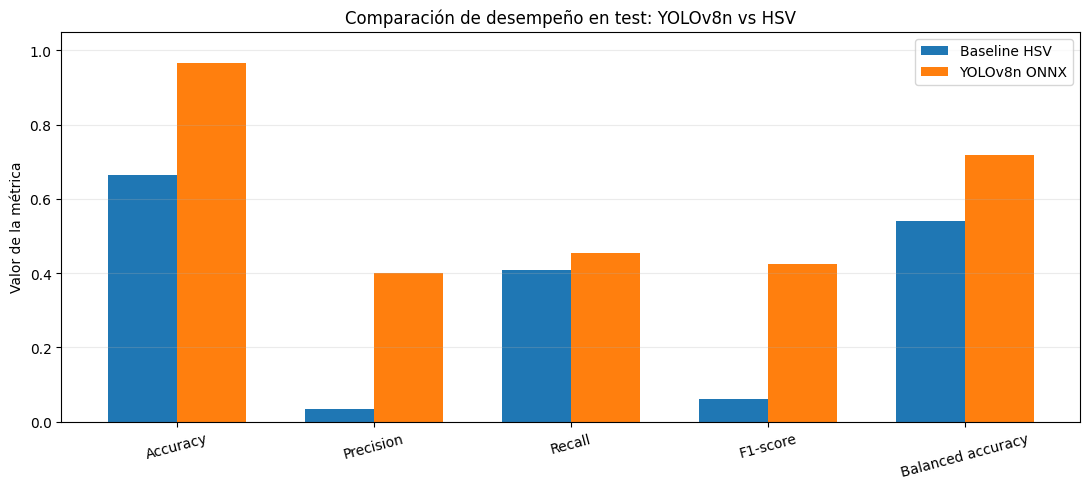

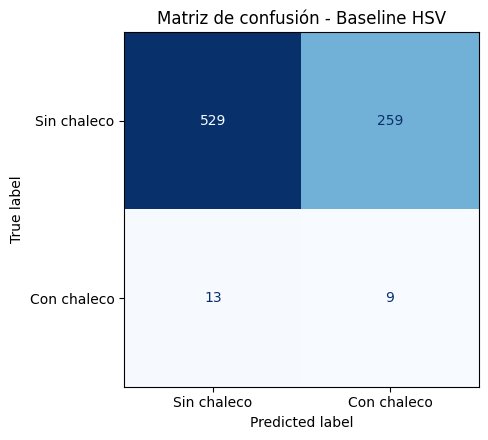

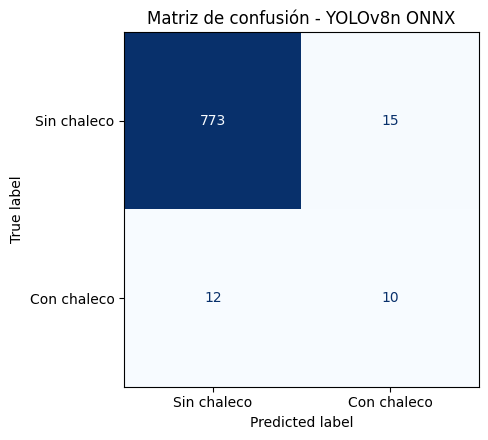


RESULTADO PRINCIPAL
---------------------------------------------
Mayor F1-score: YOLOv8n ONNX
Valor: 0.4255

Archivos guardados en: /content/drive/MyDrive/Examen_Hito2_EPP/Evaluaciones/Comparacion_HSV_YOLO_Hito2_v1
Comparación cuantitativa completada.
No se ejecutaron nuevas inferencias.


In [49]:

# ============================================================
# 4.5. COMPARACIÓN CUANTITATIVA YOLOv8n VS BASELINE HSV
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from IPython.display import display


# ------------------------------------------------------------
# 1. RECUPERAR PREDICCIONES GUARDADAS
# ------------------------------------------------------------

ARCHIVO_HSV = (
    SALIDA / "predicciones_baseline_test_v1_640.csv"
)

ARCHIVO_YOLO = (
    SALIDA / "predicciones_yolo_test_onnx_cpu_v1.csv"
)

if not ARCHIVO_HSV.is_file():
    raise FileNotFoundError(
        f"No se encontró el CSV HSV: {ARCHIVO_HSV}"
    )

if not ARCHIVO_YOLO.is_file():
    raise FileNotFoundError(
        f"No se encontró el CSV YOLO: {ARCHIVO_YOLO}"
    )

hsv = pd.read_csv(ARCHIVO_HSV)
yolo = pd.read_csv(ARCHIVO_YOLO)


# ==========================================
# VERIFICAR PROCEDENCIA - HITO 2
# ==========================================

import json
import hashlib

assert SALIDA.resolve().is_relative_to(
    CARPETA_HITO2.resolve()
)

assert MODELO_ONNX.is_file()
assert "modelo_id" in yolo.columns

with open(
    SALIDA / "umbral_baseline_hsv_v1_640.json",
    encoding="utf-8"
) as f:
    config_hsv = json.load(f)

umbral_verificado = float(
    config_hsv["umbral_final"]
)

assert config_hsv["imagenes_validacion"] == 810
assert config_hsv["positivos_validacion"] == 23
assert config_hsv["id_clase"] == 16

# Las predicciones HSV deben utilizar
# el umbral seleccionado en validación.

assert (
    hsv["pred_baseline"].to_numpy()
    == (
        hsv["fraccion_color"].to_numpy()
        >= umbral_verificado
    ).astype(int)
).all(), "Las predicciones HSV no coinciden con el umbral."

# Verificar modelo ONNX usado en 4.4B

hash_actual = hashlib.sha256()

with open(MODELO_ONNX, "rb") as f:
    for bloque in iter(
        lambda: f.read(1024 * 1024),
        b""
    ):
        hash_actual.update(bloque)

modelo_id_esperado = (
    f"sha256_{hash_actual.hexdigest()}_"
    "conf_0.40_presencia_raw_v1"
)

assert yolo["modelo_id"].astype(str).eq(
    modelo_id_esperado
).all(), (
    "Las predicciones YOLO no corresponden "
    "al modelo ONNX y configuración del Hito 2."
)

print("PROCEDENCIA DE RESULTADOS VERIFICADA")
print("Umbral HSV:", umbral_verificado)
print("Confianza YOLO: 0.40")
print("Modelo ONNX: SHA-256 verificado")


columnas_hsv = {
    "imagen", "real", "pred_baseline",
    "fraccion_color", "segundos_baseline"
}

columnas_yolo = {
    "imagen", "real", "pred_yolo",
    "segundos_yolo"
}

assert columnas_hsv.issubset(hsv.columns)
assert columnas_yolo.issubset(yolo.columns)

assert len(hsv) == len(yolo) == 810

assert hsv["imagen"].is_unique
assert yolo["imagen"].is_unique


# ------------------------------------------------------------
# 2. UNIR RESULTADOS POR NOMBRE DE IMAGEN
# ------------------------------------------------------------

comparacion = hsv[
    [
        "imagen", "real", "pred_baseline",
        "fraccion_color", "segundos_baseline"
    ]
].merge(
    yolo[
        [
            "imagen", "real", "pred_yolo",
            "segundos_yolo"
        ]
    ],
    on="imagen",
    how="outer",
    suffixes=("_hsv", "_yolo"),
    validate="one_to_one",
    indicator=True
)

assert len(comparacion) == 810

assert comparacion["_merge"].eq("both").all(), (
    "Las imágenes no coinciden entre ambos métodos."
)

comparacion = comparacion.drop(columns="_merge")

# Verificar que las etiquetas sean idénticas
assert (
    comparacion["real_hsv"]
    == comparacion["real_yolo"]
).all(), "Existen discrepancias en las etiquetas reales."

comparacion["real"] = (
    comparacion["real_hsv"].astype(int)
)

comparacion = comparacion.drop(
    columns=["real_hsv", "real_yolo"]
)

# Verificar valores válidos
for columna in ["real", "pred_baseline", "pred_yolo"]:
    assert comparacion[columna].notna().all()
    assert comparacion[columna].isin([0, 1]).all()

for columna in ["segundos_baseline", "segundos_yolo"]:
    assert comparacion[columna].notna().all()
    assert comparacion[columna].ge(0).all()

assert comparacion["real"].sum() == 22

print("VERIFICACIÓN DE DATOS")
print("-" * 45)
print("Imágenes coincidentes:", len(comparacion))
print("Positivos reales:", int(comparacion["real"].sum()))
print("Etiquetas coincidentes: Sí")


# ------------------------------------------------------------
# 3. FUNCIÓN DE EVALUACIÓN BINARIA
# ------------------------------------------------------------

def calcular_metricas(y_real, y_pred, nombre, tiempos):

    tn, fp, fn, tp = confusion_matrix(
        y_real,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision": precision_score(
            y_real, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_real, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_real, y_pred, zero_division=0
        ),
        "Balanced accuracy": balanced_accuracy_score(
            y_real, y_pred
        ),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
        "Positivos predichos": int(np.sum(y_pred)),
        "Tiempo promedio (s)": float(np.mean(tiempos)),
        "Tiempo total (s)": float(np.sum(tiempos))
    }


# ------------------------------------------------------------
# 4. CALCULAR MÉTRICAS DE AMBOS MÉTODOS
# ------------------------------------------------------------

y_real = comparacion["real"].to_numpy()

pred_hsv = comparacion["pred_baseline"].to_numpy()
pred_yolo = comparacion["pred_yolo"].to_numpy()

metricas_hsv = calcular_metricas(
    y_real,
    pred_hsv,
    "Baseline HSV",
    comparacion["segundos_baseline"].to_numpy()
)

metricas_yolo = calcular_metricas(
    y_real,
    pred_yolo,
    "YOLOv8n ONNX",
    comparacion["segundos_yolo"].to_numpy()
)

resumen = pd.DataFrame([
    metricas_hsv,
    metricas_yolo
])

print("\nCOMPARACIÓN DE MÉTRICAS")
print("-" * 45)

display(
    resumen[
        [
            "Modelo",
            "Accuracy",
            "Precision",
            "Recall",
            "F1-score",
            "Balanced accuracy"
        ]
    ].round(4)
)

print("\nMATRIZ DE RESULTADOS")
print("-" * 45)

display(
    resumen[
        [
            "Modelo", "TP", "FP", "FN", "TN",
            "Positivos predichos"
        ]
    ]
)

print("\nCOMPARACIÓN DE TIEMPOS")
print("-" * 45)

display(
    resumen[
        [
            "Modelo",
            "Tiempo promedio (s)",
            "Tiempo total (s)"
        ]
    ].round(4)
)

# Accuracy de referencia clasificando todo como negativo
accuracy_referencia = float(np.mean(y_real == 0))

print(
    "\nAccuracy de clasificar todo como negativo:",
    round(accuracy_referencia, 4)
)


# ------------------------------------------------------------
# 5. GUARDAR TABLAS DE RESULTADOS
# ------------------------------------------------------------

ARCHIVO_RESUMEN = (
    SALIDA / "comparacion_yolo_vs_hsv_test.csv"
)

ARCHIVO_DETALLE = (
    SALIDA / "detalle_comparacion_test.csv"
)


# ==========================================
# PROTEGER EVIDENCIAS EXISTENTES
# ==========================================

archivos_salida = [
    ARCHIVO_RESUMEN,
    ARCHIVO_DETALLE,
    SALIDA / "grafico_metricas_comparacion.png",
    SALIDA / "matriz_confusion_hsv.png",
    SALIDA / "matriz_confusion_yolo.png"
]

for archivo in archivos_salida:
    assert not archivo.exists(), (
        f"Ya existe un resultado: {archivo}. "
        "No se sobrescribirá. Para una nueva "
        "evaluación, utiliza otra carpeta."
    )

print("Destinos disponibles. Sin sobrescrituras.")


resumen.to_csv(
    ARCHIVO_RESUMEN, index=False
)

comparacion.to_csv(
    ARCHIVO_DETALLE, index=False
)

print("\nTablas guardadas correctamente.")


# ------------------------------------------------------------
# 6. GRÁFICO COMPARATIVO DE MÉTRICAS
# ------------------------------------------------------------

indicadores = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "Balanced accuracy"
]

posiciones = np.arange(len(indicadores))
ancho_barra = 0.35

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    posiciones - ancho_barra / 2,
    [metricas_hsv[c] for c in indicadores],
    width=ancho_barra,
    label="Baseline HSV"
)

ax.bar(
    posiciones + ancho_barra / 2,
    [metricas_yolo[c] for c in indicadores],
    width=ancho_barra,
    label="YOLOv8n ONNX"
)

ax.set_xticks(posiciones)
ax.set_xticklabels(indicadores, rotation=15)
ax.set_ylim(0, 1.05)

ax.set_ylabel("Valor de la métrica")
ax.set_title(
    "Comparación de desempeño en test: YOLOv8n vs HSV"
)

ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    SALIDA / "grafico_metricas_comparacion.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 7. MATRICES DE CONFUSIÓN
# ------------------------------------------------------------

modelos = [
    ("Baseline HSV", pred_hsv, "matriz_confusion_hsv.png"),
    ("YOLOv8n ONNX", pred_yolo, "matriz_confusion_yolo.png")
]

for nombre, predicciones, archivo in modelos:

    matriz = confusion_matrix(
        y_real,
        predicciones,
        labels=[0, 1]
    )

    fig, ax = plt.subplots(figsize=(5.5, 4.5))

    visualizador = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=[
            "Sin chaleco",
            "Con chaleco"
        ]
    )

    visualizador.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(f"Matriz de confusión - {nombre}")

    plt.tight_layout()

    plt.savefig(
        SALIDA / archivo,
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 8. IDENTIFICAR MEJOR F1-SCORE
# ------------------------------------------------------------

mejor = resumen.loc[
    resumen["F1-score"].idxmax()
]

print("\nRESULTADO PRINCIPAL")
print("-" * 45)

print("Mayor F1-score:", mejor["Modelo"])
print("Valor:", round(float(mejor["F1-score"]), 4))

print("\nArchivos guardados en:", SALIDA)
print("Comparación cuantitativa completada.")
print("No se ejecutaron nuevas inferencias.")



## 4.6. Análisis e interpretación de los resultados

Esta sección presenta la interpretación de la comparación cuantitativa entre YOLOv8n ONNX y el baseline HSV, conservando la metodología aprobada durante el Hito 1.

Los resultados definitivos del Hito 2 se obtendrán automáticamente desde los archivos de evaluación de la sección 4.5, evitando utilizar métricas de un entrenamiento anterior como si correspondieran al nuevo modelo.

### 4.6.1. Desempeño general de los métodos

Se analizarán Accuracy, Precision, Recall, F1-score y Balanced accuracy, utilizando el F1-score de la clase positiva como indicador principal.

Se comparará la capacidad de ambos métodos para identificar fotografías que contienen al menos un chaleco de seguridad.

La superioridad de un método solamente se establecerá a partir de los resultados efectivamente obtenidos.

### 4.6.2. Análisis de las matrices de confusión

Se examinarán los verdaderos positivos, falsos positivos, falsos negativos y verdaderos negativos de ambos métodos.

Se prestará especial atención a los falsos negativos, ya que representan fotografías con chalecos presentes que el procedimiento no consiguió identificar.

También se analizará la cantidad de falsos positivos, que puede afectar la interpretación de los resultados y la carga de trabajo del supervisor.

### 4.6.3. Efecto del desbalance de clases

El conjunto de test contiene 810 imágenes, de las cuales solamente 22 presentan anotaciones de `safety-vest`.

Este desbalance implica que una accuracy elevada no garantiza un buen reconocimiento de la clase positiva.

Por esta razón, se priorizará la interpretación del F1-score, complementada con Precision, Recall, Balanced accuracy y matrices de confusión.

### 4.6.4. Comparación de tiempos de procesamiento

Se compararán los tiempos promedio y totales registrados para ambos métodos.

Los valores corresponden al entorno de ejecución de Google Colab y no constituyen una prueba de rendimiento controlada.

### 4.6.5. Limitaciones de la evaluación

La evaluación presenta las siguientes limitaciones:

- Solamente existen 22 fotografías positivas en test.
- La comparación mide presencia de chaleco por imagen, no su asociación a personas.
- La inferencia binaria YOLO utiliza un criterio simplificado sin NMS.
- La comparación no evalúa los cinco EPP prioritarios ni el funcionamiento completo de ambas zonas.
- La precisión de las cajas delimitadoras y la categoría `person` se evalúan mediante procedimientos diferentes.
- Las métricas no permiten concluir que un trabajador cumple o incumple definitivamente los requisitos de seguridad.

El análisis completo del Hito 2 se complementará con la evaluación del detector por categoría, las asociaciones por trabajador, las pruebas de la API y la revisión humana.

### 4.6.6. Conclusión de la comparación

La conclusión definitiva será generada utilizando los resultados de la sección 4.5.

Se determinará cuál de los dos métodos presenta mayor F1-score y se interpretarán sus diferencias en Precision, Recall, falsos positivos, falsos negativos y tiempo de procesamiento.

No se afirmará que YOLOv8n mejora al baseline HSV sin comprobar previamente las métricas del nuevo entrenamiento.

**Referencia histórica del Hito 1**

En la comparación previamente aprobada, YOLOv8n obtuvo un F1-score de 0,5263 y un Recall de 45,45 %, mientras que HSV obtuvo un F1-score de 0,0621 y un Recall de 40,91 %.

Estos resultados respaldaron originalmente la selección de YOLOv8n. Se conservan como antecedente histórico, pero no corresponden necesariamente a la nueva partición de datos ni al modelo del Hito 2.

**Generación del informe definitivo**

La siguiente celda generará automáticamente el análisis cuantitativo y la conclusión utilizando el archivo `comparacion_yolo_vs_hsv_test.csv`.

El informe resultante se almacenará como `analisis_resultados_hito2.md` dentro de la carpeta de evaluaciones del Hito 2.


In [50]:

# ============================================================
# 4.6. GENERACIÓN DEL ANÁLISIS FINAL - HITO 2
# ============================================================

import pandas as pd
from pathlib import Path
from IPython.display import Markdown, display

# ==========================================
# 1. RECUPERAR COMPARACIÓN
# ==========================================

ARCHIVO_RESUMEN = (
    SALIDA / "comparacion_yolo_vs_hsv_test.csv"
)

ARCHIVO_ANALISIS = (
    SALIDA / "analisis_resultados_hito2.md"
)

assert ARCHIVO_RESUMEN.is_file()

assert ARCHIVO_ANALISIS.resolve().is_relative_to(
    CARPETA_HITO2.resolve()
)

assert not ARCHIVO_ANALISIS.exists(), (
    "El análisis ya existe. No se sobrescribirá."
)

tabla = pd.read_csv(ARCHIVO_RESUMEN)

assert set(tabla["Modelo"]) == {
    "Baseline HSV",
    "YOLOv8n ONNX"
}

assert len(tabla) == 2

hsv = tabla.set_index("Modelo").loc["Baseline HSV"]
yolo = tabla.set_index("Modelo").loc["YOLOv8n ONNX"]

for metrica in ["TP", "FP", "FN", "TN"]:

    assert hsv[metrica] >= 0
    assert yolo[metrica] >= 0

assert sum(
    int(hsv[x]) for x in ["TP", "FP", "FN", "TN"]
) == 810

assert sum(
    int(yolo[x]) for x in ["TP", "FP", "FN", "TN"]
) == 810

assert int(hsv["TP"] + hsv["FN"]) == 22
assert int(yolo["TP"] + yolo["FN"]) == 22

# ==========================================
# 2. FORMATO DE RESULTADOS
# ==========================================

def porcentaje(valor):
    return f"{100 * float(valor):.2f}%"

def decimal(valor):
    return f"{float(valor):.4f}"

def entero(valor):
    return int(valor)

f1_hsv = float(hsv["F1-score"])
f1_yolo = float(yolo["F1-score"])

recall_hsv = float(hsv["Recall"])
recall_yolo = float(yolo["Recall"])

fp_hsv = entero(hsv["FP"])
fp_yolo = entero(yolo["FP"])

tiempo_hsv = float(hsv["Tiempo promedio (s)"])
tiempo_yolo = float(yolo["Tiempo promedio (s)"])

# ==========================================
# 3. INTERPRETAR RESULTADOS
# ==========================================

if f1_yolo > f1_hsv:

    conclusion_principal = (
        "YOLOv8n ONNX obtuvo un F1-score superior "
        "al baseline HSV en el conjunto evaluado."
    )

elif f1_yolo < f1_hsv:

    conclusion_principal = (
        "El baseline HSV obtuvo un F1-score superior "
        "al modelo YOLOv8n ONNX. Por tanto, "
        "no se puede afirmar que YOLO haya superado "
        "al método tradicional en esta evaluación."
    )

else:

    conclusion_principal = (
        "Ambos métodos obtuvieron el mismo F1-score."
    )

if recall_yolo > recall_hsv:
    comparacion_recall = (
        "YOLOv8n presentó mayor Recall que HSV."
    )
elif recall_yolo < recall_hsv:
    comparacion_recall = (
        "YOLOv8n presentó menor Recall que HSV."
    )
else:
    comparacion_recall = (
        "Ambos métodos obtuvieron el mismo Recall."
    )

if fp_hsv > 0:

    variacion_fp = (
        100 * (fp_hsv - fp_yolo) / fp_hsv
    )

    if variacion_fp >= 0:
        comentario_fp = (
            f"YOLOv8n redujo los falsos positivos "
            f"en {variacion_fp:.2f}% respecto de HSV."
        )
    else:
        comentario_fp = (
            f"YOLOv8n incrementó los falsos positivos "
            f"en {abs(variacion_fp):.2f}% respecto de HSV."
        )

else:

    comentario_fp = (
        "HSV no presentó falsos positivos, "
        "por lo que no corresponde calcular "
        "una reducción porcentual respecto de él."
    )

if tiempo_hsv > 0:

    variacion_tiempo = (
        100 * (tiempo_yolo - tiempo_hsv)
        / tiempo_hsv
    )

    comentario_tiempo = (
        f"La diferencia relativa de tiempo "
        f"fue de {variacion_tiempo:+.2f}% "
        f"para YOLOv8n respecto de HSV."
    )

else:

    comentario_tiempo = (
        "No fue posible calcular la variación "
        "relativa del tiempo de procesamiento."
    )

# ==========================================
# 4. CONSTRUIR ANÁLISIS
# ==========================================

texto_analisis = f"""
## 4.6. Análisis e interpretación de los resultados — Hito 2

### 4.6.1. Desempeño general de los métodos

La evaluación consideró 810 imágenes del conjunto de test de SH17, de las cuales 22 contenían al menos un chaleco de seguridad.

| Indicador | Baseline HSV | YOLOv8n ONNX |
|---|---:|---:|
| Accuracy | {porcentaje(hsv["Accuracy"])} | {porcentaje(yolo["Accuracy"])} |
| Precision | {porcentaje(hsv["Precision"])} | {porcentaje(yolo["Precision"])} |
| Recall | {porcentaje(hsv["Recall"])} | {porcentaje(yolo["Recall"])} |
| F1-score | {decimal(hsv["F1-score"])} | {decimal(yolo["F1-score"])} |
| Balanced accuracy | {porcentaje(hsv["Balanced accuracy"])} | {porcentaje(yolo["Balanced accuracy"])} |

{conclusion_principal}

{comparacion_recall}

### 4.6.2. Análisis de las matrices de confusión

El baseline HSV obtuvo:

- Verdaderos positivos: {entero(hsv["TP"])}.
- Falsos positivos: {entero(hsv["FP"])}.
- Falsos negativos: {entero(hsv["FN"])}.
- Verdaderos negativos: {entero(hsv["TN"])}.

YOLOv8n ONNX obtuvo:

- Verdaderos positivos: {entero(yolo["TP"])}.
- Falsos positivos: {entero(yolo["FP"])}.
- Falsos negativos: {entero(yolo["FN"])}.
- Verdaderos negativos: {entero(yolo["TN"])}.

{comentario_fp}

Los falsos negativos requieren especial atención, ya que representan fotografías donde existe un chaleco anotado, pero el procedimiento no consiguió reconocer su presencia.

### 4.6.3. Efecto del desbalance de clases

Solamente 22 de las 810 imágenes contienen anotaciones de chalecos, equivalentes al {100 * 22 / 810:.2f}% del conjunto.

Un clasificador que predijera todos los casos como negativos alcanzaría una Accuracy de {100 * 788 / 810:.2f}%, sin detectar ningún caso positivo.

Por esta razón, el F1-score y el Recall son necesarios para interpretar correctamente el desempeño.

### 4.6.4. Comparación de tiempos de procesamiento

El baseline HSV registró un tiempo promedio de {tiempo_hsv:.4f} segundos por imagen.

YOLOv8n ONNX registró un tiempo promedio de {tiempo_yolo:.4f} segundos por imagen.

{comentario_tiempo}

Estos tiempos corresponden a las ejecuciones en Google Colab y deben interpretarse como referencias operacionales, no como una comparación controlada de rendimiento.

### 4.6.5. Limitaciones de la evaluación

La cantidad de imágenes positivas es reducida, por lo que unas pocas predicciones adicionales pueden modificar considerablemente las métricas.

La evaluación corresponde a clasificación binaria de presencia de chalecos a nivel de imagen, no a la verificación individual de su utilización por trabajadores.

El procedimiento ONNX utiliza un criterio simplificado de presencia de chalecos sin NMS. Tampoco evalúa de manera directa la calidad de las cajas, los demás EPP ni las reglas de ambas zonas.

Los resultados no determinan incumplimientos confirmados y deben complementarse con la evaluación por categoría, las asociaciones por persona y la revisión humana.

### 4.6.6. Conclusión de la comparación

{conclusion_principal}

El Recall de YOLOv8n fue de {porcentaje(yolo["Recall"])}, con {entero(yolo["FN"])} falsos negativos entre las 22 imágenes positivas.

Estos resultados deben considerarse al interpretar la capacidad del sistema para identificar chalecos presentes en fotografías.

La comparación permite evaluar la utilidad del detector frente a un método simple, pero no demuestra por sí sola que el sistema pueda supervisar autónomamente el uso correcto de EPP.

### Referencia histórica

Durante el Hito 1 se reportaron F1-score de 0,5263 para YOLOv8n y 0,0621 para HSV, con Recall de 45,45% y 40,91%, respectivamente.

Esos valores pertenecen a la comparación anteriormente aprobada. Las cifras actuales corresponden exclusivamente a la evaluación del Hito 2 y no deben confundirse con la referencia histórica.
""".strip()

# ==========================================
# 5. GUARDAR INFORME
# ==========================================

with open(
    ARCHIVO_ANALISIS,
    "x",
    encoding="utf-8"
) as f:

    f.write(texto_analisis)

print("ANÁLISIS DEL HITO 2 GENERADO")
print("Archivo:", ARCHIVO_ANALISIS)

display(Markdown(texto_analisis))


ANÁLISIS DEL HITO 2 GENERADO
Archivo: /content/drive/MyDrive/Examen_Hito2_EPP/Evaluaciones/Comparacion_HSV_YOLO_Hito2_v1/analisis_resultados_hito2.md


## 4.6. Análisis e interpretación de los resultados — Hito 2

### 4.6.1. Desempeño general de los métodos

La evaluación consideró 810 imágenes del conjunto de test de SH17, de las cuales 22 contenían al menos un chaleco de seguridad.

| Indicador | Baseline HSV | YOLOv8n ONNX |
|---|---:|---:|
| Accuracy | 66.42% | 96.67% |
| Precision | 3.36% | 40.00% |
| Recall | 40.91% | 45.45% |
| F1-score | 0.0621 | 0.4255 |
| Balanced accuracy | 54.02% | 71.78% |

YOLOv8n ONNX obtuvo un F1-score superior al baseline HSV en el conjunto evaluado.

YOLOv8n presentó mayor Recall que HSV.

### 4.6.2. Análisis de las matrices de confusión

El baseline HSV obtuvo:

- Verdaderos positivos: 9.
- Falsos positivos: 259.
- Falsos negativos: 13.
- Verdaderos negativos: 529.

YOLOv8n ONNX obtuvo:

- Verdaderos positivos: 10.
- Falsos positivos: 15.
- Falsos negativos: 12.
- Verdaderos negativos: 773.

YOLOv8n redujo los falsos positivos en 94.21% respecto de HSV.

Los falsos negativos requieren especial atención, ya que representan fotografías donde existe un chaleco anotado, pero el procedimiento no consiguió reconocer su presencia.

### 4.6.3. Efecto del desbalance de clases

Solamente 22 de las 810 imágenes contienen anotaciones de chalecos, equivalentes al 2.72% del conjunto.

Un clasificador que predijera todos los casos como negativos alcanzaría una Accuracy de 97.28%, sin detectar ningún caso positivo.

Por esta razón, el F1-score y el Recall son necesarios para interpretar correctamente el desempeño.

### 4.6.4. Comparación de tiempos de procesamiento

El baseline HSV registró un tiempo promedio de 0.5190 segundos por imagen.

YOLOv8n ONNX registró un tiempo promedio de 0.6618 segundos por imagen.

La diferencia relativa de tiempo fue de +27.52% para YOLOv8n respecto de HSV.

Estos tiempos corresponden a las ejecuciones en Google Colab y deben interpretarse como referencias operacionales, no como una comparación controlada de rendimiento.

### 4.6.5. Limitaciones de la evaluación

La cantidad de imágenes positivas es reducida, por lo que unas pocas predicciones adicionales pueden modificar considerablemente las métricas.

La evaluación corresponde a clasificación binaria de presencia de chalecos a nivel de imagen, no a la verificación individual de su utilización por trabajadores.

El procedimiento ONNX utiliza un criterio simplificado de presencia de chalecos sin NMS. Tampoco evalúa de manera directa la calidad de las cajas, los demás EPP ni las reglas de ambas zonas.

Los resultados no determinan incumplimientos confirmados y deben complementarse con la evaluación por categoría, las asociaciones por persona y la revisión humana.

### 4.6.6. Conclusión de la comparación

YOLOv8n ONNX obtuvo un F1-score superior al baseline HSV en el conjunto evaluado.

El Recall de YOLOv8n fue de 45.45%, con 12 falsos negativos entre las 22 imágenes positivas.

Estos resultados deben considerarse al interpretar la capacidad del sistema para identificar chalecos presentes en fotografías.

La comparación permite evaluar la utilidad del detector frente a un método simple, pero no demuestra por sí sola que el sistema pueda supervisar autónomamente el uso correcto de EPP.

### Referencia histórica

Durante el Hito 1 se reportaron F1-score de 0,5263 para YOLOv8n y 0,0621 para HSV, con Recall de 45,45% y 40,91%, respectivamente.

Esos valores pertenecen a la comparación anteriormente aprobada. Las cifras actuales corresponden exclusivamente a la evaluación del Hito 2 y no deben confundirse con la referencia histórica.